# Experiment scope and interpretation

The standard machine-learning and ANN sections in this notebook use same-year crime counts to classify a target constructed from same-year IPC counts, with stratified random splits. Treat these as observed-year classification / target reconstruction experiments, not forecasts of future-year violent-crime burden. Their scores are not forecasting performance. The temporal forecasting experiment uses inputs from years strictly before the target year and the designated 2001-2010 / 2011-2012 / 2013-2014 target-year partitions.

The 2014 raw-stage source discrepancy remains unresolved; see the data integration audit before interpreting coverage.

In [1]:
# ============================================================
# BASE PAPER PREDICTION MODELS
# STEP 7 — FINAL DATASET LOADING
# ============================================================

import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.naive_bayes import GaussianNB
from sklearn.tree import ExtraTreeClassifier
from sklearn.multiclass import OneVsRestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score
)

import matplotlib.pyplot as plt
import seaborn as sns


# ============================================================
# PROJECT PATHS
# ============================================================

PROJECT_ROOT = Path.cwd().parent

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "district_grouped_reduced.csv"
)

OUTPUT_DIR = PROJECT_ROOT / "outputs"

FIGURES_DIR = OUTPUT_DIR / "figures"
TABLES_DIR = OUTPUT_DIR / "tables"

FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

TABLES_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# FINAL DATASET COLUMNS
# ============================================================

TARGET = "TARGET_VIOLENT_LEVEL"

GROUP_COLUMNS = [
    "GROUP_HOMICIDE",
    "GROUP_SEXUAL_VIOLENCE",
    "GROUP_KIDNAPPING_ABDUCTION",
    "GROUP_ROBBERY_DACOITY",
    "GROUP_PUBLIC_VIOLENCE",
    "GROUP_PROPERTY_CRIME",
]

METADATA_COLUMNS = [
    "YEAR",
    "STATE",
    "UNIT_NAME",
]

EXPECTED_COLUMNS = (
    METADATA_COLUMNS
    + GROUP_COLUMNS
    + [TARGET]
)


print("=" * 70)
print("BASE PAPER ML PIPELINE")
print("=" * 70)

print("\nProject root:")
print(PROJECT_ROOT)

print("\nFinal dataset:")
print(DATA_PATH)

BASE PAPER ML PIPELINE

Project root:
d:\Major_Project\Crime_Analysis

Final dataset:
d:\Major_Project\Crime_Analysis\data\processed\district_grouped_reduced.csv


In [2]:
# ============================================================
# STEP 7 — LOAD FINAL REDUCED DATASET
# ============================================================

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)

print("\nDataset columns:")
for col in df.columns:
    print("-", col)

print("\nFirst 5 rows:")
display(df.head())

Dataset shape: (9856, 10)

Dataset columns:
- YEAR
- STATE
- UNIT_NAME
- GROUP_HOMICIDE
- GROUP_SEXUAL_VIOLENCE
- GROUP_KIDNAPPING_ABDUCTION
- GROUP_ROBBERY_DACOITY
- GROUP_PUBLIC_VIOLENCE
- GROUP_PROPERTY_CRIME
- TARGET_VIOLENT_LEVEL

First 5 rows:


,YEAR,STATE,UNIT_NAME,GROUP_HOMICIDE,GROUP_SEXUAL_VIOLENCE,GROUP_KIDNAPPING_ABDUCTION,GROUP_ROBBERY_DACOITY,GROUP_PUBLIC_VIOLENCE,GROUP_PROPERTY_CRIME,TARGET_VIOLENT_LEVEL
0,2001,ANDHRA PRADESH,ADILABAD,178.0,199.0,46.0,50.0,108.0,517.0,4.0
1,2001,ANDHRA PRADESH,ANANTAPUR,277.0,141.0,53.0,24.0,237.0,633.0,5.0
2,2001,ANDHRA PRADESH,CHITTOOR,160.0,139.0,59.0,18.0,194.0,1202.0,4.0
3,2001,ANDHRA PRADESH,CUDDAPAH,134.0,146.0,25.0,5.0,187.0,320.0,4.0
4,2001,ANDHRA PRADESH,EAST GODAVARI,150.0,132.0,49.0,29.0,111.0,1728.0,4.0


In [3]:
# ============================================================
# STEP 7 — VALIDATE FINAL DATASET
# ============================================================

print("=" * 70)
print("FINAL DATASET VALIDATION")
print("=" * 70)

# ------------------------------------------------------------
# Column validation
# ------------------------------------------------------------

missing_columns = [
    col
    for col in EXPECTED_COLUMNS
    if col not in df.columns
]

extra_columns = [
    col
    for col in df.columns
    if col not in EXPECTED_COLUMNS
]

print("\nMissing expected columns:")
print(missing_columns)

print("\nUnexpected extra columns:")
print(extra_columns)


if missing_columns:
    raise ValueError(
        f"Missing expected columns: {missing_columns}"
    )

if extra_columns:
    raise ValueError(
        f"Unexpected columns found: {extra_columns}"
    )


# ------------------------------------------------------------
# Target rows
# ------------------------------------------------------------

rows_before = len(df)

df = df.dropna(
    subset=[TARGET]
).copy()

df[TARGET] = df[TARGET].astype(int)

rows_after = len(df)

print("\nRows before removing missing target:", rows_before)
print("Rows after:", rows_after)
print("Rows removed:", rows_before - rows_after)


# ------------------------------------------------------------
# Target distribution
# ------------------------------------------------------------

print("\nTarget distribution:")
print(
    df[TARGET]
    .value_counts()
    .sort_index()
)


# ------------------------------------------------------------
# Predictor selection
# ------------------------------------------------------------

X = df[GROUP_COLUMNS].copy()

y = df[TARGET].copy()

print("\nPredictor columns:")
for col in GROUP_COLUMNS:
    print("-", col)

print("\nNumber of predictors:", len(GROUP_COLUMNS))

print("\nX shape:", X.shape)
print("y shape:", y.shape)

FINAL DATASET VALIDATION

Missing expected columns:
[]

Unexpected extra columns:
[]

Rows before removing missing target: 9856
Rows after: 9631
Rows removed: 225

Target distribution:
TARGET_VIOLENT_LEVEL
1    1927
2    1926
3    1926
4    1926
5    1926
Name: count, dtype: int64

Predictor columns:
- GROUP_HOMICIDE
- GROUP_SEXUAL_VIOLENCE
- GROUP_KIDNAPPING_ABDUCTION
- GROUP_ROBBERY_DACOITY
- GROUP_PUBLIC_VIOLENCE
- GROUP_PROPERTY_CRIME

Number of predictors: 6

X shape: (9631, 6)
y shape: (9631,)


In [4]:
# ============================================================
# STEP 8 — 80/20 TRAIN-TEST SPLIT
# ============================================================

print("=" * 70)
print("80/20 TRAIN-TEST SPLIT")
print("=" * 70)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining data:")
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("\nTesting data:")
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

print("\nTraining target distribution:")
print(
    y_train
    .value_counts()
    .sort_index()
)

print("\nTesting target distribution:")
print(
    y_test
    .value_counts()
    .sort_index()
)

print("\nTrain percentage:", len(X_train) / len(X) * 100)
print("Test percentage :", len(X_test) / len(X) * 100)

print("\n80/20 split completed successfully.")

80/20 TRAIN-TEST SPLIT

Training data:
X_train shape: (7704, 6)
y_train shape: (7704,)

Testing data:
X_test shape: (1927, 6)
y_test shape: (1927,)

Training target distribution:
TARGET_VIOLENT_LEVEL
1    1541
2    1541
3    1541
4    1540
5    1541
Name: count, dtype: int64

Testing target distribution:
TARGET_VIOLENT_LEVEL
1    386
2    385
3    385
4    386
5    385
Name: count, dtype: int64

Train percentage: 79.99169348977262
Test percentage : 20.008306510227392

80/20 split completed successfully.


In [5]:
# ============================================================
# STEP 9 — NAIVE BAYES
# ============================================================

print("=" * 70)
print("NAIVE BAYES MODEL")
print("=" * 70)

# ------------------------------------------------------------
# Handle missing predictor values using training medians
# ------------------------------------------------------------

nb_imputer = SimpleImputer(strategy="median")

X_train_nb = nb_imputer.fit_transform(X_train)
X_test_nb = nb_imputer.transform(X_test)

print("\nTraining shape after imputation:", X_train_nb.shape)
print("Testing shape after imputation :", X_test_nb.shape)


# ------------------------------------------------------------
# Train Gaussian Naive Bayes
# ------------------------------------------------------------

nb_model = GaussianNB()

nb_model.fit(
    X_train_nb,
    y_train
)


# ------------------------------------------------------------
# Predictions
# ------------------------------------------------------------

nb_pred = nb_model.predict(X_test_nb)

nb_prob = nb_model.predict_proba(X_test_nb)


# ------------------------------------------------------------
# Evaluation
# ------------------------------------------------------------

nb_accuracy = accuracy_score(
    y_test,
    nb_pred
)

nb_precision = precision_score(
    y_test,
    nb_pred,
    average="weighted",
    zero_division=0
)

nb_recall = recall_score(
    y_test,
    nb_pred,
    average="weighted",
    zero_division=0
)

nb_f1 = f1_score(
    y_test,
    nb_pred,
    average="weighted",
    zero_division=0
)

nb_roc_auc = roc_auc_score(
    y_test,
    nb_prob,
    multi_class="ovr",
    average="weighted"
)

nb_pr_auc = average_precision_score(
    pd.get_dummies(y_test),
    nb_prob,
    average="weighted"
)


# ------------------------------------------------------------
# Print results
# ------------------------------------------------------------

print("\nNaive Bayes Results")
print("-" * 70)

print(f"Accuracy  : {nb_accuracy:.4f}")
print(f"Precision : {nb_precision:.4f}")
print(f"Recall    : {nb_recall:.4f}")
print(f"F1-score  : {nb_f1:.4f}")
print(f"ROC-AUC   : {nb_roc_auc:.4f}")
print(f"PR-AUC    : {nb_pr_auc:.4f}")


# ------------------------------------------------------------
# Classification report
# ------------------------------------------------------------

print("\nClassification Report")
print("-" * 70)

print(
    classification_report(
        y_test,
        nb_pred,
        digits=4,
        zero_division=0
    )
)


# ------------------------------------------------------------
# Confusion matrix
# ------------------------------------------------------------

print("\nConfusion Matrix")
print("-" * 70)

nb_cm = confusion_matrix(
    y_test,
    nb_pred
)

display(
    pd.DataFrame(
        nb_cm,
        index=[f"Actual {i}" for i in sorted(y.unique())],
        columns=[f"Predicted {i}" for i in sorted(y.unique())]
    )
)

NAIVE BAYES MODEL

Training shape after imputation: (7704, 6)
Testing shape after imputation : (1927, 6)

Naive Bayes Results
----------------------------------------------------------------------
Accuracy  : 0.7447
Precision : 0.7896
Recall    : 0.7447
F1-score  : 0.7429
ROC-AUC   : 0.9446
PR-AUC    : 0.7881

Classification Report
----------------------------------------------------------------------
              precision    recall  f1-score   support

           1     0.9778    0.9145    0.9451       386
           2     0.7895    0.8571    0.8219       385
           3     0.6874    0.7481    0.7164       385
           4     0.5335    0.7642    0.6283       386
           5     0.9602    0.4390    0.6025       385

    accuracy                         0.7447      1927
   macro avg     0.7897    0.7446    0.7429      1927
weighted avg     0.7896    0.7447    0.7429      1927


Confusion Matrix
----------------------------------------------------------------------


,Predicted 1,Predicted 2,Predicted 3,Predicted 4,Predicted 5
Actual 1,353,30,2,1,0
Actual 2,8,330,43,4,0
Actual 3,0,58,288,37,2
Actual 4,0,0,86,295,5
Actual 5,0,0,0,216,169


In [6]:
# ============================================================
# STEP 10 — RANDOM TREE / EXTRA TREE CLASSIFIER
# ============================================================

print("=" * 70)
print("RANDOM TREE / EXTRA TREE MODEL")
print("=" * 70)


# ------------------------------------------------------------
# Handle missing predictor values
# ------------------------------------------------------------

tree_imputer = SimpleImputer(strategy="median")

X_train_tree = tree_imputer.fit_transform(X_train)
X_test_tree = tree_imputer.transform(X_test)

print("\nTraining shape after imputation:", X_train_tree.shape)
print("Testing shape after imputation :", X_test_tree.shape)


# ------------------------------------------------------------
# Train Extra Tree Classifier
# ------------------------------------------------------------

tree_model = ExtraTreeClassifier(
    random_state=42
)

tree_model.fit(
    X_train_tree,
    y_train
)


# ------------------------------------------------------------
# Predictions
# ------------------------------------------------------------

tree_pred = tree_model.predict(
    X_test_tree
)

tree_prob = tree_model.predict_proba(
    X_test_tree
)


# ------------------------------------------------------------
# Evaluation
# ------------------------------------------------------------

tree_accuracy = accuracy_score(
    y_test,
    tree_pred
)

tree_precision = precision_score(
    y_test,
    tree_pred,
    average="weighted",
    zero_division=0
)

tree_recall = recall_score(
    y_test,
    tree_pred,
    average="weighted",
    zero_division=0
)

tree_f1 = f1_score(
    y_test,
    tree_pred,
    average="weighted",
    zero_division=0
)

tree_roc_auc = roc_auc_score(
    y_test,
    tree_prob,
    multi_class="ovr",
    average="weighted"
)

tree_pr_auc = average_precision_score(
    pd.get_dummies(y_test),
    tree_prob,
    average="weighted"
)


# ------------------------------------------------------------
# Print results
# ------------------------------------------------------------

print("\nRandom Tree / Extra Tree Results")
print("-" * 70)

print(f"Accuracy  : {tree_accuracy:.4f}")
print(f"Precision : {tree_precision:.4f}")
print(f"Recall    : {tree_recall:.4f}")
print(f"F1-score  : {tree_f1:.4f}")
print(f"ROC-AUC   : {tree_roc_auc:.4f}")
print(f"PR-AUC    : {tree_pr_auc:.4f}")


# ------------------------------------------------------------
# Classification report
# ------------------------------------------------------------

print("\nClassification Report")
print("-" * 70)

print(
    classification_report(
        y_test,
        tree_pred,
        digits=4,
        zero_division=0
    )
)


# ------------------------------------------------------------
# Confusion matrix
# ------------------------------------------------------------

print("\nConfusion Matrix")
print("-" * 70)

tree_cm = confusion_matrix(
    y_test,
    tree_pred
)

display(
    pd.DataFrame(
        tree_cm,
        index=[f"Actual {i}" for i in sorted(y.unique())],
        columns=[f"Predicted {i}" for i in sorted(y.unique())]
    )
)

RANDOM TREE / EXTRA TREE MODEL

Training shape after imputation: (7704, 6)
Testing shape after imputation : (1927, 6)

Random Tree / Extra Tree Results
----------------------------------------------------------------------
Accuracy  : 0.7654
Precision : 0.7645
Recall    : 0.7654
F1-score  : 0.7649
ROC-AUC   : 0.8534
PR-AUC    : 0.6419

Classification Report
----------------------------------------------------------------------
              precision    recall  f1-score   support

           1     0.9072    0.9119    0.9096       386
           2     0.7266    0.7247    0.7256       385
           3     0.6541    0.6286    0.6411       385
           4     0.6911    0.7073    0.6991       386
           5     0.8436    0.8545    0.8490       385

    accuracy                         0.7654      1927
   macro avg     0.7645    0.7654    0.7649      1927
weighted avg     0.7645    0.7654    0.7649      1927


Confusion Matrix
--------------------------------------------------------------

,Predicted 1,Predicted 2,Predicted 3,Predicted 4,Predicted 5
Actual 1,352,32,2,0,0
Actual 2,35,279,69,2,0
Actual 3,1,68,242,68,6
Actual 4,0,5,53,273,55
Actual 5,0,0,4,52,329


In [7]:
# ============================================================
# STEP 11 — ONE-VS-REST GAUSSIAN NAIVE BAYES
# ============================================================

print("=" * 70)
print("ONE-VS-REST GAUSSIAN NAIVE BAYES")
print("=" * 70)


# ------------------------------------------------------------
# Handle missing predictor values
# ------------------------------------------------------------

ovr_imputer = SimpleImputer(strategy="median")

X_train_ovr = ovr_imputer.fit_transform(X_train)
X_test_ovr = ovr_imputer.transform(X_test)

print("\nTraining shape after imputation:", X_train_ovr.shape)
print("Testing shape after imputation :", X_test_ovr.shape)


# ------------------------------------------------------------
# Train One-vs-Rest Gaussian Naive Bayes
# ------------------------------------------------------------

ovr_model = OneVsRestClassifier(
    GaussianNB()
)

ovr_model.fit(
    X_train_ovr,
    y_train
)


# ------------------------------------------------------------
# Predictions
# ------------------------------------------------------------

ovr_pred = ovr_model.predict(
    X_test_ovr
)

ovr_prob = ovr_model.predict_proba(
    X_test_ovr
)


# ------------------------------------------------------------
# Evaluation
# ------------------------------------------------------------

ovr_accuracy = accuracy_score(
    y_test,
    ovr_pred
)

ovr_precision = precision_score(
    y_test,
    ovr_pred,
    average="weighted",
    zero_division=0
)

ovr_recall = recall_score(
    y_test,
    ovr_pred,
    average="weighted",
    zero_division=0
)

ovr_f1 = f1_score(
    y_test,
    ovr_pred,
    average="weighted",
    zero_division=0
)

ovr_roc_auc = roc_auc_score(
    y_test,
    ovr_prob,
    multi_class="ovr",
    average="weighted"
)

ovr_pr_auc = average_precision_score(
    pd.get_dummies(y_test),
    ovr_prob,
    average="weighted"
)


# ------------------------------------------------------------
# Print results
# ------------------------------------------------------------

print("\nOne-vs-Rest GaussianNB Results")
print("-" * 70)

print(f"Accuracy  : {ovr_accuracy:.4f}")
print(f"Precision : {ovr_precision:.4f}")
print(f"Recall    : {ovr_recall:.4f}")
print(f"F1-score  : {ovr_f1:.4f}")
print(f"ROC-AUC   : {ovr_roc_auc:.4f}")
print(f"PR-AUC    : {ovr_pr_auc:.4f}")


# ------------------------------------------------------------
# Classification report
# ------------------------------------------------------------

print("\nClassification Report")
print("-" * 70)

print(
    classification_report(
        y_test,
        ovr_pred,
        digits=4,
        zero_division=0
    )
)


# ------------------------------------------------------------
# Confusion matrix
# ------------------------------------------------------------

print("\nConfusion Matrix")
print("-" * 70)

ovr_cm = confusion_matrix(
    y_test,
    ovr_pred
)

display(
    pd.DataFrame(
        ovr_cm,
        index=[f"Actual {i}" for i in sorted(y.unique())],
        columns=[f"Predicted {i}" for i in sorted(y.unique())]
    )
)

ONE-VS-REST GAUSSIAN NAIVE BAYES

Training shape after imputation: (7704, 6)
Testing shape after imputation : (1927, 6)

One-vs-Rest GaussianNB Results
----------------------------------------------------------------------
Accuracy  : 0.7815
Precision : 0.8009
Recall    : 0.7815
F1-score  : 0.7844
ROC-AUC   : 0.8839
PR-AUC    : 0.6715

Classification Report
----------------------------------------------------------------------
              precision    recall  f1-score   support

           1     0.9751    0.9145    0.9439       386
           2     0.7895    0.8571    0.8219       385
           3     0.6881    0.7506    0.7180       385
           4     0.6187    0.7358    0.6722       386
           5     0.9328    0.6494    0.7657       385

    accuracy                         0.7815      1927
   macro avg     0.8009    0.7815    0.7843      1927
weighted avg     0.8009    0.7815    0.7844      1927


Confusion Matrix
--------------------------------------------------------------

,Predicted 1,Predicted 2,Predicted 3,Predicted 4,Predicted 5
Actual 1,353,30,2,1,0
Actual 2,9,330,42,4,0
Actual 3,0,58,289,35,3
Actual 4,0,0,87,284,15
Actual 5,0,0,0,135,250


In [8]:
# ============================================================
# STEP 12 — FINAL MODEL COMPARISON
# ============================================================

print("=" * 70)
print("FINAL MODEL COMPARISON")
print("=" * 70)

results = pd.DataFrame([
    {
        "Model": "Naive Bayes",
        "Accuracy": nb_accuracy,
        "Precision": nb_precision,
        "Recall": nb_recall,
        "F1_Score": nb_f1,
        "ROC_AUC": nb_roc_auc,
        "PR_AUC": nb_pr_auc
    },
    {
        "Model": "Random / Extra Tree",
        "Accuracy": tree_accuracy,
        "Precision": tree_precision,
        "Recall": tree_recall,
        "F1_Score": tree_f1,
        "ROC_AUC": tree_roc_auc,
        "PR_AUC": tree_pr_auc
    },
    {
        "Model": "One-vs-Rest GaussianNB",
        "Accuracy": ovr_accuracy,
        "Precision": ovr_precision,
        "Recall": ovr_recall,
        "F1_Score": ovr_f1,
        "ROC_AUC": ovr_roc_auc,
        "PR_AUC": ovr_pr_auc
    }
])

# Round for display
results_display = results.copy()

metric_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1_Score",
    "ROC_AUC",
    "PR_AUC"
]

results_display[metric_columns] = (
    results_display[metric_columns]
    .round(4)
)

print("\nModel comparison:")
display(results_display)


# ------------------------------------------------------------
# Save results
# ------------------------------------------------------------

results_path = (
    TABLES_DIR
    / "basepaper_final_model_comparison.csv"
)

results.to_csv(
    results_path,
    index=False
)

print("\nResults saved to:")
print(results_path)

print("\nModel comparison completed successfully.")

FINAL MODEL COMPARISON

Model comparison:


,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC
0,Naive Bayes,0.7447,0.7896,0.7447,0.7429,0.9446,0.7881
1,Random / Extra Tree,0.7654,0.7645,0.7654,0.7649,0.8534,0.6419
2,One-vs-Rest GaussianNB,0.7815,0.8009,0.7815,0.7844,0.8839,0.6715



Results saved to:
d:\Major_Project\Crime_Analysis\outputs\tables\basepaper_final_model_comparison.csv

Model comparison completed successfully.


MODEL PERFORMANCE VISUALIZATION


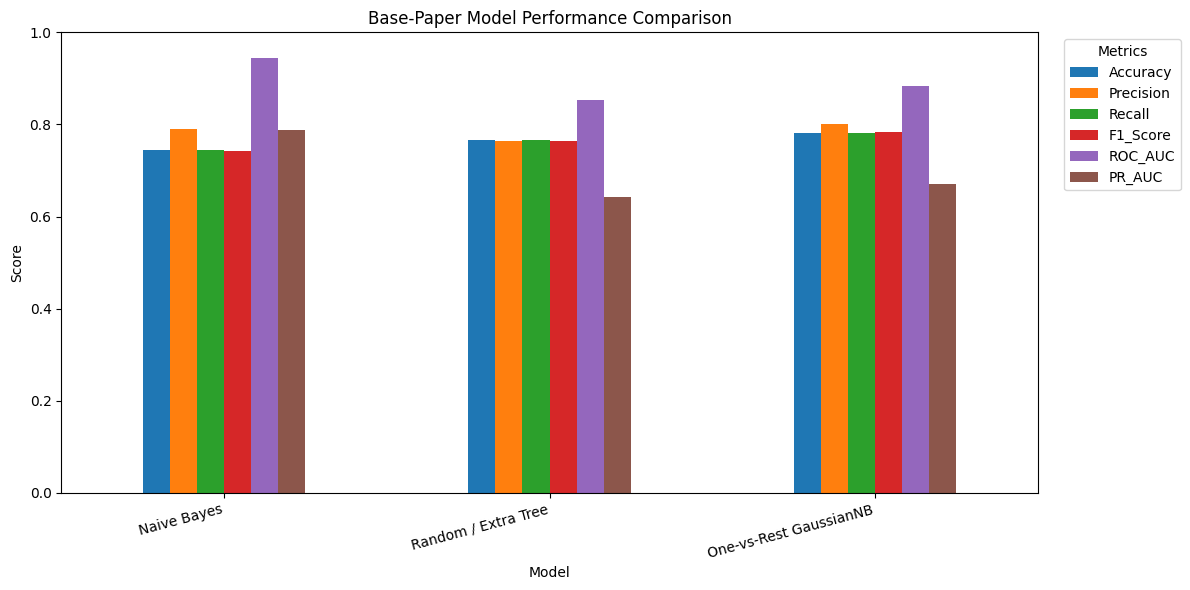


Figure saved to:
d:\Major_Project\Crime_Analysis\outputs\figures\basepaper_model_performance_comparison.png

Model performance visualization completed successfully.


In [9]:
# ============================================================
# STEP 13 — MODEL PERFORMANCE VISUALIZATION
# ============================================================

print("=" * 70)
print("MODEL PERFORMANCE VISUALIZATION")
print("=" * 70)

plot_metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1_Score",
    "ROC_AUC",
    "PR_AUC"
]

plot_df = results.copy()

# ------------------------------------------------------------
# Create one figure for model comparison
# ------------------------------------------------------------

ax = plot_df.set_index("Model")[plot_metrics].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title(
    "Base-Paper Model Performance Comparison"
)

plt.xlabel("Model")
plt.ylabel("Score")

plt.ylim(0, 1.0)

plt.xticks(
    rotation=15,
    ha="right"
)

plt.legend(
    title="Metrics",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

# ------------------------------------------------------------
# Save figure
# ------------------------------------------------------------

comparison_figure_path = (
    FIGURES_DIR
    / "basepaper_model_performance_comparison.png"
)

plt.savefig(
    comparison_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nFigure saved to:")
print(comparison_figure_path)

print("\nModel performance visualization completed successfully.")

# FINAL BASE-PAPER ML PIPELINE SUMMARY

## 1. Dataset

Final dataset:

`data/processed/district_grouped_reduced.csv`

The final reduced dataset contains:

- 9,856 total records
- 10 columns
- 6 grouped crime features
- 3 metadata features
- 1 target feature

The 225 records with missing target values were excluded only from model training/evaluation.

Therefore:

- Total records: 9,856
- Modeling records: 9,631
- Removed from modeling due to missing target: 225

---

## 2. Final Features

The six crime-group features used for prediction are:

1. `GROUP_HOMICIDE`
2. `GROUP_SEXUAL_VIOLENCE`
3. `GROUP_KIDNAPPING_ABDUCTION`
4. `GROUP_ROBBERY_DACOITY`
5. `GROUP_PUBLIC_VIOLENCE`
6. `GROUP_PROPERTY_CRIME`

Metadata columns:

- `YEAR`
- `STATE`
- `UNIT_NAME`

Target:

- `TARGET_VIOLENT_LEVEL`

The target was taken from the existing project target dataset and was not recreated or modified during this ML implementation.

---

## 3. Target Classes and Frozen Boundaries

`TARGET_VIOLENT_LEVEL` represents five ordered levels of violent-crime burden, not five crime types. This project-defined target is an adaptation; the original paper's target-generation procedure has not been independently verified.

- Class 1: Lowest violent-crime burden
- Class 2: Low-to-moderate violent-crime burden
- Class 3: Moderate violent-crime burden
- Class 4: Moderate-to-high violent-crime burden
- Class 5: Highest violent-crime burden

The four frozen burden cut points are 107, 237, 362, and 563, fitted on 2001–2010 training observations. Equal burdens receive the same class under the saved right-sided threshold assignment rule. The canonical labels and class distributions are saved in the processed target data and audit outputs.

## 4. Observed-Year Train-Test Split

An 80/20 stratified train-test split was used.

- Training records: 7,704
- Testing records: 1,927
- Number of predictors: 6

Stratification was used to preserve the class distribution between training and testing sets.

---

## 5. Models Implemented

The following models were implemented:

1. Gaussian Naive Bayes
2. Random Tree / Extra Tree Classifier
3. One-vs-Rest Gaussian Naive Bayes

The Random Tree implementation is an adaptation using `ExtraTreeClassifier`; it should not be described as an exact reproduction of the paper's implementation unless the paper's exact software implementation is available.

---

## 6. Model Evaluation

Each model was evaluated on the same held-out test set using:

- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC
- PR-AUC
- Classification report
- Confusion matrix

The final comparison was calculated directly from model predictions.

---

## 7. Final Model Results

The final comparison table is stored at:

`outputs/tables/basepaper_final_model_comparison.csv`

The visualization is stored at:

`outputs/figures/basepaper_model_performance_comparison.png`

---

## 8. Important Data Handling Decisions

The original integrated dataset was not overwritten.

The final reduced analytical dataset was saved separately as:

`data/processed/district_grouped_reduced.csv`

The six grouped crime features were created before model training.

The 225 records with missing target values were not assigned an artificial target value.

Missing grouped crime values were not blindly converted to zero.

Predictor preprocessing was fitted using the training data and then applied to the test data.

---

## 9. Final Pipeline

```text
Original Integrated Dataset
            ↓
Crime Category Grouping
            ↓
Dimensionality Reduction
            ↓
Final 10-Column Dataset
            ↓
Remove Rows with Missing Target
            ↓
9,631 Modeling Records
            ↓
6 Grouped Crime Features
            ↓
80/20 Stratified Train-Test Split
            ↓
Training-Only Imputation
            ↓
Naive Bayes
Random / Extra Tree
One-vs-Rest GaussianNB
            ↓
Predictions
            ↓
Evaluation Metrics
            ↓
Model Comparison
            ↓
Performance Visualization

In [ ]:
# ============================================================
# STEP 14 — SAME-YEAR ENHANCED CLASSIFICATION ? NOT A FORECAST
# ============================================================

print("=" * 70)
print("SAME-YEAR ENHANCED CLASSIFICATION ? NOT A FORECAST")
print("=" * 70)

# ------------------------------------------------------------
# Load enhanced dataset
# ------------------------------------------------------------

ENHANCED_DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "district_enhanced_features.csv"
)

enhanced_df = pd.read_csv(
    ENHANCED_DATA_PATH
)

print("\nEnhanced dataset shape:")
print(enhanced_df.shape)


# ------------------------------------------------------------
# Define features
# ------------------------------------------------------------

ENHANCED_FEATURES = [
    "GROUP_HOMICIDE",
    "GROUP_SEXUAL_VIOLENCE",
    "GROUP_KIDNAPPING_ABDUCTION",
    "GROUP_ROBBERY_DACOITY",
    "GROUP_PUBLIC_VIOLENCE",
    "GROUP_PROPERTY_CRIME",
    "PREV_YEAR_TOTAL_CRIME",
]

TARGET = "TARGET_VIOLENT_LEVEL"


# ------------------------------------------------------------
# Keep only rows with target and previous-year information
# ------------------------------------------------------------

enhanced_model_df = enhanced_df.dropna(
    subset=[
        TARGET,
        "PREV_YEAR_TOTAL_CRIME"
    ]
).copy()

enhanced_model_df[TARGET] = (
    enhanced_model_df[TARGET]
    .astype(int)
)


print("\nRows before filtering:", len(enhanced_df))

print(
    "Rows after requiring target + previous-year feature:",
    len(enhanced_model_df)
)

print(
    "Rows available for enhanced experiment:",
    len(enhanced_model_df)
)


# ------------------------------------------------------------
# Feature / target separation
# ------------------------------------------------------------

X_enhanced = enhanced_model_df[
    ENHANCED_FEATURES
].copy()

y_enhanced = enhanced_model_df[
    TARGET
].copy()


print("\nEnhanced predictor columns:")

for col in ENHANCED_FEATURES:
    print("-", col)

print(
    "\nNumber of enhanced predictors:",
    len(ENHANCED_FEATURES)
)

print("\nX_enhanced shape:")
print(X_enhanced.shape)

print("\ny_enhanced shape:")
print(y_enhanced.shape)


# ------------------------------------------------------------
# Target distribution
# ------------------------------------------------------------

print("\nEnhanced experiment target distribution:")

print(
    y_enhanced
    .value_counts()
    .sort_index()
)


# ------------------------------------------------------------
# Verify that leakage-prone current-year engineered
# features are NOT included
# ------------------------------------------------------------

LEAKAGE_RISK_FEATURES = [
    "TOTAL_GROUPED_CRIME",
    "ACTIVE_CRIME_GROUPS",
    "CRIME_DIVERSITY_INDEX",
    "YOY_TOTAL_CRIME_CHANGE",
]

unexpected_leakage_features = [
    col
    for col in LEAKAGE_RISK_FEATURES
    if col in ENHANCED_FEATURES
]

if unexpected_leakage_features:
    raise ValueError(
        "Leakage-risk features found in enhanced experiment: "
        f"{unexpected_leakage_features}"
    )

print(
    "\nLeakage-risk current-year engineered features included:",
    unexpected_leakage_features
)

print(
    "PASS: Only the previous-year engineered feature "
    "was added to the six grouped predictors."
)

In [11]:
# ============================================================
# STEP 15 — ENHANCED TRAIN / TEST SPLIT
# ============================================================

from sklearn.model_selection import train_test_split

print("=" * 70)
print("ENHANCED TRAIN / TEST SPLIT")
print("=" * 70)

# ------------------------------------------------------------
# 80/20 stratified split
# ------------------------------------------------------------

X_train_enhanced, X_test_enhanced, y_train_enhanced, y_test_enhanced = (
    train_test_split(
        X_enhanced,
        y_enhanced,
        test_size=0.20,
        random_state=42,
        stratify=y_enhanced
    )
)

# ------------------------------------------------------------
# Display shapes
# ------------------------------------------------------------

print("\nTraining data:")
print("X_train:", X_train_enhanced.shape)
print("y_train:", y_train_enhanced.shape)

print("\nTesting data:")
print("X_test:", X_test_enhanced.shape)
print("y_test:", y_test_enhanced.shape)


# ------------------------------------------------------------
# Verify class distribution
# ------------------------------------------------------------

print("\nTraining target distribution:")
print(
    y_train_enhanced
    .value_counts()
    .sort_index()
)

print("\nTesting target distribution:")
print(
    y_test_enhanced
    .value_counts()
    .sort_index()
)


# ------------------------------------------------------------
# Verify no overlap
# ------------------------------------------------------------

train_indices = set(X_train_enhanced.index)
test_indices = set(X_test_enhanced.index)

overlap = train_indices.intersection(test_indices)

print("\nTrain/test index overlap:", len(overlap))

assert len(overlap) == 0

print("\nPASS: No train/test row overlap.")
print("PASS: Stratified 80/20 split completed.")

ENHANCED TRAIN / TEST SPLIT

Training data:
X_train: (5884, 7)
y_train: (5884,)

Testing data:
X_test: (1472, 7)
y_test: (1472,)

Training target distribution:
TARGET_VIOLENT_LEVEL
1    1154
2    1196
3    1214
4    1189
5    1131
Name: count, dtype: int64

Testing target distribution:
TARGET_VIOLENT_LEVEL
1    289
2    299
3    304
4    297
5    283
Name: count, dtype: int64

Train/test index overlap: 0

PASS: No train/test row overlap.
PASS: Stratified 80/20 split completed.


In [12]:
# ============================================================
# STEP 16 — ENHANCED NAIVE BAYES
# ============================================================

from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

print("=" * 70)
print("ENHANCED NAIVE BAYES")
print("=" * 70)

# ------------------------------------------------------------
# Train Gaussian Naive Bayes
# ------------------------------------------------------------

enhanced_nb = GaussianNB()

enhanced_nb.fit(
    X_train_enhanced,
    y_train_enhanced
)

print("\nGaussian Naive Bayes training completed.")


# ------------------------------------------------------------
# Predictions
# ------------------------------------------------------------

y_pred_enhanced_nb = enhanced_nb.predict(
    X_test_enhanced
)

y_prob_enhanced_nb = enhanced_nb.predict_proba(
    X_test_enhanced
)


# ------------------------------------------------------------
# Evaluation metrics
# ------------------------------------------------------------

enhanced_nb_accuracy = accuracy_score(
    y_test_enhanced,
    y_pred_enhanced_nb
)

enhanced_nb_precision = precision_score(
    y_test_enhanced,
    y_pred_enhanced_nb,
    average="weighted",
    zero_division=0
)

enhanced_nb_recall = recall_score(
    y_test_enhanced,
    y_pred_enhanced_nb,
    average="weighted",
    zero_division=0
)

enhanced_nb_f1 = f1_score(
    y_test_enhanced,
    y_pred_enhanced_nb,
    average="weighted",
    zero_division=0
)

enhanced_nb_roc_auc = roc_auc_score(
    y_test_enhanced,
    y_prob_enhanced_nb,
    multi_class="ovr",
    average="weighted"
)

enhanced_nb_pr_auc = average_precision_score(
    y_test_enhanced,
    y_prob_enhanced_nb,
    average="weighted"
)


# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

print("\nEnhanced Naive Bayes Results")
print("-" * 50)

print(
    f"Accuracy  : {enhanced_nb_accuracy:.4f}"
)

print(
    f"Precision : {enhanced_nb_precision:.4f}"
)

print(
    f"Recall    : {enhanced_nb_recall:.4f}"
)

print(
    f"F1 Score  : {enhanced_nb_f1:.4f}"
)

print(
    f"ROC-AUC   : {enhanced_nb_roc_auc:.4f}"
)

print(
    f"PR-AUC    : {enhanced_nb_pr_auc:.4f}"
)

ENHANCED NAIVE BAYES

Gaussian Naive Bayes training completed.

Enhanced Naive Bayes Results
--------------------------------------------------
Accuracy  : 0.7609
Precision : 0.7875
Recall    : 0.7609
F1 Score  : 0.7643
ROC-AUC   : 0.9519
PR-AUC    : 0.8053


In [13]:
# ============================================================
# STEP 17 — ENHANCED EXTRA TREE
# ============================================================

from sklearn.tree import ExtraTreeClassifier

print("=" * 70)
print("ENHANCED EXTRA TREE")
print("=" * 70)

# ------------------------------------------------------------
# Train Extra Tree
# ------------------------------------------------------------

enhanced_extra_tree = ExtraTreeClassifier(
    random_state=42
)

enhanced_extra_tree.fit(
    X_train_enhanced,
    y_train_enhanced
)

print("\nExtra Tree training completed.")


# ------------------------------------------------------------
# Predictions
# ------------------------------------------------------------

y_pred_enhanced_extra = enhanced_extra_tree.predict(
    X_test_enhanced
)

y_prob_enhanced_extra = enhanced_extra_tree.predict_proba(
    X_test_enhanced
)


# ------------------------------------------------------------
# Evaluation
# ------------------------------------------------------------

enhanced_extra_accuracy = accuracy_score(
    y_test_enhanced,
    y_pred_enhanced_extra
)

enhanced_extra_precision = precision_score(
    y_test_enhanced,
    y_pred_enhanced_extra,
    average="weighted",
    zero_division=0
)

enhanced_extra_recall = recall_score(
    y_test_enhanced,
    y_pred_enhanced_extra,
    average="weighted",
    zero_division=0
)

enhanced_extra_f1 = f1_score(
    y_test_enhanced,
    y_pred_enhanced_extra,
    average="weighted",
    zero_division=0
)

enhanced_extra_roc_auc = roc_auc_score(
    y_test_enhanced,
    y_prob_enhanced_extra,
    multi_class="ovr",
    average="weighted"
)

enhanced_extra_pr_auc = average_precision_score(
    y_test_enhanced,
    y_prob_enhanced_extra,
    average="weighted"
)


# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

print("\nEnhanced Extra Tree Results")
print("-" * 50)

print(
    f"Accuracy  : {enhanced_extra_accuracy:.4f}"
)

print(
    f"Precision : {enhanced_extra_precision:.4f}"
)

print(
    f"Recall    : {enhanced_extra_recall:.4f}"
)

print(
    f"F1 Score  : {enhanced_extra_f1:.4f}"
)

print(
    f"ROC-AUC   : {enhanced_extra_roc_auc:.4f}"
)

print(
    f"PR-AUC    : {enhanced_extra_pr_auc:.4f}"
)

ENHANCED EXTRA TREE

Extra Tree training completed.

Enhanced Extra Tree Results
--------------------------------------------------
Accuracy  : 0.7690
Precision : 0.7679
Recall    : 0.7690
F1 Score  : 0.7680
ROC-AUC   : 0.8553
PR-AUC    : 0.6490


In [14]:
# ============================================================
# STEP 18 — ENHANCED ONE-VS-REST GAUSSIAN NAIVE BAYES
# ============================================================

from sklearn.multiclass import OneVsRestClassifier

print("=" * 70)
print("ENHANCED ONE-VS-REST GAUSSIAN NAIVE BAYES")
print("=" * 70)

# ------------------------------------------------------------
# Create One-vs-Rest Gaussian Naive Bayes
# ------------------------------------------------------------

enhanced_ovr_nb = OneVsRestClassifier(
    GaussianNB()
)

# ------------------------------------------------------------
# Train
# ------------------------------------------------------------

enhanced_ovr_nb.fit(
    X_train_enhanced,
    y_train_enhanced
)

print("\nOne-vs-Rest Gaussian Naive Bayes training completed.")


# ------------------------------------------------------------
# Predictions
# ------------------------------------------------------------

y_pred_enhanced_ovr = enhanced_ovr_nb.predict(
    X_test_enhanced
)

y_prob_enhanced_ovr = enhanced_ovr_nb.predict_proba(
    X_test_enhanced
)


# ------------------------------------------------------------
# Evaluation metrics
# ------------------------------------------------------------

enhanced_ovr_accuracy = accuracy_score(
    y_test_enhanced,
    y_pred_enhanced_ovr
)

enhanced_ovr_precision = precision_score(
    y_test_enhanced,
    y_pred_enhanced_ovr,
    average="weighted",
    zero_division=0
)

enhanced_ovr_recall = recall_score(
    y_test_enhanced,
    y_pred_enhanced_ovr,
    average="weighted",
    zero_division=0
)

enhanced_ovr_f1 = f1_score(
    y_test_enhanced,
    y_pred_enhanced_ovr,
    average="weighted",
    zero_division=0
)

enhanced_ovr_roc_auc = roc_auc_score(
    y_test_enhanced,
    y_prob_enhanced_ovr,
    multi_class="ovr",
    average="weighted"
)

enhanced_ovr_pr_auc = average_precision_score(
    y_test_enhanced,
    y_prob_enhanced_ovr,
    average="weighted"
)


# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

print("\nEnhanced One-vs-Rest Gaussian NB Results")
print("-" * 50)

print(
    f"Accuracy  : {enhanced_ovr_accuracy:.4f}"
)

print(
    f"Precision : {enhanced_ovr_precision:.4f}"
)

print(
    f"Recall    : {enhanced_ovr_recall:.4f}"
)

print(
    f"F1 Score  : {enhanced_ovr_f1:.4f}"
)

print(
    f"ROC-AUC   : {enhanced_ovr_roc_auc:.4f}"
)

print(
    f"PR-AUC    : {enhanced_ovr_pr_auc:.4f}"
)


ENHANCED ONE-VS-REST GAUSSIAN NAIVE BAYES

One-vs-Rest Gaussian Naive Bayes training completed.

Enhanced One-vs-Rest Gaussian NB Results
--------------------------------------------------
Accuracy  : 0.7894
Precision : 0.7951
Recall    : 0.7894
F1 Score  : 0.7902
ROC-AUC   : 0.8915
PR-AUC    : 0.6769


In [15]:
# ============================================================
# STEP 19 — ENHANCED MODEL COMPARISON
# ============================================================

print("=" * 70)
print("ENHANCED MODEL COMPARISON")
print("=" * 70)

enhanced_results = pd.DataFrame([
    {
        "Model": "Naive Bayes",
        "Accuracy": enhanced_nb_accuracy,
        "Precision": enhanced_nb_precision,
        "Recall": enhanced_nb_recall,
        "F1": enhanced_nb_f1,
        "ROC-AUC": enhanced_nb_roc_auc,
        "PR-AUC": enhanced_nb_pr_auc,
    },
    {
        "Model": "Extra Tree",
        "Accuracy": enhanced_extra_accuracy,
        "Precision": enhanced_extra_precision,
        "Recall": enhanced_extra_recall,
        "F1": enhanced_extra_f1,
        "ROC-AUC": enhanced_extra_roc_auc,
        "PR-AUC": enhanced_extra_pr_auc,
    },
    {
        "Model": "One-vs-Rest Gaussian NB",
        "Accuracy": enhanced_ovr_accuracy,
        "Precision": enhanced_ovr_precision,
        "Recall": enhanced_ovr_recall,
        "F1": enhanced_ovr_f1,
        "ROC-AUC": enhanced_ovr_roc_auc,
        "PR-AUC": enhanced_ovr_pr_auc,
    },
])

print("\nEnhanced model results:")
print(
    enhanced_results.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


# ------------------------------------------------------------
# Save results
# ------------------------------------------------------------

ENHANCED_RESULTS_PATH = (
    PROJECT_ROOT
    / "outputs"
    / "tables"
    / "enhanced_model_comparison.csv"
)

enhanced_results.to_csv(
    ENHANCED_RESULTS_PATH,
    index=False
)

print("\nResults saved to:")
print(ENHANCED_RESULTS_PATH)

ENHANCED MODEL COMPARISON

Enhanced model results:
                  Model  Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC
            Naive Bayes    0.7609     0.7875  0.7609 0.7643   0.9519  0.8053
             Extra Tree    0.7690     0.7679  0.7690 0.7680   0.8553  0.6490
One-vs-Rest Gaussian NB    0.7894     0.7951  0.7894 0.7902   0.8915  0.6769

Results saved to:
d:\Major_Project\Crime_Analysis\outputs\tables\enhanced_model_comparison.csv


In [16]:
# ============================================================
# STEP 20 — FAIR BASELINE VS ENHANCED COMPARISON
# ============================================================

print("=" * 70)
print("FAIR BASELINE VS ENHANCED COMPARISON")
print("=" * 70)

# ------------------------------------------------------------
# Baseline features on EXACT SAME 7,356 ROWS
# ------------------------------------------------------------

BASELINE_FEATURES_FAIR = [
    "GROUP_HOMICIDE",
    "GROUP_SEXUAL_VIOLENCE",
    "GROUP_KIDNAPPING_ABDUCTION",
    "GROUP_ROBBERY_DACOITY",
    "GROUP_PUBLIC_VIOLENCE",
    "GROUP_PROPERTY_CRIME",
]

X_fair_baseline = enhanced_model_df[
    BASELINE_FEATURES_FAIR
].copy()

y_fair_baseline = enhanced_model_df[
    TARGET
].copy()


# ------------------------------------------------------------
# Same 80/20 stratified split
# ------------------------------------------------------------

X_train_base_fair, X_test_base_fair, y_train_base_fair, y_test_base_fair = (
    train_test_split(
        X_fair_baseline,
        y_fair_baseline,
        test_size=0.20,
        random_state=42,
        stratify=y_fair_baseline
    )
)

print("\nFair baseline training shape:")
print(X_train_base_fair.shape)

print("Fair baseline testing shape:")
print(X_test_base_fair.shape)


# ------------------------------------------------------------
# Fair baseline Naive Bayes
# ------------------------------------------------------------

fair_nb = GaussianNB()

fair_nb.fit(
    X_train_base_fair,
    y_train_base_fair
)

fair_nb_pred = fair_nb.predict(
    X_test_base_fair
)

fair_nb_prob = fair_nb.predict_proba(
    X_test_base_fair
)


# ------------------------------------------------------------
# Fair baseline Extra Tree
# ------------------------------------------------------------

fair_extra = ExtraTreeClassifier(
    random_state=42
)

fair_extra.fit(
    X_train_base_fair,
    y_train_base_fair
)

fair_extra_pred = fair_extra.predict(
    X_test_base_fair
)

fair_extra_prob = fair_extra.predict_proba(
    X_test_base_fair
)


# ------------------------------------------------------------
# Fair baseline One-vs-Rest Gaussian NB
# ------------------------------------------------------------

fair_ovr = OneVsRestClassifier(
    GaussianNB()
)

fair_ovr.fit(
    X_train_base_fair,
    y_train_base_fair
)

fair_ovr_pred = fair_ovr.predict(
    X_test_base_fair
)

fair_ovr_prob = fair_ovr.predict_proba(
    X_test_base_fair
)


# ------------------------------------------------------------
# Evaluation helper
# ------------------------------------------------------------

def calculate_metrics(y_true, y_pred, y_prob):

    return {
        "Accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "Precision": precision_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        ),

        "Recall": recall_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        ),

        "F1": f1_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        ),

        "ROC-AUC": roc_auc_score(
            y_true,
            y_prob,
            multi_class="ovr",
            average="weighted"
        ),

        "PR-AUC": average_precision_score(
            y_true,
            y_prob,
            average="weighted"
        )
    }


# ------------------------------------------------------------
# Fair baseline results
# ------------------------------------------------------------

fair_baseline_results = pd.DataFrame([
    {
        "Model": "Naive Bayes",
        **calculate_metrics(
            y_test_base_fair,
            fair_nb_pred,
            fair_nb_prob
        )
    },

    {
        "Model": "Extra Tree",
        **calculate_metrics(
            y_test_base_fair,
            fair_extra_pred,
            fair_extra_prob
        )
    },

    {
        "Model": "One-vs-Rest Gaussian NB",
        **calculate_metrics(
            y_test_base_fair,
            fair_ovr_pred,
            fair_ovr_prob
        )
    }
])


print("\nFair baseline results:")
print(
    fair_baseline_results.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

FAIR BASELINE VS ENHANCED COMPARISON

Fair baseline training shape:
(5884, 6)
Fair baseline testing shape:
(1472, 6)

Fair baseline results:
                  Model  Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC
            Naive Bayes    0.7806     0.8034  0.7806 0.7843   0.9584  0.8240
             Extra Tree    0.7738     0.7765  0.7738 0.7741   0.8582  0.6542
One-vs-Rest Gaussian NB    0.8050     0.8085  0.8050 0.8049   0.9041  0.7131


In [17]:
# STEP 21 — SAVE FAIR BASELINE RESULTS

fair_comparison = fair_baseline_results.copy()

fair_comparison.to_csv(
    PROJECT_ROOT / "outputs" / "tables" / "fair_baseline_results.csv",
    index=False
)

print("Fair baseline results saved successfully.")
print(
    PROJECT_ROOT / "outputs" / "tables" / "fair_baseline_results.csv"
)

Fair baseline results saved successfully.
d:\Major_Project\Crime_Analysis\outputs\tables\fair_baseline_results.csv


In [18]:
# ============================================================
# STEP 22 — FAIR BASELINE VS ENHANCED METRIC CHANGES
# ============================================================

print("=" * 70)
print("FAIR BASELINE VS ENHANCED METRIC CHANGES")
print("=" * 70)

# Enhanced results from Step 19
enhanced_lookup = enhanced_results.set_index("Model")

# Fair baseline results from Step 20
baseline_lookup = fair_baseline_results.set_index("Model")

comparison_rows = []

for model in baseline_lookup.index:

    row = {
        "Model": model,

        "Baseline_Accuracy": baseline_lookup.loc[model, "Accuracy"],
        "Enhanced_Accuracy": enhanced_lookup.loc[model, "Accuracy"],

        "Baseline_Precision": baseline_lookup.loc[model, "Precision"],
        "Enhanced_Precision": enhanced_lookup.loc[model, "Precision"],

        "Baseline_Recall": baseline_lookup.loc[model, "Recall"],
        "Enhanced_Recall": enhanced_lookup.loc[model, "Recall"],

        "Baseline_F1": baseline_lookup.loc[model, "F1"],
        "Enhanced_F1": enhanced_lookup.loc[model, "F1"],

        "Baseline_ROC_AUC": baseline_lookup.loc[model, "ROC-AUC"],
        "Enhanced_ROC_AUC": enhanced_lookup.loc[model, "ROC-AUC"],

        "Baseline_PR_AUC": baseline_lookup.loc[model, "PR-AUC"],
        "Enhanced_PR_AUC": enhanced_lookup.loc[model, "PR-AUC"],
    }

    # Calculate changes
    row["Accuracy_Change"] = (
        row["Enhanced_Accuracy"] - row["Baseline_Accuracy"]
    )

    row["Precision_Change"] = (
        row["Enhanced_Precision"] - row["Baseline_Precision"]
    )

    row["Recall_Change"] = (
        row["Enhanced_Recall"] - row["Baseline_Recall"]
    )

    row["F1_Change"] = (
        row["Enhanced_F1"] - row["Baseline_F1"]
    )

    row["ROC_AUC_Change"] = (
        row["Enhanced_ROC_AUC"] - row["Baseline_ROC_AUC"]
    )

    row["PR_AUC_Change"] = (
        row["Enhanced_PR_AUC"] - row["Baseline_PR_AUC"]
    )

    comparison_rows.append(row)


fair_enhanced_comparison = pd.DataFrame(comparison_rows)

print("\nComparison:")
print(
    fair_enhanced_comparison.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

FAIR BASELINE VS ENHANCED METRIC CHANGES

Comparison:
                  Model  Baseline_Accuracy  Enhanced_Accuracy  Baseline_Precision  Enhanced_Precision  Baseline_Recall  Enhanced_Recall  Baseline_F1  Enhanced_F1  Baseline_ROC_AUC  Enhanced_ROC_AUC  Baseline_PR_AUC  Enhanced_PR_AUC  Accuracy_Change  Precision_Change  Recall_Change  F1_Change  ROC_AUC_Change  PR_AUC_Change
            Naive Bayes             0.7806             0.7609              0.8034              0.7875           0.7806           0.7609       0.7843       0.7643            0.9584            0.9519           0.8240           0.8053          -0.0197           -0.0159        -0.0197    -0.0201         -0.0065        -0.0187
             Extra Tree             0.7738             0.7690              0.7765              0.7679           0.7738           0.7690       0.7741       0.7680            0.8582            0.8553           0.6542           0.6490          -0.0048           -0.0086        -0.0048    -0.0061      

In [19]:
# ============================================================
# STEP 23 — FINAL BASELINE VS ENHANCED COMPARISON
# ============================================================

print("=" * 70)
print("FINAL BASELINE VS ENHANCED MODEL COMPARISON")
print("=" * 70)

final_comparison = fair_enhanced_comparison[
    [
        "Model",
        "Baseline_Accuracy",
        "Enhanced_Accuracy",
        "Accuracy_Change",
        "Baseline_Precision",
        "Enhanced_Precision",
        "Precision_Change",
        "Baseline_Recall",
        "Enhanced_Recall",
        "Recall_Change",
        "Baseline_F1",
        "Enhanced_F1",
        "F1_Change",
        "Baseline_ROC_AUC",
        "Enhanced_ROC_AUC",
        "ROC_AUC_Change",
        "Baseline_PR_AUC",
        "Enhanced_PR_AUC",
        "PR_AUC_Change"
    ]
].copy()

print("\nFinal comparison table:\n")

print(
    final_comparison.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# Save final comparison
FINAL_COMPARISON_PATH = (
    PROJECT_ROOT
    / "outputs"
    / "tables"
    / "final_baseline_vs_enhanced_comparison.csv"
)

final_comparison.to_csv(
    FINAL_COMPARISON_PATH,
    index=False
)

print("\n" + "=" * 70)
print("FINAL COMPARISON SAVED SUCCESSFULLY")
print("=" * 70)

print(FINAL_COMPARISON_PATH)

FINAL BASELINE VS ENHANCED MODEL COMPARISON

Final comparison table:

                  Model  Baseline_Accuracy  Enhanced_Accuracy  Accuracy_Change  Baseline_Precision  Enhanced_Precision  Precision_Change  Baseline_Recall  Enhanced_Recall  Recall_Change  Baseline_F1  Enhanced_F1  F1_Change  Baseline_ROC_AUC  Enhanced_ROC_AUC  ROC_AUC_Change  Baseline_PR_AUC  Enhanced_PR_AUC  PR_AUC_Change
            Naive Bayes             0.7806             0.7609          -0.0197              0.8034              0.7875           -0.0159           0.7806           0.7609        -0.0197       0.7843       0.7643    -0.0201            0.9584            0.9519         -0.0065           0.8240           0.8053        -0.0187
             Extra Tree             0.7738             0.7690          -0.0048              0.7765              0.7679           -0.0086           0.7738           0.7690        -0.0048       0.7741       0.7680    -0.0061            0.8582            0.8553         -0.0029        

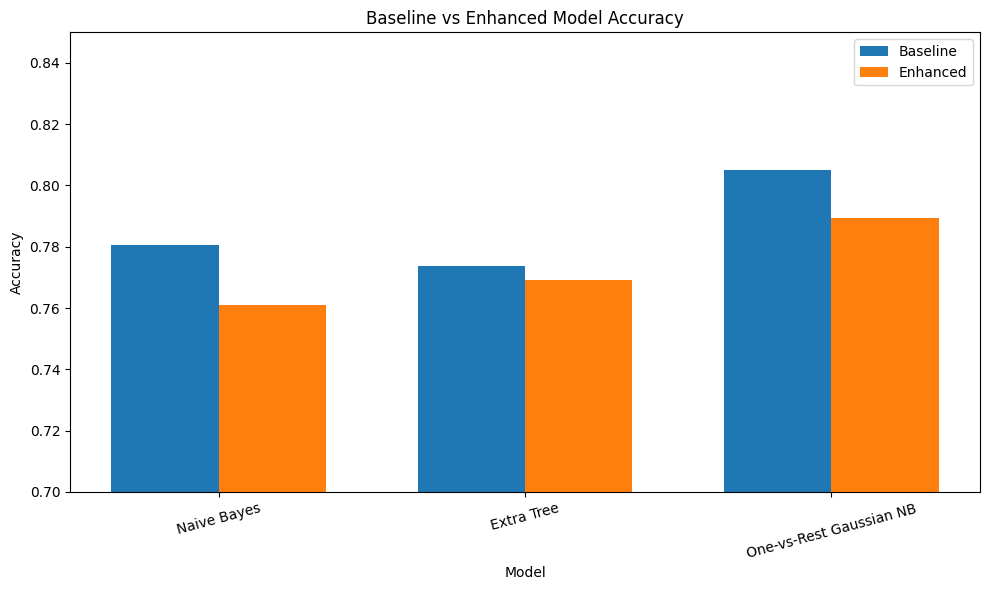

Accuracy plot saved to:
d:\Major_Project\Crime_Analysis\outputs\figures\baseline_vs_enhanced_accuracy.png


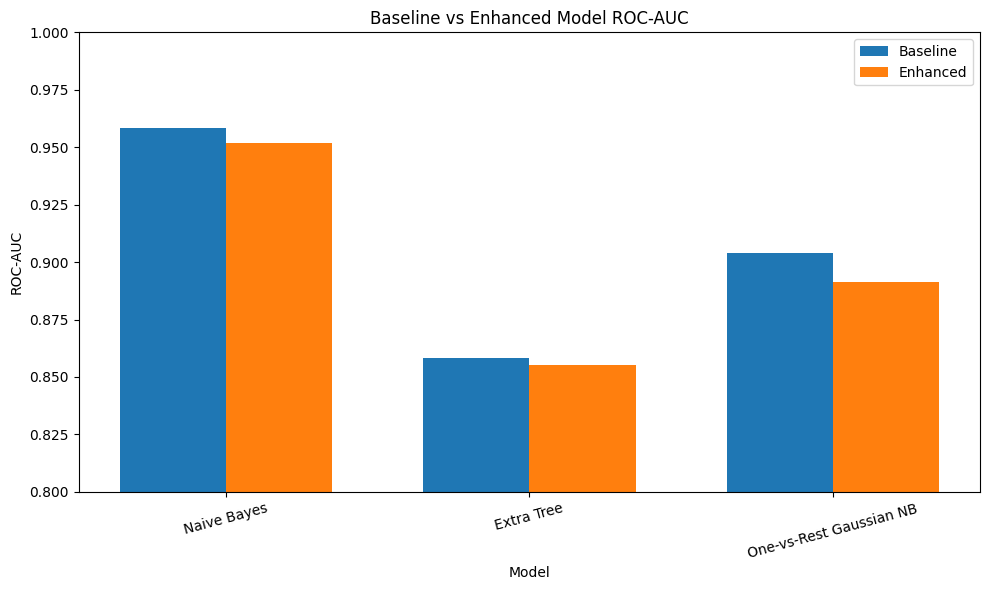

ROC-AUC plot saved to:
d:\Major_Project\Crime_Analysis\outputs\figures\baseline_vs_enhanced_roc_auc.png

STEP 24 COMPLETED


In [20]:
# ============================================================
# STEP 24 — FINAL MODEL COMPARISON PLOTS
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

# Model names
models = final_comparison["Model"].tolist()

# -----------------------------
# 1. ACCURACY COMPARISON
# -----------------------------

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - width / 2,
    final_comparison["Baseline_Accuracy"],
    width,
    label="Baseline"
)

plt.bar(
    x + width / 2,
    final_comparison["Enhanced_Accuracy"],
    width,
    label="Enhanced"
)

plt.xticks(x, models, rotation=15)
plt.ylabel("Accuracy")
plt.xlabel("Model")
plt.title("Baseline vs Enhanced Model Accuracy")
plt.ylim(0.70, 0.85)
plt.legend()
plt.tight_layout()

accuracy_plot_path = (
    PROJECT_ROOT
    / "outputs"
    / "figures"
    / "baseline_vs_enhanced_accuracy.png"
)

plt.savefig(accuracy_plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("Accuracy plot saved to:")
print(accuracy_plot_path)


# -----------------------------
# 2. ROC-AUC COMPARISON
# -----------------------------

plt.figure(figsize=(10, 6))

plt.bar(
    x - width / 2,
    final_comparison["Baseline_ROC_AUC"],
    width,
    label="Baseline"
)

plt.bar(
    x + width / 2,
    final_comparison["Enhanced_ROC_AUC"],
    width,
    label="Enhanced"
)

plt.xticks(x, models, rotation=15)
plt.ylabel("ROC-AUC")
plt.xlabel("Model")
plt.title("Baseline vs Enhanced Model ROC-AUC")
plt.ylim(0.80, 1.00)
plt.legend()
plt.tight_layout()

roc_plot_path = (
    PROJECT_ROOT
    / "outputs"
    / "figures"
    / "baseline_vs_enhanced_roc_auc.png"
)

plt.savefig(roc_plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("ROC-AUC plot saved to:")
print(roc_plot_path)

print("\n" + "=" * 70)
print("STEP 24 COMPLETED")
print("=" * 70)

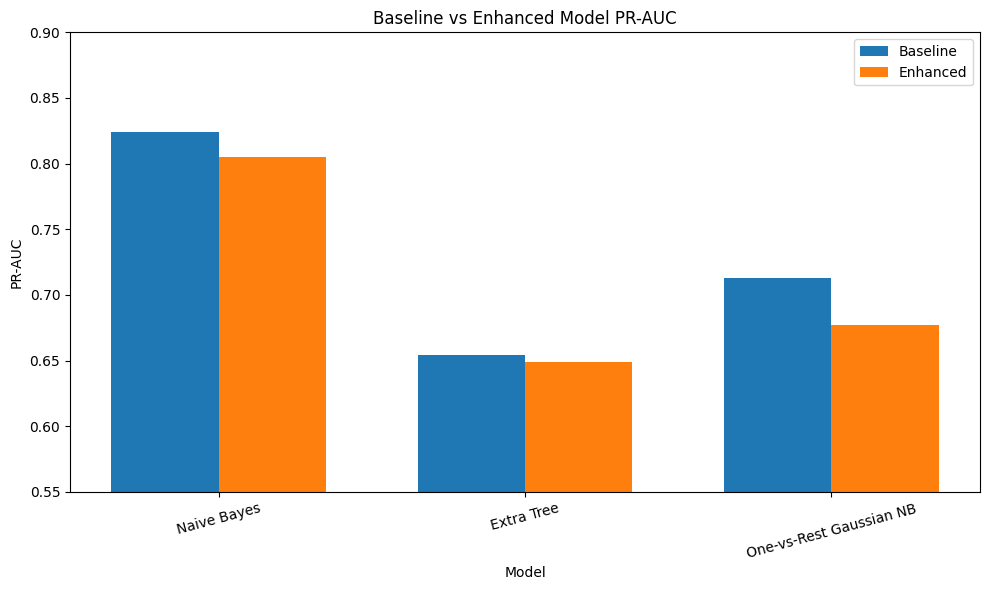

PR-AUC plot saved to:
d:\Major_Project\Crime_Analysis\outputs\figures\baseline_vs_enhanced_pr_auc.png


In [21]:
# ============================================================
# STEP 25 — PR-AUC COMPARISON
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

models = final_comparison["Model"].tolist()

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - width / 2,
    final_comparison["Baseline_PR_AUC"],
    width,
    label="Baseline"
)

plt.bar(
    x + width / 2,
    final_comparison["Enhanced_PR_AUC"],
    width,
    label="Enhanced"
)

plt.xticks(x, models, rotation=15)
plt.ylabel("PR-AUC")
plt.xlabel("Model")
plt.title("Baseline vs Enhanced Model PR-AUC")
plt.ylim(0.55, 0.90)
plt.legend()
plt.tight_layout()

pr_plot_path = (
    PROJECT_ROOT
    / "outputs"
    / "figures"
    / "baseline_vs_enhanced_pr_auc.png"
)

plt.savefig(pr_plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("PR-AUC plot saved to:")
print(pr_plot_path)

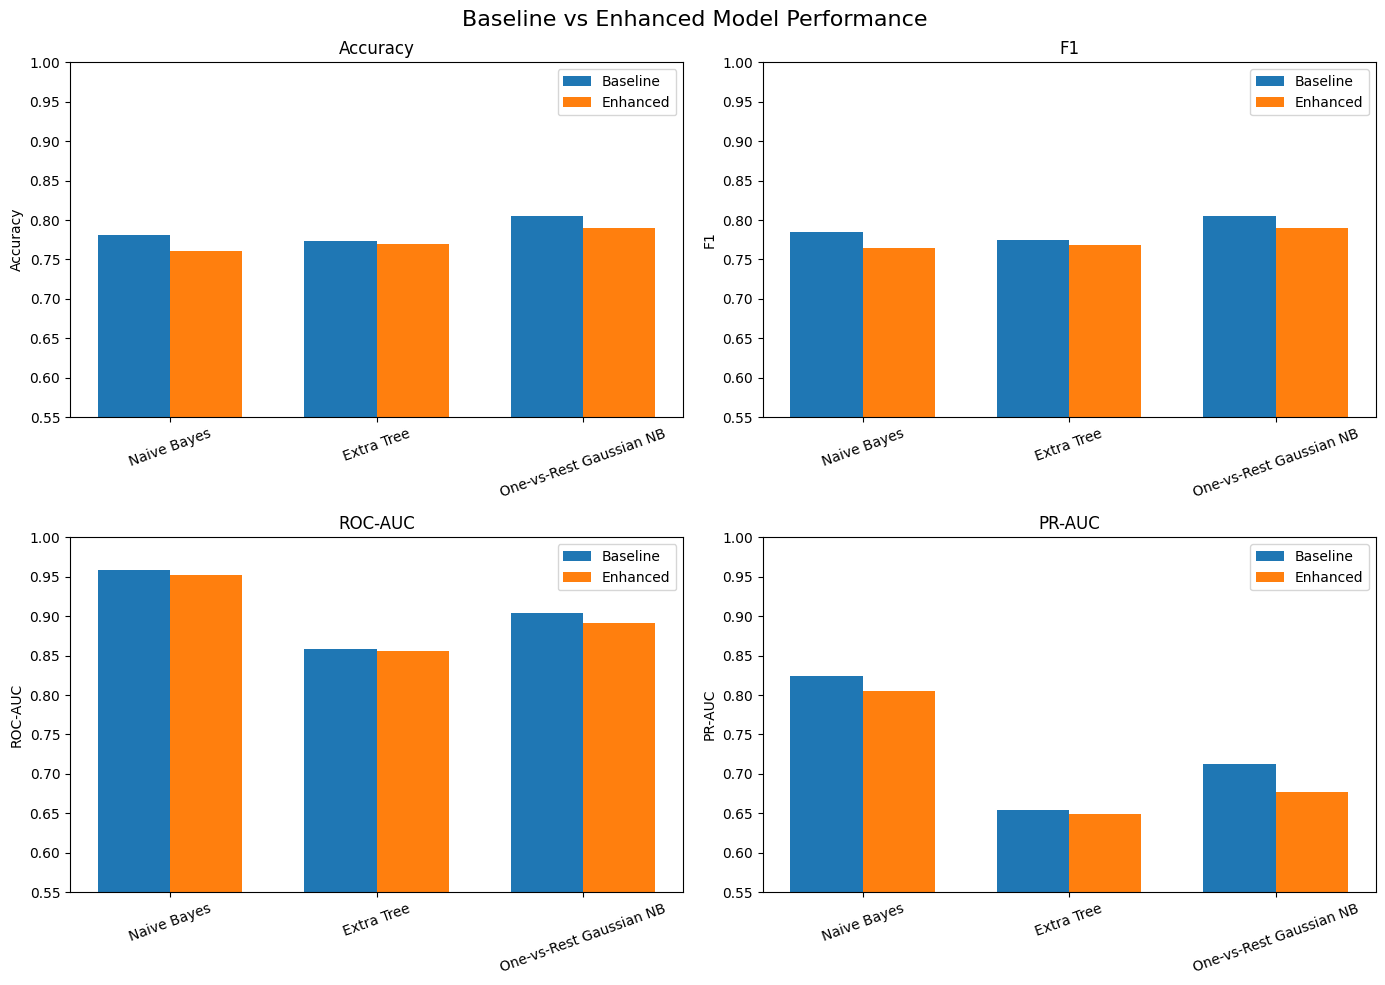

COMBINED PERFORMANCE PLOT SAVED SUCCESSFULLY
d:\Major_Project\Crime_Analysis\outputs\figures\baseline_vs_enhanced_all_metrics.png


In [22]:
# ============================================================
# STEP 26 — CORRECTED COMBINED PERFORMANCE COMPARISON
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

models = final_comparison["Model"].tolist()

x = np.arange(len(models))
width = 0.35

# Correct column names used in final_comparison
metric_columns = {
    "Accuracy": ("Baseline_Accuracy", "Enhanced_Accuracy"),
    "F1": ("Baseline_F1", "Enhanced_F1"),
    "ROC-AUC": ("Baseline_ROC_AUC", "Enhanced_ROC_AUC"),
    "PR-AUC": ("Baseline_PR_AUC", "Enhanced_PR_AUC")
}

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, (metric, columns) in zip(
    axes.ravel(),
    metric_columns.items()
):

    baseline_col, enhanced_col = columns

    ax.bar(
        x - width / 2,
        final_comparison[baseline_col],
        width,
        label="Baseline"
    )

    ax.bar(
        x + width / 2,
        final_comparison[enhanced_col],
        width,
        label="Enhanced"
    )

    ax.set_title(metric)
    ax.set_xticks(x)
    ax.set_xticklabels(models, rotation=20)
    ax.set_ylabel(metric)
    ax.set_ylim(0.55, 1.00)
    ax.legend()

plt.suptitle(
    "Baseline vs Enhanced Model Performance",
    fontsize=16
)

plt.tight_layout()

combined_plot_path = (
    PROJECT_ROOT
    / "outputs"
    / "figures"
    / "baseline_vs_enhanced_all_metrics.png"
)

plt.savefig(
    combined_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("=" * 70)
print("COMBINED PERFORMANCE PLOT SAVED SUCCESSFULLY")
print("=" * 70)

print(combined_plot_path)

In [23]:
# ============================================================
# STEP 27 — COMPACT FINAL RESULTS TABLE
# ============================================================

compact_results = pd.DataFrame({
    "Model": final_comparison["Model"],

    "Baseline Accuracy":
        final_comparison["Baseline_Accuracy"],

    "Enhanced Accuracy":
        final_comparison["Enhanced_Accuracy"],

    "Baseline F1":
        final_comparison["Baseline_F1"],

    "Enhanced F1":
        final_comparison["Enhanced_F1"],

    "Baseline ROC-AUC":
        final_comparison["Baseline_ROC_AUC"],

    "Enhanced ROC-AUC":
        final_comparison["Enhanced_ROC_AUC"],

    "Baseline PR-AUC":
        final_comparison["Baseline_PR_AUC"],

    "Enhanced PR-AUC":
        final_comparison["Enhanced_PR_AUC"],
})

print("=" * 70)
print("COMPACT FINAL RESULTS")
print("=" * 70)

print(
    compact_results.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

compact_results_path = (
    PROJECT_ROOT
    / "outputs"
    / "tables"
    / "compact_final_model_results.csv"
)

compact_results.to_csv(
    compact_results_path,
    index=False
)

print("\nSaved to:")
print(compact_results_path)

COMPACT FINAL RESULTS
                  Model  Baseline Accuracy  Enhanced Accuracy  Baseline F1  Enhanced F1  Baseline ROC-AUC  Enhanced ROC-AUC  Baseline PR-AUC  Enhanced PR-AUC
            Naive Bayes             0.7806             0.7609       0.7843       0.7643            0.9584            0.9519           0.8240           0.8053
             Extra Tree             0.7738             0.7690       0.7741       0.7680            0.8582            0.8553           0.6542           0.6490
One-vs-Rest Gaussian NB             0.8050             0.7894       0.8049       0.7902            0.9041            0.8915           0.7131           0.6769

Saved to:
d:\Major_Project\Crime_Analysis\outputs\tables\compact_final_model_results.csv


In [24]:
# ============================================================
# STEP 28 — CORRECTED CONFUSION MATRIX DATA
# ============================================================

from sklearn.naive_bayes import GaussianNB
from sklearn.tree import ExtraTreeClassifier
from sklearn.multiclass import OneVsRestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

# Target column used in the project
TARGET_COLUMN = "TARGET_VIOLENT_LEVEL"

# ------------------------------------------------------------
# FAIR BASELINE DATA — 6 GROUP FEATURES
# ------------------------------------------------------------

BASELINE_FEATURES_FAIR = [
    "GROUP_HOMICIDE",
    "GROUP_SEXUAL_VIOLENCE",
    "GROUP_KIDNAPPING_ABDUCTION",
    "GROUP_ROBBERY_DACOITY",
    "GROUP_PUBLIC_VIOLENCE",
    "GROUP_PROPERTY_CRIME"
]

X_baseline = enhanced_model_df[BASELINE_FEATURES_FAIR]
y_baseline = enhanced_model_df[TARGET_COLUMN]

Xb_train, Xb_test, yb_train, yb_test = train_test_split(
    X_baseline,
    y_baseline,
    test_size=0.20,
    random_state=42,
    stratify=y_baseline
)

# ------------------------------------------------------------
# ENHANCED DATA — 6 GROUP FEATURES + PREVIOUS YEAR TOTAL
# ------------------------------------------------------------

ENHANCED_FEATURES = [
    "GROUP_HOMICIDE",
    "GROUP_SEXUAL_VIOLENCE",
    "GROUP_KIDNAPPING_ABDUCTION",
    "GROUP_ROBBERY_DACOITY",
    "GROUP_PUBLIC_VIOLENCE",
    "GROUP_PROPERTY_CRIME",
    "PREV_YEAR_TOTAL_CRIME"
]

X_enhanced = enhanced_model_df[ENHANCED_FEATURES]
y_enhanced = enhanced_model_df[TARGET_COLUMN]

Xe_train, Xe_test, ye_train, ye_test = train_test_split(
    X_enhanced,
    y_enhanced,
    test_size=0.20,
    random_state=42,
    stratify=y_enhanced
)

# ------------------------------------------------------------
# BASELINE MODELS
# ------------------------------------------------------------

baseline_nb_model = GaussianNB()
baseline_nb_model.fit(Xb_train, yb_train)
baseline_nb_pred = baseline_nb_model.predict(Xb_test)

baseline_extra_model = ExtraTreeClassifier(random_state=42)
baseline_extra_model.fit(Xb_train, yb_train)
baseline_extra_pred = baseline_extra_model.predict(Xb_test)

baseline_ovr_model = OneVsRestClassifier(
    GaussianNB()
)
baseline_ovr_model.fit(Xb_train, yb_train)
baseline_ovr_pred = baseline_ovr_model.predict(Xb_test)

# ------------------------------------------------------------
# ENHANCED MODELS
# ------------------------------------------------------------

enhanced_nb_model = GaussianNB()
enhanced_nb_model.fit(Xe_train, ye_train)
enhanced_nb_pred = enhanced_nb_model.predict(Xe_test)

enhanced_extra_model = ExtraTreeClassifier(random_state=42)
enhanced_extra_model.fit(Xe_train, ye_train)
enhanced_extra_pred = enhanced_extra_model.predict(Xe_test)

enhanced_ovr_model = OneVsRestClassifier(
    GaussianNB()
)
enhanced_ovr_model.fit(Xe_train, ye_train)
enhanced_ovr_pred = enhanced_ovr_model.predict(Xe_test)

# ------------------------------------------------------------
# CHECK
# ------------------------------------------------------------

print("=" * 70)
print("CONFUSION MATRIX DATA CREATED SUCCESSFULLY")
print("=" * 70)

print("\nBaseline training shape:")
print(Xb_train.shape)

print("\nBaseline testing shape:")
print(Xb_test.shape)

print("\nEnhanced training shape:")
print(Xe_train.shape)

print("\nEnhanced testing shape:")
print(Xe_test.shape)

print("\nTarget column:")
print(TARGET_COLUMN)

print("\nBaseline features:")
print(BASELINE_FEATURES_FAIR)

print("\nEnhanced features:")
print(ENHANCED_FEATURES)

CONFUSION MATRIX DATA CREATED SUCCESSFULLY

Baseline training shape:
(5884, 6)

Baseline testing shape:
(1472, 6)

Enhanced training shape:
(5884, 7)

Enhanced testing shape:
(1472, 7)

Target column:
TARGET_VIOLENT_LEVEL

Baseline features:
['GROUP_HOMICIDE', 'GROUP_SEXUAL_VIOLENCE', 'GROUP_KIDNAPPING_ABDUCTION', 'GROUP_ROBBERY_DACOITY', 'GROUP_PUBLIC_VIOLENCE', 'GROUP_PROPERTY_CRIME']

Enhanced features:
['GROUP_HOMICIDE', 'GROUP_SEXUAL_VIOLENCE', 'GROUP_KIDNAPPING_ABDUCTION', 'GROUP_ROBBERY_DACOITY', 'GROUP_PUBLIC_VIOLENCE', 'GROUP_PROPERTY_CRIME', 'PREV_YEAR_TOTAL_CRIME']


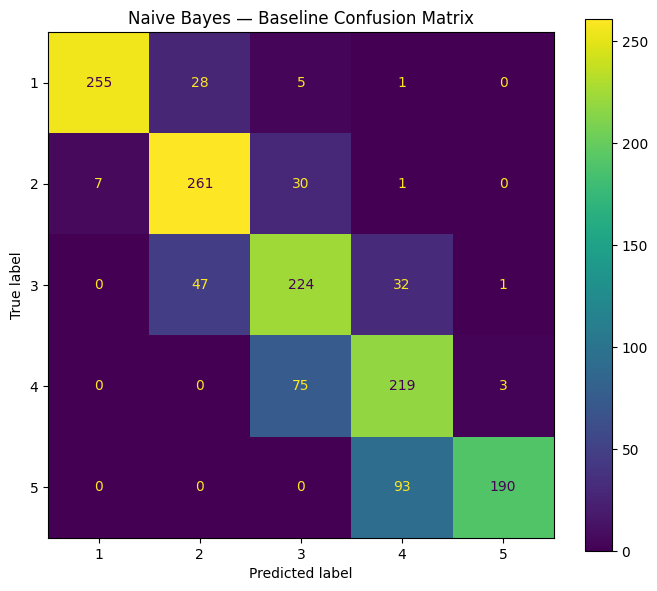

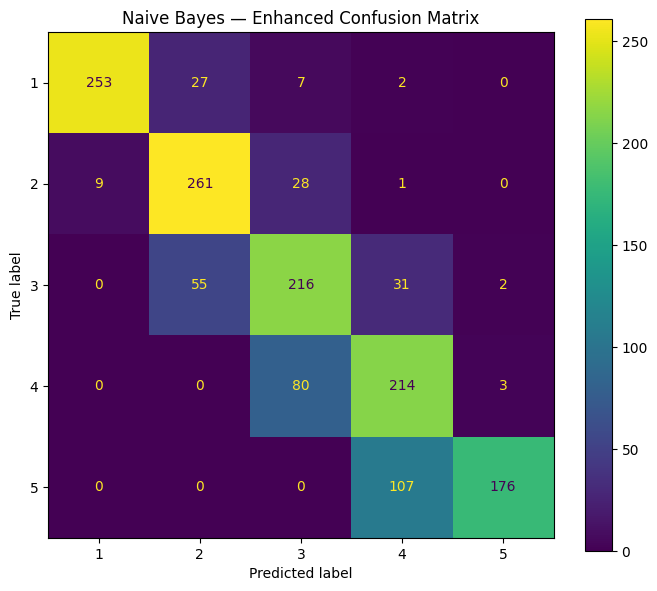

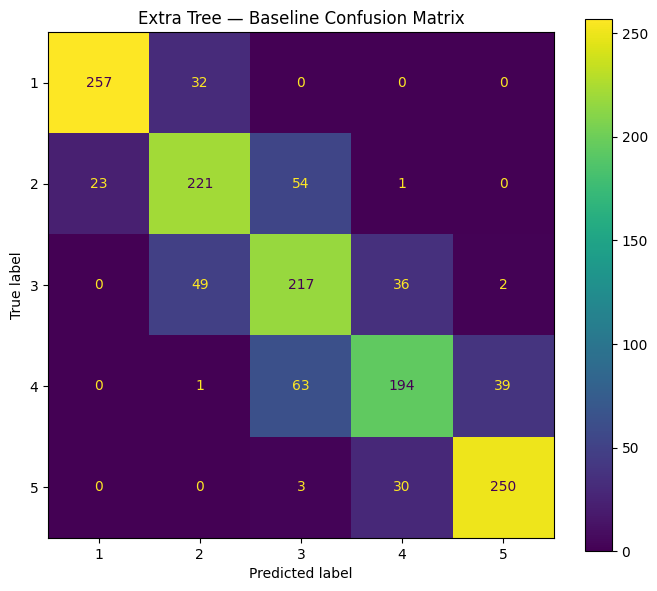

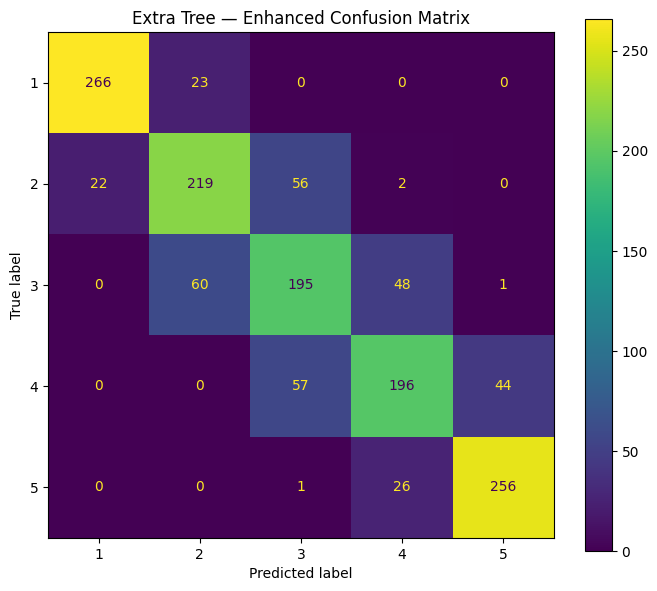

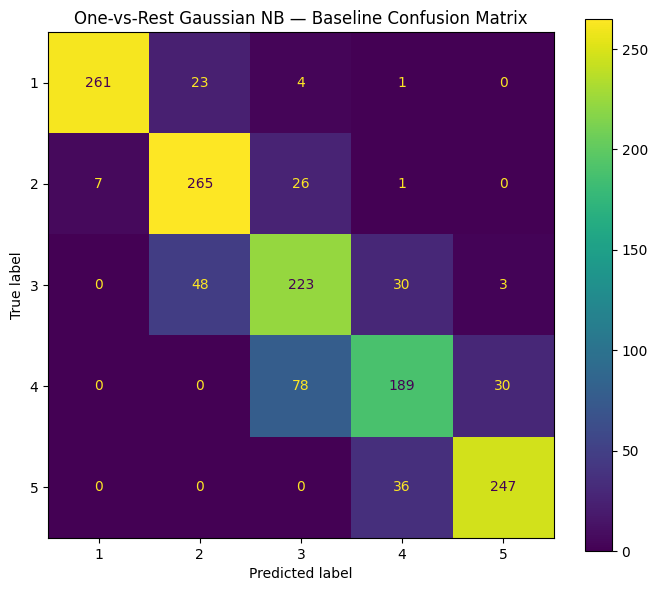

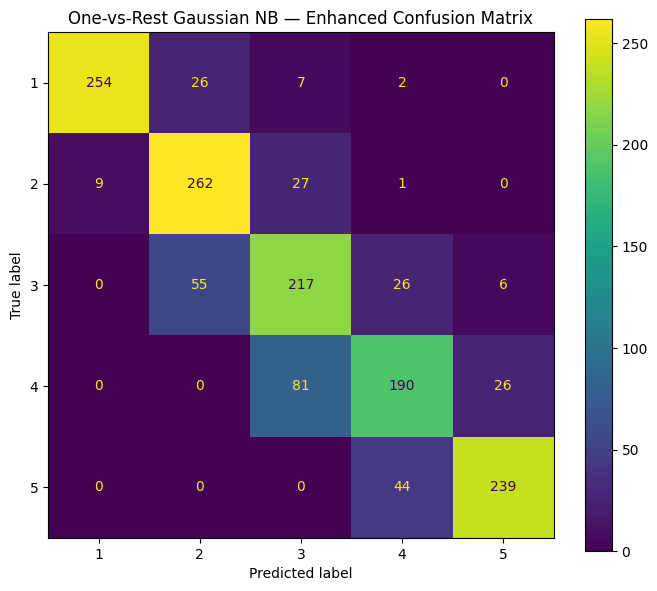

All confusion matrices saved successfully.


In [25]:
# ============================================================
# STEP 29 — CONFUSION MATRICES
# ============================================================

from sklearn.metrics import ConfusionMatrixDisplay

model_predictions = [
    (
        "Naive Bayes",
        yb_test,
        baseline_nb_pred,
        ye_test,
        enhanced_nb_pred
    ),
    (
        "Extra Tree",
        yb_test,
        baseline_extra_pred,
        ye_test,
        enhanced_extra_pred
    ),
    (
        "One-vs-Rest Gaussian NB",
        yb_test,
        baseline_ovr_pred,
        ye_test,
        enhanced_ovr_pred
    )
]

for model_name, yb_true, yb_pred, ye_true, ye_pred in model_predictions:

    # Baseline
    cm_baseline = confusion_matrix(
        yb_true,
        yb_pred,
        labels=[1, 2, 3, 4, 5]
    )

    plt.figure(figsize=(7, 6))

    ConfusionMatrixDisplay(
        confusion_matrix=cm_baseline,
        display_labels=[1, 2, 3, 4, 5]
    ).plot(
        ax=plt.gca(),
        values_format="d"
    )

    plt.title(
        f"{model_name} — Baseline Confusion Matrix"
    )

    plt.tight_layout()

    safe_name = (
        model_name
        .lower()
        .replace(" ", "_")
        .replace("-", "")
    )

    baseline_cm_path = (
        PROJECT_ROOT
        / "outputs"
        / "figures"
        / f"{safe_name}_baseline_confusion_matrix.png"
    )

    plt.savefig(
        baseline_cm_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    # Enhanced
    cm_enhanced = confusion_matrix(
        ye_true,
        ye_pred,
        labels=[1, 2, 3, 4, 5]
    )

    plt.figure(figsize=(7, 6))

    ConfusionMatrixDisplay(
        confusion_matrix=cm_enhanced,
        display_labels=[1, 2, 3, 4, 5]
    ).plot(
        ax=plt.gca(),
        values_format="d"
    )

    plt.title(
        f"{model_name} — Enhanced Confusion Matrix"
    )

    plt.tight_layout()

    enhanced_cm_path = (
        PROJECT_ROOT
        / "outputs"
        / "figures"
        / f"{safe_name}_enhanced_confusion_matrix.png"
    )

    plt.savefig(
        enhanced_cm_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

print("All confusion matrices saved successfully.")

In [26]:
# ============================================================
# STEP 30 — CLASSIFICATION REPORTS
# ============================================================

from sklearn.metrics import classification_report

reports = []

report_models = [
    (
        "Naive Bayes",
        yb_test,
        baseline_nb_pred,
        ye_test,
        enhanced_nb_pred
    ),
    (
        "Extra Tree",
        yb_test,
        baseline_extra_pred,
        ye_test,
        enhanced_extra_pred
    ),
    (
        "One-vs-Rest Gaussian NB",
        yb_test,
        baseline_ovr_pred,
        ye_test,
        enhanced_ovr_pred
    )
]

for model_name, yb_true, yb_pred, ye_true, ye_pred in report_models:

    baseline_report = classification_report(
        yb_true,
        yb_pred,
        labels=[1, 2, 3, 4, 5],
        output_dict=True,
        zero_division=0
    )

    enhanced_report = classification_report(
        ye_true,
        ye_pred,
        labels=[1, 2, 3, 4, 5],
        output_dict=True,
        zero_division=0
    )

    for class_id in ["1", "2", "3", "4", "5"]:

        reports.append({
            "Model": model_name,
            "Class": int(class_id),

            "Baseline_Precision":
                baseline_report[class_id]["precision"],

            "Enhanced_Precision":
                enhanced_report[class_id]["precision"],

            "Baseline_Recall":
                baseline_report[class_id]["recall"],

            "Enhanced_Recall":
                enhanced_report[class_id]["recall"],

            "Baseline_F1":
                baseline_report[class_id]["f1-score"],

            "Enhanced_F1":
                enhanced_report[class_id]["f1-score"]
        })

classification_reports = pd.DataFrame(reports)

print("=" * 70)
print("CLASSIFICATION REPORTS")
print("=" * 70)

print(
    classification_reports.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

classification_report_path = (
    PROJECT_ROOT
    / "outputs"
    / "tables"
    / "baseline_vs_enhanced_classification_reports.csv"
)

classification_reports.to_csv(
    classification_report_path,
    index=False
)

print("\nSaved to:")
print(classification_report_path)

CLASSIFICATION REPORTS
                  Model  Class  Baseline_Precision  Enhanced_Precision  Baseline_Recall  Enhanced_Recall  Baseline_F1  Enhanced_F1
            Naive Bayes      1              0.9733              0.9656           0.8824           0.8754       0.9256       0.9183
            Naive Bayes      2              0.7768              0.7609           0.8729           0.8729       0.8220       0.8131
            Naive Bayes      3              0.6707              0.6526           0.7368           0.7105       0.7022       0.6803
            Naive Bayes      4              0.6329              0.6028           0.7374           0.7205       0.6812       0.6564
            Naive Bayes      5              0.9794              0.9724           0.6714           0.6219       0.7966       0.7586
             Extra Tree      1              0.9179              0.9236           0.8893           0.9204       0.9033       0.9220
             Extra Tree      2              0.7294          

ENHANCED EXTRA TREE FEATURE IMPORTANCE
                   Feature  Importance
            GROUP_HOMICIDE      0.3235
     GROUP_PUBLIC_VIOLENCE      0.1718
     GROUP_ROBBERY_DACOITY      0.1271
GROUP_KIDNAPPING_ABDUCTION      0.1197
     GROUP_SEXUAL_VIOLENCE      0.1046
     PREV_YEAR_TOTAL_CRIME      0.0968
      GROUP_PROPERTY_CRIME      0.0565


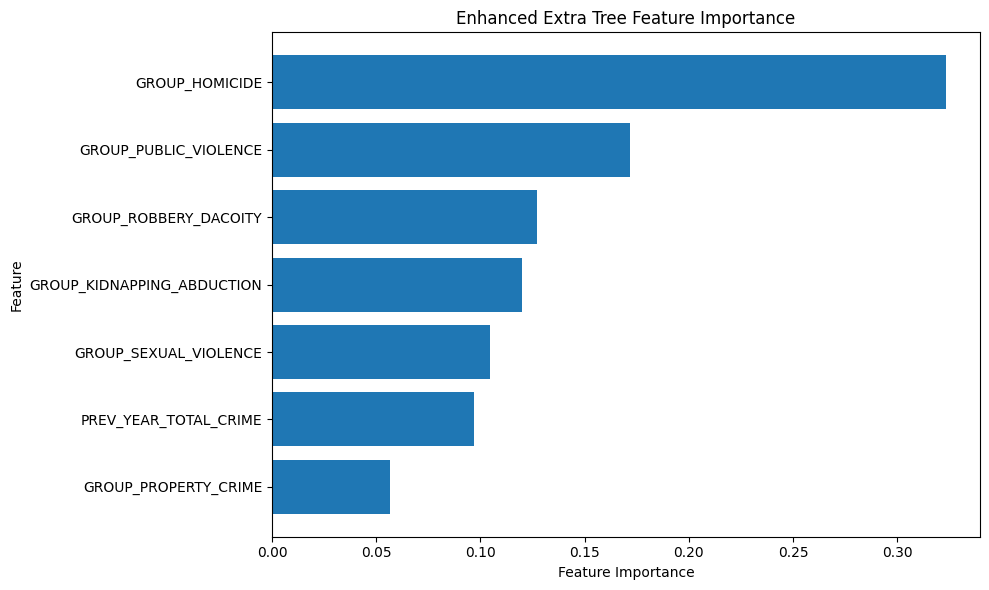


Feature importance table:
d:\Major_Project\Crime_Analysis\outputs\tables\enhanced_extra_tree_feature_importance.csv

Feature importance plot:
d:\Major_Project\Crime_Analysis\outputs\figures\enhanced_extra_tree_feature_importance.png


In [27]:
# ============================================================
# STEP 31 — ENHANCED EXTRA TREE FEATURE IMPORTANCE
# ============================================================

feature_importance = pd.DataFrame({
    "Feature": ENHANCED_FEATURES,
    "Importance": enhanced_extra_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)

print("=" * 70)
print("ENHANCED EXTRA TREE FEATURE IMPORTANCE")
print("=" * 70)

print(
    feature_importance.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

feature_importance_path = (
    PROJECT_ROOT
    / "outputs"
    / "tables"
    / "enhanced_extra_tree_feature_importance.csv"
)

feature_importance.to_csv(
    feature_importance_path,
    index=False
)

plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"][::-1],
    feature_importance["Importance"][::-1]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title(
    "Enhanced Extra Tree Feature Importance"
)

plt.tight_layout()

feature_importance_plot_path = (
    PROJECT_ROOT
    / "outputs"
    / "figures"
    / "enhanced_extra_tree_feature_importance.png"
)

plt.savefig(
    feature_importance_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nFeature importance table:")
print(feature_importance_path)

print("\nFeature importance plot:")
print(feature_importance_plot_path)

In [ ]:
# ============================================================
# STEP 32 — FINAL EXPERIMENT SUMMARY
# ============================================================

final_summary = pd.DataFrame([
    {
        "Experiment": "Fair Baseline",
        "Dataset": "district_enhanced_features.csv",
        "Rows": len(enhanced_model_df),
        "Features": 6,
        "Features_Used": ", ".join(BASELINE_FEATURES_FAIR),
        "Target": TARGET_COLUMN,
        "Split": "80/20 stratified",
        "Random_State": 42
    },
    {
        "Experiment": "Same-Year Enhanced Classification (Not Forecasting)",
        "Dataset": "district_enhanced_features.csv",
        "Rows": len(enhanced_model_df),
        "Features": 7,
        "Features_Used": ", ".join(ENHANCED_FEATURES),
        "Target": TARGET_COLUMN,
        "Split": "80/20 stratified",
        "Random_State": 42
    }
])

print("=" * 70)
print("FINAL EXPERIMENT SUMMARY")
print("=" * 70)

print(final_summary.to_string(index=False))

summary_path = (
    PROJECT_ROOT
    / "outputs"
    / "tables"
    / "final_experiment_summary.csv"
)

final_summary.to_csv(
    summary_path,
    index=False
)

print("\nSaved to:")
print(summary_path)

In [29]:
# ============================================================
# STEP 33 — FINAL OUTPUT INVENTORY
# ============================================================

from pathlib import Path

print("=" * 70)
print("FINAL PROJECT OUTPUT INVENTORY")
print("=" * 70)

tables_dir = PROJECT_ROOT / "outputs" / "tables"
figures_dir = PROJECT_ROOT / "outputs" / "figures"

print("\nTABLES:")
for file in sorted(tables_dir.glob("*.csv")):
    print("  ✓", file.name)

print("\nFIGURES:")
for file in sorted(figures_dir.glob("*.png")):
    print("  ✓", file.name)

enhanced_dataset_path = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "district_enhanced_features.csv"
)

print("\nENHANCED DATASET:")
print(
    "  ✓", enhanced_dataset_path.name,
    "->", enhanced_dataset_path.exists()
)

print("\n" + "=" * 70)
print("ML EXPERIMENT AND REPORTING PIPELINE COMPLETED")
print("=" * 70)

FINAL PROJECT OUTPUT INVENTORY

TABLES:
  ✓ 76_file_inventory.csv
  ✓ all_models_final_comparison.csv
  ✓ availability_report.csv
  ✓ baseline_vs_enhanced_classification_reports.csv
  ✓ basepaper_column_keyword_search.csv
  ✓ basepaper_final_model_comparison.csv
  ✓ basepaper_model_results.csv
  ✓ basepaper_violent_crime_mapping.csv
  ✓ candidate_dominant_crime_distribution.csv
  ✓ candidate_five_level_distribution.csv
  ✓ canonical_feature_mapping.csv
  ✓ categorical_column_audit.csv
  ✓ column_classification_report.csv
  ✓ compact_final_model_results.csv
  ✓ crime_column_group_mapping.csv
  ✓ crime_column_reduction_summary.csv
  ✓ crime_group_mapping.csv
  ✓ crime_group_summary.csv
  ✓ crime_grouping_audit.csv
  ✓ crime_grouping_mapping_candidates.csv
  ✓ crime_parent_child_validation.csv
  ✓ dataset_sample_evidence.csv
  ✓ dataset_semantic_profile.csv
  ✓ eda_correlation_matrix.csv
  ✓ eda_crime_family_availability.csv
  ✓ eda_crime_family_feature_counts.csv
  ✓ eda_dataset_profile.

In [30]:
import sys

print("Python executable:")
print(sys.executable)

try:
    import tensorflow as tf
    print("\nTensorFlow is installed.")
    print("TensorFlow version:", tf.__version__)
    print("TensorFlow location:", tf.__file__)

    from tensorflow import keras
    print("TensorFlow Keras import: OK")

except Exception as e:
    print("\nTensorFlow/Keras import failed:")
    print(type(e).__name__, ":", e)

Python executable:
d:\Major_Project\Crime_Analysis\.venv\Scripts\python.exe

TensorFlow is installed.
TensorFlow version: 2.21.0
TensorFlow location: d:\Major_Project\Crime_Analysis\.venv\lib\site-packages\tensorflow\__init__.py
TensorFlow Keras import: OK


In [31]:
import sys

print(sys.executable)

import tensorflow as tf
from tensorflow import keras

print("TensorFlow:", tf.__version__)
print("TensorFlow location:", tf.__file__)
print("Keras import: OK")

d:\Major_Project\Crime_Analysis\.venv\Scripts\python.exe
TensorFlow: 2.21.0
TensorFlow location: d:\Major_Project\Crime_Analysis\.venv\lib\site-packages\tensorflow\__init__.py
Keras import: OK


In [32]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

import tensorflow as tf
from tensorflow import keras

EarlyStopping = keras.callbacks.EarlyStopping

SEED = 42

np.random.seed(SEED)
tf.random.set_seed(SEED)

PROJECT_ROOT = Path.cwd().parent
SRC_PATH = PROJECT_ROOT / "src"

if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

from deep_learning_models import (
    build_baseline_ann,
    build_enhanced_ann
)

print("Project root:", PROJECT_ROOT)
print("MLP imports successful.")

Project root: d:\Major_Project\Crime_Analysis
MLP imports successful.


In [33]:
BASELINE_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "district_grouped_reduced.csv"
)

ENHANCED_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "district_enhanced_features.csv"
)

baseline_df = pd.read_csv(BASELINE_PATH)
enhanced_df = pd.read_csv(ENHANCED_PATH)

print("Baseline dataset shape:", baseline_df.shape)
print("Enhanced dataset shape:", enhanced_df.shape)

print("\nBaseline columns:")
print(baseline_df.columns.tolist())

print("\nEnhanced columns:")
print(enhanced_df.columns.tolist())

Baseline dataset shape: (9856, 10)
Enhanced dataset shape: (9856, 15)

Baseline columns:
['YEAR', 'STATE', 'UNIT_NAME', 'GROUP_HOMICIDE', 'GROUP_SEXUAL_VIOLENCE', 'GROUP_KIDNAPPING_ABDUCTION', 'GROUP_ROBBERY_DACOITY', 'GROUP_PUBLIC_VIOLENCE', 'GROUP_PROPERTY_CRIME', 'TARGET_VIOLENT_LEVEL']

Enhanced columns:
['YEAR', 'STATE', 'UNIT_NAME', 'GROUP_HOMICIDE', 'GROUP_SEXUAL_VIOLENCE', 'GROUP_KIDNAPPING_ABDUCTION', 'GROUP_ROBBERY_DACOITY', 'GROUP_PUBLIC_VIOLENCE', 'GROUP_PROPERTY_CRIME', 'TOTAL_GROUPED_CRIME', 'ACTIVE_CRIME_GROUPS', 'CRIME_DIVERSITY_INDEX', 'PREV_YEAR_TOTAL_CRIME', 'YOY_TOTAL_CRIME_CHANGE', 'TARGET_VIOLENT_LEVEL']


In [34]:
TARGET_COLUMN = "TARGET_VIOLENT_LEVEL"

BASELINE_DL_FEATURES = [
    "GROUP_HOMICIDE",
    "GROUP_SEXUAL_VIOLENCE",
    "GROUP_KIDNAPPING_ABDUCTION",
    "GROUP_ROBBERY_DACOITY",
    "GROUP_PUBLIC_VIOLENCE",
    "GROUP_PROPERTY_CRIME"
]

ENHANCED_DL_FEATURES = BASELINE_DL_FEATURES + [
    "PREV_YEAR_TOTAL_CRIME"
]

print("Baseline features:", BASELINE_DL_FEATURES)
print("\nBaseline feature count:", len(BASELINE_DL_FEATURES))

print("\nEnhanced features:", ENHANCED_DL_FEATURES)
print("\nEnhanced feature count:", len(ENHANCED_DL_FEATURES))

Baseline features: ['GROUP_HOMICIDE', 'GROUP_SEXUAL_VIOLENCE', 'GROUP_KIDNAPPING_ABDUCTION', 'GROUP_ROBBERY_DACOITY', 'GROUP_PUBLIC_VIOLENCE', 'GROUP_PROPERTY_CRIME']

Baseline feature count: 6

Enhanced features: ['GROUP_HOMICIDE', 'GROUP_SEXUAL_VIOLENCE', 'GROUP_KIDNAPPING_ABDUCTION', 'GROUP_ROBBERY_DACOITY', 'GROUP_PUBLIC_VIOLENCE', 'GROUP_PROPERTY_CRIME', 'PREV_YEAR_TOTAL_CRIME']

Enhanced feature count: 7


In [35]:
enhanced_model_df = enhanced_df.dropna(
    subset=[
        TARGET_COLUMN,
        "PREV_YEAR_TOTAL_CRIME"
    ]
).copy()

print("Usable rows:", len(enhanced_model_df))

print("\nTarget distribution:")
print(
    enhanced_model_df[TARGET_COLUMN]
    .value_counts()
    .sort_index()
)


Usable rows: 7356

Target distribution:
TARGET_VIOLENT_LEVEL
1.0    1443
2.0    1495
3.0    1518
4.0    1486
5.0    1414
Name: count, dtype: int64


In [36]:
y_common = (
    enhanced_model_df[TARGET_COLUMN]
    .astype(int)
    .reset_index(drop=True)
)

common_indices = np.arange(len(enhanced_model_df))

train_idx, test_idx = train_test_split(
    common_indices,
    test_size=0.20,
    random_state=SEED,
    stratify=y_common
)

print("Total:", len(common_indices))
print("Training:", len(train_idx))
print("Testing:", len(test_idx))

Total: 7356
Training: 5884
Testing: 1472


In [37]:
X_baseline = enhanced_model_df[
    BASELINE_DL_FEATURES
].reset_index(drop=True)

X_enhanced = enhanced_model_df[
    ENHANCED_DL_FEATURES
].reset_index(drop=True)

y = (
    enhanced_model_df[TARGET_COLUMN]
    .astype(int)
    .reset_index(drop=True)
)

X_baseline_train = X_baseline.iloc[train_idx]
X_baseline_test = X_baseline.iloc[test_idx]

X_enhanced_train = X_enhanced.iloc[train_idx]
X_enhanced_test = X_enhanced.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Baseline:")
print("Train:", X_baseline_train.shape)
print("Test :", X_baseline_test.shape)

print("\nEnhanced:")
print("Train:", X_enhanced_train.shape)
print("Test :", X_enhanced_test.shape)

Baseline:
Train: (5884, 6)
Test : (1472, 6)

Enhanced:
Train: (5884, 7)
Test : (1472, 7)


In [38]:
# Scaling is deferred until after the inner training/validation split.
# Fitting here would let the later validation observations affect preprocessing.


Scaling completed.
Baseline: (5884, 6)
Enhanced: (5884, 7)


In [39]:
y_train_dl = y_train.to_numpy() - 1
y_test_dl = y_test.to_numpy() - 1

print("Original target classes:")
print(sorted(y.unique()))

print("\nMLP target classes:")
print(sorted(np.unique(y_train_dl)))

Original target classes:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

MLP target classes:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


In [40]:
import importlib
import deep_learning_models

importlib.reload(deep_learning_models)

from deep_learning_models import (
    build_baseline_ann,
    build_enhanced_ann
)

print("MLP module reloaded successfully.")

MLP module reloaded successfully.


In [41]:
validation_indices, training_indices = train_test_split(
    np.arange(len(train_idx)),
    test_size=0.80,
    random_state=SEED,
    stratify=y_train.to_numpy()
)

print("Training samples:", len(training_indices))
print("Validation samples:", len(validation_indices))
print("Test samples:", len(test_idx))

Training samples: 4708
Validation samples: 1176
Test samples: 1472


In [ ]:
# Fit preprocessing on the final inner training partition only.
baseline_scaler = StandardScaler()
X_baseline_train_final = baseline_scaler.fit_transform(
    X_baseline_train.iloc[training_indices]
)
X_baseline_val = baseline_scaler.transform(
    X_baseline_train.iloc[validation_indices]
)
X_baseline_test_scaled = baseline_scaler.transform(X_baseline_test)

enhanced_scaler = StandardScaler()
X_enhanced_train_final = enhanced_scaler.fit_transform(
    X_enhanced_train.iloc[training_indices]
)
X_enhanced_val = enhanced_scaler.transform(
    X_enhanced_train.iloc[validation_indices]
)
X_enhanced_test_scaled = enhanced_scaler.transform(X_enhanced_test)

y_train_final = y_train_dl[training_indices]
y_val = y_train_dl[validation_indices]

print("Baseline training:", X_baseline_train_final.shape)
print("Baseline validation:", X_baseline_val.shape)
print("Enhanced training:", X_enhanced_train_final.shape)
print("Enhanced validation:", X_enhanced_val.shape)
print("Test:", X_baseline_test_scaled.shape)


In [43]:
baseline_model = build_baseline_ann(
    input_dim=X_baseline_train_final.shape[1],
    learning_rate=0.001
)

print("Baseline MLP")
baseline_model.summary()

Baseline MLP


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,949 (11.52 KB)

 Trainable params: 2,821 (11.02 KB)

 Non-trainable params: 128 (512.00 B)

In [44]:
enhanced_model = build_enhanced_ann(
    input_dim=X_enhanced_train_final.shape[1],
    learning_rate=0.001
)

print("Enhanced MLP")
enhanced_model.summary()

Enhanced MLP


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,013 (11.77 KB)

 Trainable params: 2,885 (11.27 KB)

 Non-trainable params: 128 (512.00 B)

In [45]:
early_stopping_baseline = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
    verbose=1
)

baseline_history = baseline_model.fit(
    X_baseline_train_final,
    y_train_final,

    validation_data=(
        X_baseline_val,
        y_val
    ),

    epochs=100,
    batch_size=32,

    callbacks=[
        early_stopping_baseline
    ],

    shuffle=True,
    verbose=1
)

Epoch 1/100
148/148 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.5580 - loss: 1.0811 - val_accuracy: 0.7857 - val_loss: 0.9644
Epoch 2/100
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.7118 - loss: 0.6958 - val_accuracy: 0.8359 - val_loss: 0.6004
Epoch 3/100
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.7615 - loss: 0.5644 - val_accuracy: 0.8537 - val_loss: 0.4379
Epoch 4/100
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.7846 - loss: 0.5201 - val_accuracy: 0.8580 - val_loss: 0.3908
Epoch 5/100
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.7950 - loss: 0.4909 - val_accuracy: 0.8563 - val_loss: 0.3756
Epoch 6/100
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8065 - loss: 0.4604 - val_accuracy: 0.8597 - val_loss: 0.3679
Epoch 7/100
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8099 - loss: 0.4527 - val_accuracy: 0.8682 - val_loss: 0.3484
Epoch 8/100
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8101 - loss: 0.4433 - val_acc

In [46]:
early_stopping_enhanced = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
    verbose=1
)

enhanced_history = enhanced_model.fit(
    X_enhanced_train_final,
    y_train_final,

    validation_data=(
        X_enhanced_val,
        y_val
    ),

    epochs=100,
    batch_size=32,

    callbacks=[
        early_stopping_enhanced
    ],

    shuffle=True,
    verbose=1
)

Epoch 1/100
148/148 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.5546 - loss: 1.0284 - val_accuracy: 0.7730 - val_loss: 0.9595
Epoch 2/100
148/148 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7313 - loss: 0.6408 - val_accuracy: 0.8180 - val_loss: 0.5907
Epoch 3/100
148/148 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7710 - loss: 0.5336 - val_accuracy: 0.8478 - val_loss: 0.4250
Epoch 4/100
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7876 - loss: 0.4937 - val_accuracy: 0.8546 - val_loss: 0.3716
Epoch 5/100
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8044 - loss: 0.4739 - val_accuracy: 0.8427 - val_loss: 0.3722
Epoch 6/100
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8103 - loss: 0.4449 - val_accuracy: 0.8427 - val_loss: 0.3701
Epoch 7/100
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8252 - loss: 0.4244 - val_accuracy: 0.8597 - val_loss: 0.3424
Epoch 8/100
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8263 - loss: 0.4193 - val_accu

In [47]:
baseline_probabilities = baseline_model.predict(
    X_baseline_test_scaled,
    verbose=0
)

baseline_predictions = np.argmax(
    baseline_probabilities,
    axis=1
)

print("Baseline predictions:", baseline_predictions.shape)
print("Baseline probabilities:", baseline_probabilities.shape)

Baseline predictions: (1472,)
Baseline probabilities: (1472, 5)


In [48]:
enhanced_probabilities = enhanced_model.predict(
    X_enhanced_test_scaled,
    verbose=0
)

enhanced_predictions = np.argmax(
    enhanced_probabilities,
    axis=1
)

print("Enhanced predictions:", enhanced_predictions.shape)
print("Enhanced probabilities:", enhanced_probabilities.shape)

Enhanced predictions: (1472,)
Enhanced probabilities: (1472, 5)


In [49]:
def evaluate_multiclass_mlp(
    y_true,
    predictions,
    probabilities
):

    return {
        "Accuracy": accuracy_score(
            y_true,
            predictions
        ),

        "Precision": precision_score(
            y_true,
            predictions,
            average="weighted",
            zero_division=0
        ),

        "Recall": recall_score(
            y_true,
            predictions,
            average="weighted",
            zero_division=0
        ),

        "F1": f1_score(
            y_true,
            predictions,
            average="weighted",
            zero_division=0
        ),

        "ROC_AUC": roc_auc_score(
            y_true,
            probabilities,
            multi_class="ovr",
            average="weighted"
        ),

        "PR_AUC": average_precision_score(
            y_true,
            probabilities,
            average="weighted"
        )
    }

In [50]:
baseline_results = evaluate_multiclass_mlp(
    y_test_dl,
    baseline_predictions,
    baseline_probabilities
)

enhanced_results = evaluate_multiclass_mlp(
    y_test_dl,
    enhanced_predictions,
    enhanced_probabilities
)

print("BASELINE MLP")
print("=" * 40)

for metric, value in baseline_results.items():
    print(f"{metric}: {value:.4f}")


print("\nENHANCED MLP")
print("=" * 40)

for metric, value in enhanced_results.items():
    print(f"{metric}: {value:.4f}")

BASELINE MLP
Accuracy: 0.9056
Precision: 0.9084
Recall: 0.9056
F1: 0.9055
ROC_AUC: 0.9907
PR_AUC: 0.9629

ENHANCED MLP
Accuracy: 0.9001
Precision: 0.9023
Recall: 0.9001
F1: 0.8997
ROC_AUC: 0.9906
PR_AUC: 0.9629


In [51]:
mlp_comparison = pd.DataFrame([
    {
        "Model": "MLP",
        "Dataset": "Baseline",
        **baseline_results
    },
    {
        "Model": "MLP",
        "Dataset": "Enhanced",
        **enhanced_results
    }
])

display(mlp_comparison)

,Model,Dataset,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,MLP,Baseline,0.905571,0.908374,0.905571,0.905526,0.990725,0.962934
1,MLP,Enhanced,0.900136,0.902274,0.900136,0.899692,0.990587,0.962921


In [52]:
RESULTS_DIR = PROJECT_ROOT / "outputs" / "tables"
RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

mlp_results_path = (
    RESULTS_DIR /
    "mlp_baseline_vs_enhanced_results.csv"
)

mlp_comparison.to_csv(
    mlp_results_path,
    index=False
)

print("Saved:")
print(mlp_results_path)

Saved:
d:\Major_Project\Crime_Analysis\outputs\tables\mlp_baseline_vs_enhanced_results.csv


In [53]:
comparison_change = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC_AUC",
        "PR_AUC"
    ],

    "Baseline": [
        baseline_results["Accuracy"],
        baseline_results["Precision"],
        baseline_results["Recall"],
        baseline_results["F1"],
        baseline_results["ROC_AUC"],
        baseline_results["PR_AUC"]
    ],

    "Enhanced": [
        enhanced_results["Accuracy"],
        enhanced_results["Precision"],
        enhanced_results["Recall"],
        enhanced_results["F1"],
        enhanced_results["ROC_AUC"],
        enhanced_results["PR_AUC"]
    ]
})

comparison_change["Change"] = (
    comparison_change["Enhanced"]
    -
    comparison_change["Baseline"]
)

display(comparison_change)

,Metric,Baseline,Enhanced,Change
0,Accuracy,0.905571,0.900136,-0.005435
1,Precision,0.908374,0.902274,-0.006099
2,Recall,0.905571,0.900136,-0.005435
3,F1,0.905526,0.899692,-0.005833
4,ROC_AUC,0.990725,0.990587,-0.000138
5,PR_AUC,0.962934,0.962921,-0.000013


In [54]:
baseline_report = classification_report(
    y_test_dl,
    baseline_predictions,
    labels=[0, 1, 2, 3, 4],
    target_names=[
        "Class 1",
        "Class 2",
        "Class 3",
        "Class 4",
        "Class 5"
    ],
    output_dict=True,
    zero_division=0
)

baseline_report_df = (
    pd.DataFrame(baseline_report)
    .T
    .reset_index()
    .rename(columns={"index": "Class"})
)

display(baseline_report_df)

,Class,precision,recall,f1-score,support
0,Class 1,0.978495,0.944637,0.961268,289.000000
1,Class 2,0.876623,0.903010,0.889621,299.000000
2,Class 3,0.824773,0.898026,0.859843,304.000000
3,Class 4,0.937743,0.811448,0.870036,297.000000
4,Class 5,0.929293,0.975265,0.951724,283.000000
5,accuracy,0.905571,0.905571,0.905571,0.905571
6,macro avg,0.909386,0.906477,0.906498,1472.000000
7,weighted avg,0.908374,0.905571,0.905526,1472.000000


In [55]:
baseline_report_df.to_csv(
    RESULTS_DIR /
    "mlp_baseline_classification_report.csv",
    index=False
)

In [56]:
enhanced_report = classification_report(
    y_test_dl,
    enhanced_predictions,
    labels=[0, 1, 2, 3, 4],
    target_names=[
        "Class 1",
        "Class 2",
        "Class 3",
        "Class 4",
        "Class 5"
    ],
    output_dict=True,
    zero_division=0
)

enhanced_report_df = (
    pd.DataFrame(enhanced_report)
    .T
    .reset_index()
    .rename(columns={"index": "Class"})
)

display(enhanced_report_df)

,Class,precision,recall,f1-score,support
0,Class 1,0.975352,0.958478,0.966841,289.000000
1,Class 2,0.872611,0.916388,0.893964,299.000000
2,Class 3,0.820988,0.875000,0.847134,304.000000
3,Class 4,0.924901,0.787879,0.850909,297.000000
4,Class 5,0.922559,0.968198,0.944828,283.000000
5,accuracy,0.900136,0.900136,0.900136,0.900136
6,macro avg,0.903282,0.901188,0.900735,1472.000000
7,weighted avg,0.902274,0.900136,0.899692,1472.000000


In [57]:
enhanced_report_df.to_csv(
    RESULTS_DIR /
    "mlp_enhanced_classification_report.csv",
    index=False
)

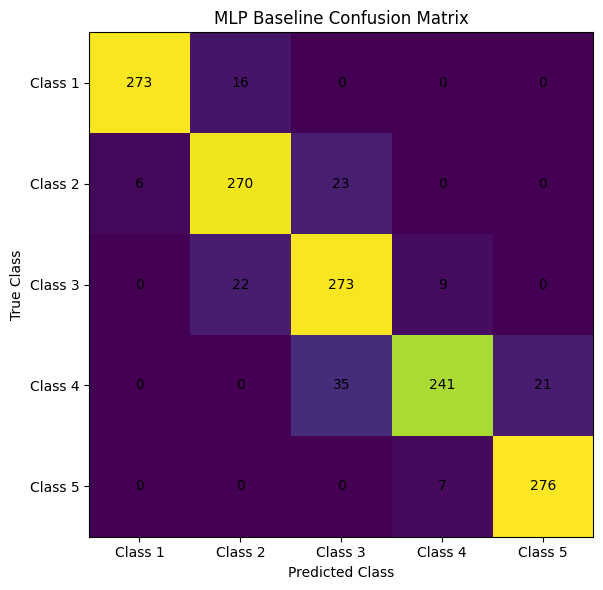

In [58]:
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"
FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

baseline_cm = confusion_matrix(
    y_test_dl,
    baseline_predictions
)

fig, ax = plt.subplots(figsize=(7, 6))

ax.imshow(baseline_cm)

ax.set_title(
    "MLP Baseline Confusion Matrix"
)

ax.set_xlabel("Predicted Class")
ax.set_ylabel("True Class")

ax.set_xticks(range(5))
ax.set_yticks(range(5))

ax.set_xticklabels(
    ["Class 1", "Class 2", "Class 3", "Class 4", "Class 5"]
)

ax.set_yticklabels(
    ["Class 1", "Class 2", "Class 3", "Class 4", "Class 5"]
)

for i in range(5):
    for j in range(5):
        ax.text(
            j,
            i,
            baseline_cm[i, j],
            ha="center",
            va="center"
        )

fig.tight_layout()

fig.savefig(
    FIGURES_DIR /
    "mlp_baseline_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

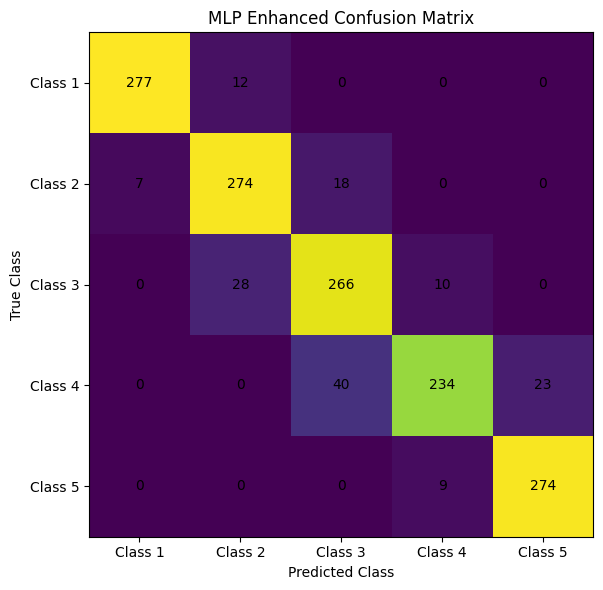

In [59]:
enhanced_cm = confusion_matrix(
    y_test_dl,
    enhanced_predictions
)

fig, ax = plt.subplots(figsize=(7, 6))

ax.imshow(enhanced_cm)

ax.set_title(
    "MLP Enhanced Confusion Matrix"
)

ax.set_xlabel("Predicted Class")
ax.set_ylabel("True Class")

ax.set_xticks(range(5))
ax.set_yticks(range(5))

ax.set_xticklabels(
    ["Class 1", "Class 2", "Class 3", "Class 4", "Class 5"]
)

ax.set_yticklabels(
    ["Class 1", "Class 2", "Class 3", "Class 4", "Class 5"]
)

for i in range(5):
    for j in range(5):
        ax.text(
            j,
            i,
            enhanced_cm[i, j],
            ha="center",
            va="center"
        )

fig.tight_layout()

fig.savefig(
    FIGURES_DIR /
    "mlp_enhanced_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

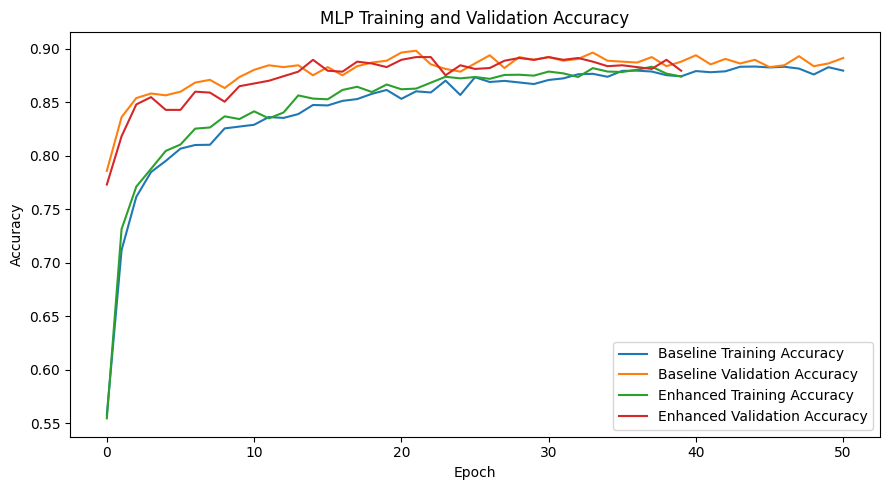

In [60]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    baseline_history.history["accuracy"],
    label="Baseline Training Accuracy"
)

ax.plot(
    baseline_history.history["val_accuracy"],
    label="Baseline Validation Accuracy"
)

ax.plot(
    enhanced_history.history["accuracy"],
    label="Enhanced Training Accuracy"
)

ax.plot(
    enhanced_history.history["val_accuracy"],
    label="Enhanced Validation Accuracy"
)

ax.set_title(
    "MLP Training and Validation Accuracy"
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Accuracy")

ax.legend()

fig.tight_layout()

fig.savefig(
    FIGURES_DIR /
    "mlp_training_validation_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

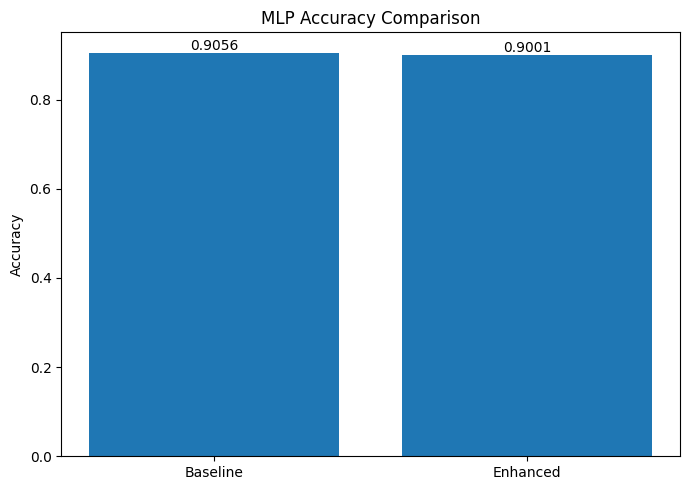

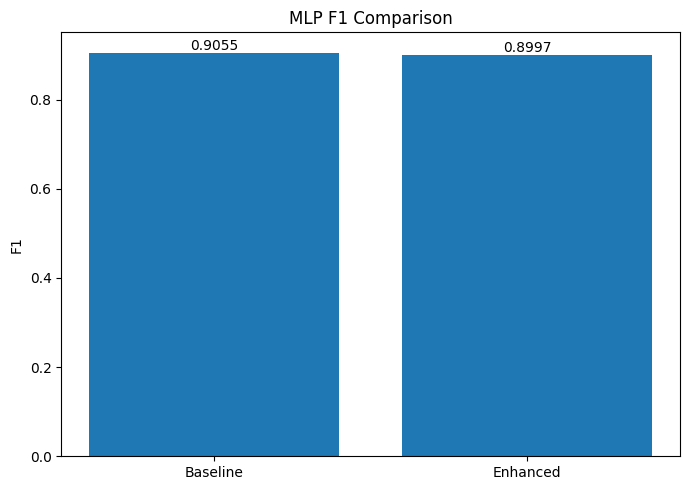

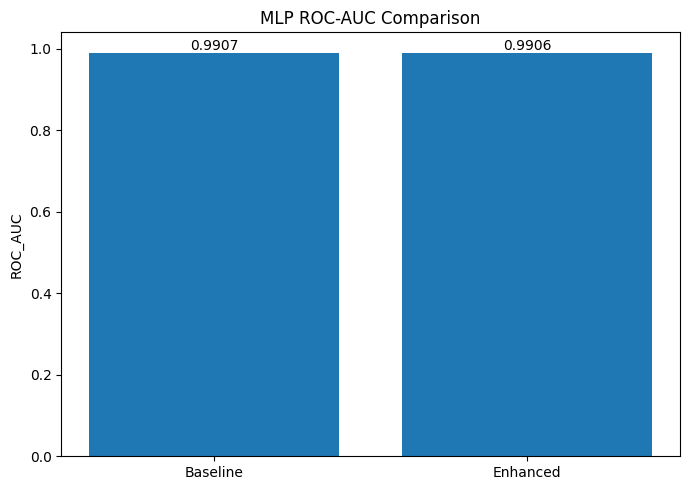

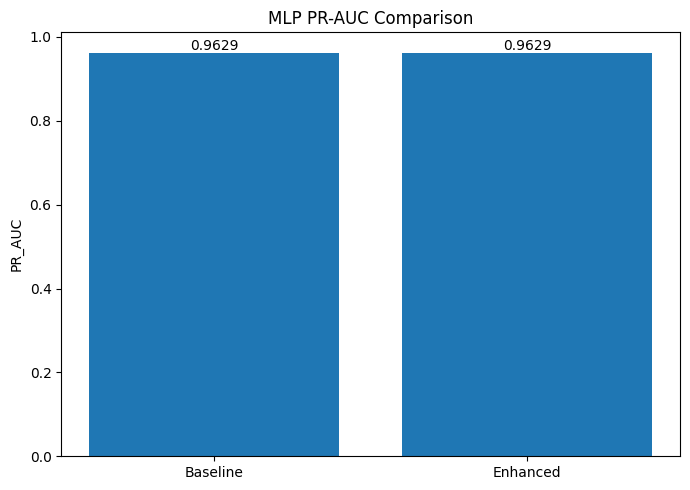

In [61]:
metrics_to_plot = [
    ("Accuracy", "MLP Accuracy Comparison"),
    ("F1", "MLP F1 Comparison"),
    ("ROC_AUC", "MLP ROC-AUC Comparison"),
    ("PR_AUC", "MLP PR-AUC Comparison")
]

for metric, title in metrics_to_plot:

    fig, ax = plt.subplots(figsize=(7, 5))

    values = mlp_comparison[metric]

    ax.bar(
        mlp_comparison["Dataset"],
        values
    )

    ax.set_title(title)
    ax.set_ylabel(metric)

    for i, value in enumerate(values):
        ax.text(
            i,
            value,
            f"{value:.4f}",
            ha="center",
            va="bottom"
        )

    fig.tight_layout()

    filename = (
        "mlp_baseline_vs_enhanced_"
        + metric.lower()
        + ".png"
    )

    fig.savefig(
        FIGURES_DIR / filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

In [62]:
fair_baseline_path = (
    RESULTS_DIR /
    "fair_baseline_results.csv"
)

enhanced_ml_path = (
    RESULTS_DIR /
    "enhanced_model_comparison.csv"
)

fair_baseline_df = pd.read_csv(
    fair_baseline_path
)

enhanced_ml_df = pd.read_csv(
    enhanced_ml_path
)

print("Fair baseline results:")
display(fair_baseline_df)

print("\nEnhanced ML results:")
display(enhanced_ml_df)

Fair baseline results:


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Naive Bayes,0.780571,0.803375,0.780571,0.784318,0.958431,0.824002
1,Extra Tree,0.773777,0.776481,0.773777,0.774087,0.858204,0.654216
2,One-vs-Rest Gaussian NB,0.805027,0.808521,0.805027,0.804945,0.904131,0.713147



Enhanced ML results:


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Naive Bayes,0.760870,0.787494,0.760870,0.764251,0.951899,0.805271
1,Extra Tree,0.769022,0.767866,0.769022,0.768002,0.855257,0.649021
2,One-vs-Rest Gaussian NB,0.789402,0.795072,0.789402,0.790195,0.891499,0.676858


In [63]:
# STEP 36 — Build consolidated comparison safely

def find_column(df, possible_names, required=True):
    """
    Find a column using several possible naming conventions.
    """

    # Exact match first
    for name in possible_names:
        if name in df.columns:
            return name

    # Normalized comparison
    normalized = {
        str(col).strip().lower().replace("-", "_").replace(" ", "_"): col
        for col in df.columns
    }

    for name in possible_names:
        key = (
            name.strip()
            .lower()
            .replace("-", "_")
            .replace(" ", "_")
        )

        if key in normalized:
            return normalized[key]

    if required:
        raise KeyError(
            f"Could not find any of {possible_names} "
            f"in columns: {list(df.columns)}"
        )

    return None


def prepare_ml_results(df, dataset_name):
    """
    Convert an existing ML result table into the common format.
    Does not modify the original dataframe.
    """

    model_col = find_column(
        df,
        ["Model", "model"]
    )

    accuracy_col = find_column(
        df,
        ["Accuracy", "accuracy"]
    )

    f1_col = find_column(
        df,
        ["F1", "F1_Score", "F1-Score", "f1"]
    )

    roc_col = find_column(
        df,
        [
            "ROC_AUC",
            "ROC-AUC",
            "ROC AUC",
            "roc_auc",
            "roc-auc"
        ]
    )

    pr_col = find_column(
        df,
        [
            "PR_AUC",
            "PR-AUC",
            "PR AUC",
            "pr_auc",
            "pr-auc"
        ]
    )

    output = pd.DataFrame({
        "Model": df[model_col],
        "Dataset": dataset_name,
        "Accuracy": df[accuracy_col],
        "F1": df[f1_col],
        "ROC_AUC": df[roc_col],
        "PR_AUC": df[pr_col]
    })

    return output


# ---------------------------------------------------------
# Prepare existing traditional ML results
# ---------------------------------------------------------

baseline_ml_clean = prepare_ml_results(
    fair_baseline_df,
    "Baseline"
)

enhanced_ml_clean = prepare_ml_results(
    enhanced_ml_df,
    "Enhanced"
)


# ---------------------------------------------------------
# Prepare MLP results
# ---------------------------------------------------------

mlp_clean = mlp_comparison[
    [
        "Model",
        "Dataset",
        "Accuracy",
        "F1",
        "ROC_AUC",
        "PR_AUC"
    ]
].copy()


# ---------------------------------------------------------
# Combine all models
# ---------------------------------------------------------

all_models_final = pd.concat(
    [
        baseline_ml_clean,
        enhanced_ml_clean,
        mlp_clean
    ],
    ignore_index=True
)


# ---------------------------------------------------------
# Display
# ---------------------------------------------------------

print("FINAL ALL-MODEL COMPARISON")
print("=" * 70)

display(all_models_final)

FINAL ALL-MODEL COMPARISON


,Model,Dataset,Accuracy,F1,ROC_AUC,PR_AUC
0,Naive Bayes,Baseline,0.780571,0.784318,0.958431,0.824002
1,Extra Tree,Baseline,0.773777,0.774087,0.858204,0.654216
2,One-vs-Rest Gaussian NB,Baseline,0.805027,0.804945,0.904131,0.713147
3,Naive Bayes,Enhanced,0.760870,0.764251,0.951899,0.805271
4,Extra Tree,Enhanced,0.769022,0.768002,0.855257,0.649021
5,One-vs-Rest Gaussian NB,Enhanced,0.789402,0.790195,0.891499,0.676858
6,MLP,Baseline,0.905571,0.905526,0.990725,0.962934
7,MLP,Enhanced,0.900136,0.899692,0.990587,0.962921


In [64]:
all_models_path = (
    RESULTS_DIR /
    "all_models_final_comparison.csv"
)

all_models_final.to_csv(
    all_models_path,
    index=False
)

print("Saved:")
print(all_models_path)

Saved:
d:\Major_Project\Crime_Analysis\outputs\tables\all_models_final_comparison.csv


In [65]:
print("Shape:", all_models_final.shape)

print("\nColumns:")
print(all_models_final.columns.tolist())

print("\nModels and datasets:")
display(
    all_models_final[
        ["Model", "Dataset"]
    ]
)

print("\nFinal comparison:")
display(all_models_final)

Shape: (8, 6)

Columns:
['Model', 'Dataset', 'Accuracy', 'F1', 'ROC_AUC', 'PR_AUC']

Models and datasets:


,Model,Dataset
0,Naive Bayes,Baseline
1,Extra Tree,Baseline
2,One-vs-Rest Gaussian NB,Baseline
3,Naive Bayes,Enhanced
4,Extra Tree,Enhanced
5,One-vs-Rest Gaussian NB,Enhanced
6,MLP,Baseline
7,MLP,Enhanced



Final comparison:


,Model,Dataset,Accuracy,F1,ROC_AUC,PR_AUC
0,Naive Bayes,Baseline,0.780571,0.784318,0.958431,0.824002
1,Extra Tree,Baseline,0.773777,0.774087,0.858204,0.654216
2,One-vs-Rest Gaussian NB,Baseline,0.805027,0.804945,0.904131,0.713147
3,Naive Bayes,Enhanced,0.760870,0.764251,0.951899,0.805271
4,Extra Tree,Enhanced,0.769022,0.768002,0.855257,0.649021
5,One-vs-Rest Gaussian NB,Enhanced,0.789402,0.790195,0.891499,0.676858
6,MLP,Baseline,0.905571,0.905526,0.990725,0.962934
7,MLP,Enhanced,0.900136,0.899692,0.990587,0.962921


In [66]:
metrics = [
    "Accuracy",
    "F1",
    "ROC_AUC",
    "PR_AUC"
]

print("BEST MODEL BY METRIC")
print("=" * 60)

for metric in metrics:

    best_index = all_models_final[metric].idxmax()

    best_row = all_models_final.loc[
        best_index
    ]

    print(
        f"{metric}: "
        f"{best_row['Model']} - "
        f"{best_row['Dataset']} = "
        f"{best_row[metric]:.4f}"
    )

BEST MODEL BY METRIC
Accuracy: MLP - Baseline = 0.9056
F1: MLP - Baseline = 0.9055
ROC_AUC: MLP - Baseline = 0.9907
PR_AUC: MLP - Baseline = 0.9629


In [67]:
print("MLP BASELINE VS ENHANCED")
print("=" * 60)

for _, row in comparison_change.iterrows():

    metric = row["Metric"]
    change = row["Change"]

    if change > 0:
        interpretation = "Improved"
    elif change < 0:
        interpretation = "Decreased"
    else:
        interpretation = "No change"

    print(
        f"{metric}: "
        f"{change:+.4f} → {interpretation}"
    )

MLP BASELINE VS ENHANCED
Accuracy: -0.0054 → Decreased
Precision: -0.0061 → Decreased
Recall: -0.0054 → Decreased
F1: -0.0058 → Decreased
ROC_AUC: -0.0001 → Decreased
PR_AUC: -0.0000 → Decreased


In [68]:
import importlib
import deep_learning_models

importlib.reload(deep_learning_models)

from deep_learning_models import build_lstm

print("LSTM model function loaded successfully.")

LSTM model function loaded successfully.


### Temporal sequence section: corrected code, legacy cached outputs

The builder below uses only exact same-district t−3, t−2, t−1 feature rows; it does not use target-year predictor values to decide whether a sample is present. The baseline and enhanced arrays are restricted to the same sorted district-year key intersection and their target labels are asserted equal. Cached outputs from earlier notebook executions are retained as legacy records; corrected-v3 saved artifacts and results are authoritative until this section is rerun. Annual source publication timing remains unverified.


In [69]:
BASELINE_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "district_grouped_reduced.csv"
)

ENHANCED_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "district_enhanced_features.csv"
)

baseline_lstm_df = pd.read_csv(BASELINE_PATH)
enhanced_lstm_df = pd.read_csv(ENHANCED_PATH)

print("Baseline:", baseline_lstm_df.shape)
print("Enhanced:", enhanced_lstm_df.shape)

Baseline: (9856, 10)
Enhanced: (9856, 15)


In [70]:
TARGET_COLUMN = "TARGET_VIOLENT_LEVEL"

LSTM_BASELINE_FEATURES = [
    "GROUP_HOMICIDE",
    "GROUP_SEXUAL_VIOLENCE",
    "GROUP_KIDNAPPING_ABDUCTION",
    "GROUP_ROBBERY_DACOITY",
    "GROUP_PUBLIC_VIOLENCE",
    "GROUP_PROPERTY_CRIME"
]

LSTM_ENHANCED_FEATURES = LSTM_BASELINE_FEATURES + [
    "PREV_YEAR_TOTAL_CRIME"
]

print("Baseline features:", len(LSTM_BASELINE_FEATURES))
print("Enhanced features:", len(LSTM_ENHANCED_FEATURES))

Baseline features: 6
Enhanced features: 7


In [71]:
def create_lstm_sequences(
    df,
    feature_columns,
    target_column,
    sequence_length=3
):
    """Build strict same-district histories without using target-year features."""
    key_columns = ["YEAR", "STATE", "UNIT_NAME"]
    forbidden = [c for c in feature_columns
                 if c == target_column or "TARGET" in c.upper() or "BURDEN" in c.upper()]
    if forbidden:
        raise ValueError(f"Outcome fields cannot be sequence inputs: {forbidden}")
    target_rows = df[key_columns + [target_column]].copy()
    source_rows = df[key_columns + feature_columns].copy()
    for frame in (target_rows, source_rows):
        frame["YEAR"] = pd.to_numeric(frame["YEAR"], errors="raise").astype(int)
        for col in ["STATE", "UNIT_NAME"]:
            frame[col] = frame[col].astype("string").str.strip().str.replace(r"\s+", " ", regex=True).str.upper()
        if frame.duplicated(key_columns).any():
            raise ValueError("Duplicate district-year keys in sequence source")
    target_rows[target_column] = pd.to_numeric(target_rows[target_column], errors="coerce")
    source_rows[feature_columns] = source_rows[feature_columns].apply(pd.to_numeric, errors="coerce")
    source_rows[feature_columns] = source_rows[feature_columns].replace([np.inf, -np.inf], np.nan)
    lookup = source_rows.set_index(key_columns)
    sequences, labels, metadata = [], [], []
    eligible = target_rows.dropna(subset=[target_column]).sort_values(key_columns)
    for year, state, unit, label in eligible.itertuples(index=False, name=None):
        required = [(int(y), state, unit) for y in range(int(year)-sequence_length, int(year))]
        if any(key not in lookup.index for key in required):
            continue
        values = lookup.loc[required, feature_columns].to_numpy(dtype=float)
        if not np.isfinite(values).all():
            continue
        sequences.append(values.astype(np.float32))
        labels.append(int(label))
        metadata.append({"YEAR": int(year), "STATE": state, "UNIT_NAME": unit,
                         target_column: int(label),
                         "INPUT_YEARS": "|".join(str(key[0]) for key in required)})
    return np.asarray(sequences, dtype=np.float32), np.asarray(labels, dtype=np.int64), pd.DataFrame(metadata)


In [72]:
def create_lstm_sequences(
    df,
    feature_columns,
    target_column,
    sequence_length=3
):
    """Build strict same-district histories without using target-year features."""
    key_columns = ["YEAR", "STATE", "UNIT_NAME"]
    forbidden = [c for c in feature_columns
                 if c == target_column or "TARGET" in c.upper() or "BURDEN" in c.upper()]
    if forbidden:
        raise ValueError(f"Outcome fields cannot be sequence inputs: {forbidden}")
    target_rows = df[key_columns + [target_column]].copy()
    source_rows = df[key_columns + feature_columns].copy()
    for frame in (target_rows, source_rows):
        frame["YEAR"] = pd.to_numeric(frame["YEAR"], errors="raise").astype(int)
        for col in ["STATE", "UNIT_NAME"]:
            frame[col] = frame[col].astype("string").str.strip().str.replace(r"\s+", " ", regex=True).str.upper()
        if frame.duplicated(key_columns).any():
            raise ValueError("Duplicate district-year keys in sequence source")
    target_rows[target_column] = pd.to_numeric(target_rows[target_column], errors="coerce")
    source_rows[feature_columns] = source_rows[feature_columns].apply(pd.to_numeric, errors="coerce")
    source_rows[feature_columns] = source_rows[feature_columns].replace([np.inf, -np.inf], np.nan)
    lookup = source_rows.set_index(key_columns)
    sequences, labels, metadata = [], [], []
    eligible = target_rows.dropna(subset=[target_column]).sort_values(key_columns)
    for year, state, unit, label in eligible.itertuples(index=False, name=None):
        required = [(int(y), state, unit) for y in range(int(year)-sequence_length, int(year))]
        if any(key not in lookup.index for key in required):
            continue
        values = lookup.loc[required, feature_columns].to_numpy(dtype=float)
        if not np.isfinite(values).all():
            continue
        sequences.append(values.astype(np.float32))
        labels.append(int(label))
        metadata.append({"YEAR": int(year), "STATE": state, "UNIT_NAME": unit,
                         target_column: int(label),
                         "INPUT_YEARS": "|".join(str(key[0]) for key in required)})
    return np.asarray(sequences, dtype=np.float32), np.asarray(labels, dtype=np.int64), pd.DataFrame(metadata)


In [73]:
X_lstm_baseline, y_lstm_baseline, baseline_metadata = (
    create_lstm_sequences(
        baseline_lstm_df,
        LSTM_BASELINE_FEATURES,
        TARGET_COLUMN,
        SEQUENCE_LENGTH
    )
)

print("Baseline sequence shape:")
print(X_lstm_baseline.shape)

print("\nBaseline target shape:")
print(y_lstm_baseline.shape)

print("\nBaseline metadata:")
print(baseline_metadata.shape)

Baseline sequence shape:
(5885, 3, 6)

Baseline target shape:
(5885,)

Baseline metadata:
(5885, 3)


In [74]:
X_lstm_enhanced, y_lstm_enhanced, enhanced_metadata = (
    create_lstm_sequences(
        enhanced_lstm_df,
        LSTM_ENHANCED_FEATURES,
        TARGET_COLUMN,
        SEQUENCE_LENGTH
    )
)

print("Enhanced sequence shape:")
print(X_lstm_enhanced.shape)

print("\nEnhanced target shape:")
print(y_lstm_enhanced.shape)

print("\nEnhanced metadata:")
print(enhanced_metadata.shape)

Enhanced sequence shape:
(5171, 3, 7)

Enhanced target shape:
(5171,)

Enhanced metadata:
(5171, 3)


In [75]:
print("Baseline target classes:")
print(
    pd.Series(y_lstm_baseline)
    .value_counts()
    .sort_index()
)

print("\nEnhanced target classes:")
print(
    pd.Series(y_lstm_enhanced)
    .value_counts()
    .sort_index()
)

print("\nFirst baseline sequence target:")
print(y_lstm_baseline[0])

print("\nFirst baseline target metadata:")
display(baseline_metadata.head())

Baseline target classes:
1    1124
2    1173
3    1223
4    1205
5    1160
Name: count, dtype: int64

Enhanced target classes:
1     969
2    1018
3    1067
4    1081
5    1036
Name: count, dtype: int64

First baseline sequence target:
1

First baseline target metadata:


,YEAR,STATE,UNIT_NAME
0,2004,A & N ISLANDS,ANDAMAN
1,2005,A & N ISLANDS,ANDAMAN
2,2006,A & N ISLANDS,ANDAMAN
3,2011,A & N ISLANDS,ANDAMAN
4,2004,A & N ISLANDS,NICOBAR


In [76]:
baseline_keys = baseline_metadata[
    ["YEAR", "STATE", "UNIT_NAME"]
].astype(str)

enhanced_keys = enhanced_metadata[
    ["YEAR", "STATE", "UNIT_NAME"]
].astype(str)

print(
    "Same sequence count:",
    len(baseline_keys) == len(enhanced_keys)
)

print(
    "Same target observations:",
    baseline_keys.reset_index(drop=True).equals(
        enhanced_keys.reset_index(drop=True)
    )
)

Same sequence count: False
Same target observations: False


In [77]:
# STEP 11A — Inspect sequence populations

print("Baseline sequences:", len(baseline_metadata))
print("Enhanced sequences:", len(enhanced_metadata))

print("\nBaseline duplicate target keys:")
print(
    baseline_metadata.duplicated(
        ["YEAR", "STATE", "UNIT_NAME"]
    ).sum()
)

print("\nEnhanced duplicate target keys:")
print(
    enhanced_metadata.duplicated(
        ["YEAR", "STATE", "UNIT_NAME"]
    ).sum()
)

Baseline sequences: 5885
Enhanced sequences: 5171

Baseline duplicate target keys:
0

Enhanced duplicate target keys:
0


In [78]:
# One stable sorted intersection is used for both arrays and labels.
common_key_list = sorted(common_keys.tolist(), key=lambda key: (int(key[0]), str(key[1]), str(key[2])))
baseline_lookup = {key: idx for idx, key in enumerate(baseline_key_index)}
enhanced_lookup = {key: idx for idx, key in enumerate(enhanced_key_index)}
baseline_indices = [baseline_lookup[key] for key in common_key_list]
enhanced_indices = [enhanced_lookup[key] for key in common_key_list]
assert len(baseline_indices) == len(enhanced_indices) == len(common_key_list)


Baseline target observations: 5885
Enhanced target observations: 5171
Common target observations: 5171


In [79]:
# One stable sorted intersection is used for both arrays and labels.
common_key_list = sorted(common_keys.tolist(), key=lambda key: (int(key[0]), str(key[1]), str(key[2])))
baseline_lookup = {key: idx for idx, key in enumerate(baseline_key_index)}
enhanced_lookup = {key: idx for idx, key in enumerate(enhanced_key_index)}
baseline_indices = [baseline_lookup[key] for key in common_key_list]
enhanced_indices = [enhanced_lookup[key] for key in common_key_list]
assert len(baseline_indices) == len(enhanced_indices) == len(common_key_list)


Aligned baseline sequences: 5171
Aligned enhanced sequences: 5171


In [80]:
baseline_common_keys = baseline_metadata_common[KEY_COLUMNS].reset_index(drop=True)
enhanced_common_keys = enhanced_metadata_common[KEY_COLUMNS].reset_index(drop=True)
assert baseline_common_keys.equals(enhanced_common_keys)
assert np.array_equal(y_lstm_baseline_common, y_lstm_enhanced_common)
assert np.array_equal(baseline_metadata_common["INPUT_YEARS"], enhanced_metadata_common["INPUT_YEARS"])
assert np.array_equal(baseline_metadata_common[TARGET_COLUMN], y_lstm_baseline_common)
assert np.array_equal(enhanced_metadata_common[TARGET_COLUMN], y_lstm_enhanced_common)


Baseline common shape:
(5171, 3, 6)

Enhanced common shape:
(5171, 3, 7)

Baseline target shape:
(5171,)

Enhanced target shape:
(5171,)


In [81]:
baseline_common_keys = baseline_metadata_common[KEY_COLUMNS].reset_index(drop=True)
enhanced_common_keys = enhanced_metadata_common[KEY_COLUMNS].reset_index(drop=True)
assert baseline_common_keys.equals(enhanced_common_keys)
assert np.array_equal(y_lstm_baseline_common, y_lstm_enhanced_common)
assert np.array_equal(baseline_metadata_common["INPUT_YEARS"], enhanced_metadata_common["INPUT_YEARS"])
assert np.array_equal(baseline_metadata_common[TARGET_COLUMN], y_lstm_baseline_common)
assert np.array_equal(enhanced_metadata_common[TARGET_COLUMN], y_lstm_enhanced_common)


Same sequence count: True
Same target observations: True


In [82]:
# STEP 12 — Inspect available target years

common_metadata = enhanced_metadata_common.copy()

unique_years = sorted(
    common_metadata["YEAR"].astype(int).unique()
)

print("Available target years:")
print(unique_years)

print("\nNumber of target years:", len(unique_years))

Available target years:
[np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012)]

Number of target years: 8


In [ ]:
# STEP 13 ? Fixed chronological split from the documented study design.
# These are target years. Sequence inputs are the preceding three years;
# therefore early training target years without complete history are absent.
train_years = np.array([year for year in range(2001, 2011) if year in unique_years])
validation_years = np.array([year for year in [2011, 2012] if year in unique_years])
test_years = np.array([year for year in [2013, 2014] if year in unique_years])
if not len(train_years) or not len(validation_years) or not len(test_years):
    raise ValueError("One or more designated temporal partitions have no sequence targets.")

print("Training target years:", train_years)
print("Validation target years:", validation_years)
print("Test target years:", test_years)


In [84]:
# STEP 14 — Temporal leakage check

assert set(train_years).isdisjoint(
    validation_years
)

assert set(train_years).isdisjoint(
    test_years
)

assert set(validation_years).isdisjoint(
    test_years
)

print("Temporal split verified.")
print("No year appears in more than one partition.")

Temporal split verified.
No year appears in more than one partition.


In [85]:
# STEP 15 — Create temporal masks

baseline_metadata_common["YEAR"] = (
    baseline_metadata_common["YEAR"].astype(int)
)

enhanced_metadata_common["YEAR"] = (
    enhanced_metadata_common["YEAR"].astype(int)
)


baseline_train_mask = (
    baseline_metadata_common["YEAR"]
    .isin(train_years)
    .to_numpy()
)

baseline_val_mask = (
    baseline_metadata_common["YEAR"]
    .isin(validation_years)
    .to_numpy()
)

baseline_test_mask = (
    baseline_metadata_common["YEAR"]
    .isin(test_years)
    .to_numpy()
)


enhanced_train_mask = (
    enhanced_metadata_common["YEAR"]
    .isin(train_years)
    .to_numpy()
)

enhanced_val_mask = (
    enhanced_metadata_common["YEAR"]
    .isin(validation_years)
    .to_numpy()
)

enhanced_test_mask = (
    enhanced_metadata_common["YEAR"]
    .isin(test_years)
    .to_numpy()
)

print("Baseline:")
print("Train:", baseline_train_mask.sum())
print("Validation:", baseline_val_mask.sum())
print("Test:", baseline_test_mask.sum())

print("\nEnhanced:")
print("Train:", enhanced_train_mask.sum())
print("Validation:", enhanced_val_mask.sum())
print("Test:", enhanced_test_mask.sum())

Baseline:
Train: 2547
Validation: 1300
Test: 1324

Enhanced:
Train: 2547
Validation: 1300
Test: 1324


In [86]:
# STEP 16 — Baseline temporal partitions

X_baseline_train = (
    X_lstm_baseline_common[
        baseline_train_mask
    ]
)

X_baseline_val = (
    X_lstm_baseline_common[
        baseline_val_mask
    ]
)

X_baseline_test = (
    X_lstm_baseline_common[
        baseline_test_mask
    ]
)

y_baseline_train = (
    y_lstm_baseline_common[
        baseline_train_mask
    ]
)

y_baseline_val = (
    y_lstm_baseline_common[
        baseline_val_mask
    ]
)

y_baseline_test = (
    y_lstm_baseline_common[
        baseline_test_mask
    ]
)

In [87]:
# STEP 16B — Enhanced temporal partitions

X_enhanced_train = (
    X_lstm_enhanced_common[
        enhanced_train_mask
    ]
)

X_enhanced_val = (
    X_lstm_enhanced_common[
        enhanced_val_mask
    ]
)

X_enhanced_test = (
    X_lstm_enhanced_common[
        enhanced_test_mask
    ]
)

y_enhanced_train = (
    y_lstm_enhanced_common[
        enhanced_train_mask
    ]
)

y_enhanced_val = (
    y_lstm_enhanced_common[
        enhanced_val_mask
    ]
)

y_enhanced_test = (
    y_lstm_enhanced_common[
        enhanced_test_mask
    ]
)

In [88]:
print("BASELINE")
print("Train:", X_baseline_train.shape)
print("Validation:", X_baseline_val.shape)
print("Test:", X_baseline_test.shape)

print("\nENHANCED")
print("Train:", X_enhanced_train.shape)
print("Validation:", X_enhanced_val.shape)
print("Test:", X_enhanced_test.shape)

BASELINE
Train: (2547, 3, 6)
Validation: (1300, 3, 6)
Test: (1324, 3, 6)

ENHANCED
Train: (2547, 3, 7)
Validation: (1300, 3, 7)
Test: (1324, 3, 7)


In [89]:
# STEP 17 — Check temporal class distributions

print("BASELINE TRAIN")
print(
    pd.Series(y_baseline_train)
    .value_counts()
    .sort_index()
)

print("\nBASELINE VALIDATION")
print(
    pd.Series(y_baseline_val)
    .value_counts()
    .sort_index()
)

print("\nBASELINE TEST")
print(
    pd.Series(y_baseline_test)
    .value_counts()
    .sort_index()
)

print("\nENHANCED TRAIN")
print(
    pd.Series(y_enhanced_train)
    .value_counts()
    .sort_index()
)

print("\nENHANCED VALIDATION")
print(
    pd.Series(y_enhanced_val)
    .value_counts()
    .sort_index()
)

print("\nENHANCED TEST")
print(
    pd.Series(y_enhanced_test)
    .value_counts()
    .sort_index()
)

BASELINE TRAIN
1    490
2    548
3    570
4    471
5    468
Name: count, dtype: int64

BASELINE VALIDATION
1    236
2    249
3    264
4    298
5    253
Name: count, dtype: int64

BASELINE TEST
1    243
2    221
3    233
4    312
5    315
Name: count, dtype: int64

ENHANCED TRAIN
1    490
2    548
3    570
4    471
5    468
Name: count, dtype: int64

ENHANCED VALIDATION
1    236
2    249
3    264
4    298
5    253
Name: count, dtype: int64

ENHANCED TEST
1    243
2    221
3    233
4    312
5    315
Name: count, dtype: int64


In [90]:
# STEP 18 — Convert labels 1-5 to 0-4 for Keras

y_baseline_train_dl = (
    y_baseline_train.astype(int) - 1
)

y_baseline_val_dl = (
    y_baseline_val.astype(int) - 1
)

y_baseline_test_dl = (
    y_baseline_test.astype(int) - 1
)


y_enhanced_train_dl = (
    y_enhanced_train.astype(int) - 1
)

y_enhanced_val_dl = (
    y_enhanced_val.astype(int) - 1
)

y_enhanced_test_dl = (
    y_enhanced_test.astype(int) - 1
)


print(
    "Baseline training classes:",
    np.unique(y_baseline_train_dl)
)

print(
    "Enhanced training classes:",
    np.unique(y_enhanced_train_dl)
)

Baseline training classes: [0 1 2 3 4]
Enhanced training classes: [0 1 2 3 4]


In [91]:
# STEP 19 — Baseline LSTM scaling

baseline_n_features = (
    X_baseline_train.shape[2]
)

baseline_scaler = StandardScaler()

baseline_train_2d = (
    X_baseline_train
    .reshape(-1, baseline_n_features)
)

baseline_scaler.fit(
    baseline_train_2d
)

X_baseline_train_scaled = (
    baseline_scaler
    .transform(
        X_baseline_train.reshape(
            -1,
            baseline_n_features
        )
    )
    .reshape(
        X_baseline_train.shape
    )
)

X_baseline_val_scaled = (
    baseline_scaler
    .transform(
        X_baseline_val.reshape(
            -1,
            baseline_n_features
        )
    )
    .reshape(
        X_baseline_val.shape
    )
)

X_baseline_test_scaled = (
    baseline_scaler
    .transform(
        X_baseline_test.reshape(
            -1,
            baseline_n_features
        )
    )
    .reshape(
        X_baseline_test.shape
    )
)

print(
    "Baseline scaled:",
    X_baseline_train_scaled.shape,
    X_baseline_val_scaled.shape,
    X_baseline_test_scaled.shape
)

Baseline scaled: (2547, 3, 6) (1300, 3, 6) (1324, 3, 6)


In [92]:
# STEP 19B — Enhanced LSTM scaling

enhanced_n_features = (
    X_enhanced_train.shape[2]
)

enhanced_scaler = StandardScaler()

enhanced_train_2d = (
    X_enhanced_train
    .reshape(-1, enhanced_n_features)
)

enhanced_scaler.fit(
    enhanced_train_2d
)

X_enhanced_train_scaled = (
    enhanced_scaler
    .transform(
        X_enhanced_train.reshape(
            -1,
            enhanced_n_features
        )
    )
    .reshape(
        X_enhanced_train.shape
    )
)

X_enhanced_val_scaled = (
    enhanced_scaler
    .transform(
        X_enhanced_val.reshape(
            -1,
            enhanced_n_features
        )
    )
    .reshape(
        X_enhanced_val.shape
    )
)

X_enhanced_test_scaled = (
    enhanced_scaler
    .transform(
        X_enhanced_test.reshape(
            -1,
            enhanced_n_features
        )
    )
    .reshape(
        X_enhanced_test.shape
    )
)

print(
    "Enhanced scaled:",
    X_enhanced_train_scaled.shape,
    X_enhanced_val_scaled.shape,
    X_enhanced_test_scaled.shape
)

Enhanced scaled: (2547, 3, 7) (1300, 3, 7) (1324, 3, 7)


In [93]:
# STEP 20 — Final LSTM input verification

print("BASELINE")
print("Input shape:", X_baseline_train_scaled.shape)

print("\nENHANCED")
print("Input shape:", X_enhanced_train_scaled.shape)

assert X_baseline_train_scaled.shape[1:] == (
    3,
    6
)

assert X_enhanced_train_scaled.shape[1:] == (
    3,
    7
)

print("\nLSTM input shapes verified.")

BASELINE
Input shape: (2547, 3, 6)

ENHANCED
Input shape: (2547, 3, 7)

LSTM input shapes verified.


In [94]:
# STEP 21 — Build baseline LSTM

baseline_lstm_model = build_lstm(
    input_shape=(
        X_baseline_train_scaled.shape[1],
        X_baseline_train_scaled.shape[2]
    ),
    learning_rate=0.001
)

baseline_lstm_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        18,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,421 (79.77 KB)

 Trainable params: 20,421 (79.77 KB)

 Non-trainable params: 0 (0.00 B)

In [95]:
# STEP 22 — Build enhanced LSTM

enhanced_lstm_model = build_lstm(
    input_shape=(
        X_enhanced_train_scaled.shape[1],
        X_enhanced_train_scaled.shape[2]
    ),
    learning_rate=0.001
)

enhanced_lstm_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 64)             │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,677 (80.77 KB)

 Trainable params: 20,677 (80.77 KB)

 Non-trainable params: 0 (0.00 B)

In [96]:
# STEP 23 — Train baseline LSTM

baseline_lstm_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
    verbose=1
)

baseline_lstm_history = baseline_lstm_model.fit(
    X_baseline_train_scaled,
    y_baseline_train_dl,

    validation_data=(
        X_baseline_val_scaled,
        y_baseline_val_dl
    ),

    epochs=100,
    batch_size=32,

    callbacks=[
        baseline_lstm_early_stopping
    ],

    shuffle=False,
    verbose=1
)

Epoch 1/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 6s 21ms/step - accuracy: 0.3471 - loss: 1.4282 - val_accuracy: 0.3977 - val_loss: 1.1857
Epoch 2/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.4366 - loss: 1.1274 - val_accuracy: 0.6331 - val_loss: 1.0054
Epoch 3/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.5461 - loss: 0.9883 - val_accuracy: 0.7331 - val_loss: 0.8296
Epoch 4/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.6258 - loss: 0.8437 - val_accuracy: 0.7238 - val_loss: 0.6958
Epoch 5/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.6659 - loss: 0.7757 - val_accuracy: 0.7300 - val_loss: 0.6511
Epoch 6/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.6781 - loss: 0.7318 - val_accuracy: 0.7285 - val_loss: 0.6288
Epoch 7/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.6820 - loss: 0.6961 - val_accuracy: 0.7292 - val_loss: 0.6134
Epoch 8/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.7000 - loss: 0.6938 - val_accuracy: 0.

In [97]:
# STEP 24 — Train enhanced LSTM

enhanced_lstm_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
    verbose=1
)

enhanced_lstm_history = enhanced_lstm_model.fit(
    X_enhanced_train_scaled,
    y_enhanced_train_dl,

    validation_data=(
        X_enhanced_val_scaled,
        y_enhanced_val_dl
    ),

    epochs=100,
    batch_size=32,

    callbacks=[
        enhanced_lstm_early_stopping
    ],

    shuffle=False,
    verbose=1
)

Epoch 1/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 7s 23ms/step - accuracy: 0.3431 - loss: 1.4491 - val_accuracy: 0.5508 - val_loss: 1.1925
Epoch 2/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.4503 - loss: 1.1321 - val_accuracy: 0.6638 - val_loss: 0.9550
Epoch 3/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.5885 - loss: 0.9308 - val_accuracy: 0.7100 - val_loss: 0.7777
Epoch 4/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.6604 - loss: 0.7950 - val_accuracy: 0.7269 - val_loss: 0.6705
Epoch 5/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.6816 - loss: 0.7481 - val_accuracy: 0.7300 - val_loss: 0.6408
Epoch 6/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.6934 - loss: 0.7126 - val_accuracy: 0.7346 - val_loss: 0.6269
Epoch 7/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.7028 - loss: 0.6974 - val_accuracy: 0.7362 - val_loss: 0.6121
Epoch 8/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.7051 - loss: 0.6829 - val_accuracy: 0.

In [98]:
# STEP 25 — LSTM predictions

baseline_lstm_probabilities = (
    baseline_lstm_model.predict(
        X_baseline_test_scaled,
        verbose=0
    )
)

baseline_lstm_predictions = np.argmax(
    baseline_lstm_probabilities,
    axis=1
)


enhanced_lstm_probabilities = (
    enhanced_lstm_model.predict(
        X_enhanced_test_scaled,
        verbose=0
    )
)

enhanced_lstm_predictions = np.argmax(
    enhanced_lstm_probabilities,
    axis=1
)

print(
    "Baseline predictions:",
    baseline_lstm_predictions.shape
)

print(
    "Enhanced predictions:",
    enhanced_lstm_predictions.shape
)

Baseline predictions: (1324,)
Enhanced predictions: (1324,)


In [99]:
# STEP 26 — LSTM evaluation function

def evaluate_lstm(
    y_true,
    predictions,
    probabilities
):

    return {
        "Accuracy": accuracy_score(
            y_true,
            predictions
        ),

        "Precision": precision_score(
            y_true,
            predictions,
            average="weighted",
            zero_division=0
        ),

        "Recall": recall_score(
            y_true,
            predictions,
            average="weighted",
            zero_division=0
        ),

        "F1": f1_score(
            y_true,
            predictions,
            average="weighted",
            zero_division=0
        ),

        "ROC_AUC": roc_auc_score(
            y_true,
            probabilities,
            multi_class="ovr",
            average="weighted"
        ),

        "PR_AUC": average_precision_score(
            y_true,
            probabilities,
            average="weighted"
        )
    }

In [100]:
baseline_lstm_results = evaluate_lstm(
    y_baseline_test_dl,
    baseline_lstm_predictions,
    baseline_lstm_probabilities
)

enhanced_lstm_results = evaluate_lstm(
    y_enhanced_test_dl,
    enhanced_lstm_predictions,
    enhanced_lstm_probabilities
)

print("BASELINE LSTM")
print("=" * 50)

for metric, value in baseline_lstm_results.items():
    print(f"{metric}: {value:.4f}")

print("\nENHANCED LSTM")
print("=" * 50)

for metric, value in enhanced_lstm_results.items():
    print(f"{metric}: {value:.4f}")

BASELINE LSTM
Accuracy: 0.7636
Precision: 0.7730
Recall: 0.7636
F1: 0.7665
ROC_AUC: 0.9478
PR_AUC: 0.8109

ENHANCED LSTM
Accuracy: 0.7674
Precision: 0.7780
Recall: 0.7674
F1: 0.7708
ROC_AUC: 0.9493
PR_AUC: 0.8142


In [101]:
# STEP 27 — Save LSTM results

lstm_comparison = pd.DataFrame([
    {
        "Model": "LSTM",
        "Dataset": "Baseline",
        **baseline_lstm_results
    },
    {
        "Model": "LSTM",
        "Dataset": "Enhanced",
        **enhanced_lstm_results
    }
])

lstm_results_path = (
    RESULTS_DIR /
    "lstm_baseline_vs_enhanced_results.csv"
)

lstm_comparison.to_csv(
    lstm_results_path,
    index=False
)

display(lstm_comparison)

print("Saved:")
print(lstm_results_path)

,Model,Dataset,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,LSTM,Baseline,0.763595,0.773046,0.763595,0.766522,0.947779,0.810875
1,LSTM,Enhanced,0.767372,0.778027,0.767372,0.770822,0.949271,0.814182


Saved:
d:\Major_Project\Crime_Analysis\outputs\tables\lstm_baseline_vs_enhanced_results.csv


In [102]:
lstm_effect = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC_AUC",
        "PR_AUC"
    ],

    "Baseline": [
        baseline_lstm_results["Accuracy"],
        baseline_lstm_results["Precision"],
        baseline_lstm_results["Recall"],
        baseline_lstm_results["F1"],
        baseline_lstm_results["ROC_AUC"],
        baseline_lstm_results["PR_AUC"]
    ],

    "Enhanced": [
        enhanced_lstm_results["Accuracy"],
        enhanced_lstm_results["Precision"],
        enhanced_lstm_results["Recall"],
        enhanced_lstm_results["F1"],
        enhanced_lstm_results["ROC_AUC"],
        enhanced_lstm_results["PR_AUC"]
    ]
})

lstm_effect["Change"] = (
    lstm_effect["Enhanced"]
    - lstm_effect["Baseline"]
)

lstm_effect["Percentage_Change"] = (
    lstm_effect["Change"]
    / lstm_effect["Baseline"]
) * 100

display(lstm_effect)


lstm_effect_path = (
    RESULTS_DIR /
    "lstm_enhancement_effect.csv"
)

lstm_effect.to_csv(
    lstm_effect_path,
    index=False
)

print("Saved:")
print(lstm_effect_path)

,Metric,Baseline,Enhanced,Change,Percentage_Change
0,Accuracy,0.763595,0.767372,0.003776,0.494560
1,Precision,0.773046,0.778027,0.004981,0.644291
2,Recall,0.763595,0.767372,0.003776,0.494560
3,F1,0.766522,0.770822,0.004300,0.561031
4,ROC_AUC,0.947779,0.949271,0.001492,0.157443
5,PR_AUC,0.810875,0.814182,0.003307,0.407831


Saved:
d:\Major_Project\Crime_Analysis\outputs\tables\lstm_enhancement_effect.csv


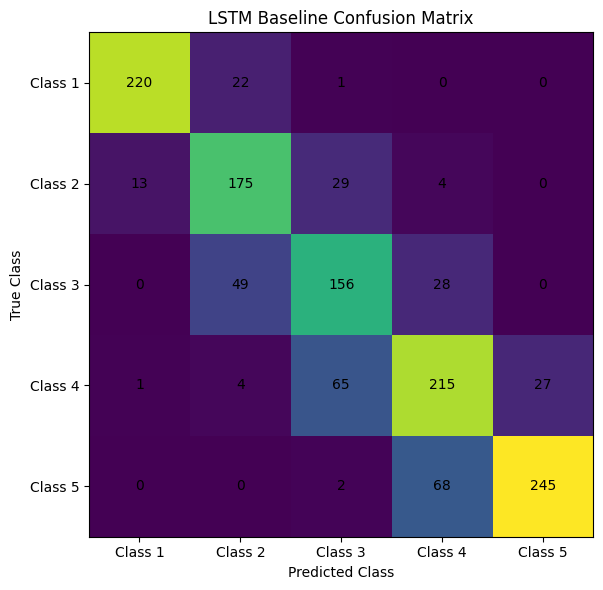

In [103]:
baseline_lstm_cm = confusion_matrix(
    y_baseline_test_dl,
    baseline_lstm_predictions
)

fig, ax = plt.subplots(figsize=(7, 6))

ax.imshow(baseline_lstm_cm)

ax.set_title(
    "LSTM Baseline Confusion Matrix"
)

ax.set_xlabel("Predicted Class")
ax.set_ylabel("True Class")

ax.set_xticks(range(5))
ax.set_yticks(range(5))

ax.set_xticklabels(
    ["Class 1", "Class 2", "Class 3", "Class 4", "Class 5"]
)

ax.set_yticklabels(
    ["Class 1", "Class 2", "Class 3", "Class 4", "Class 5"]
)

for i in range(5):
    for j in range(5):
        ax.text(
            j,
            i,
            baseline_lstm_cm[i, j],
            ha="center",
            va="center"
        )

fig.tight_layout()

fig.savefig(
    FIGURES_DIR /
    "lstm_baseline_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

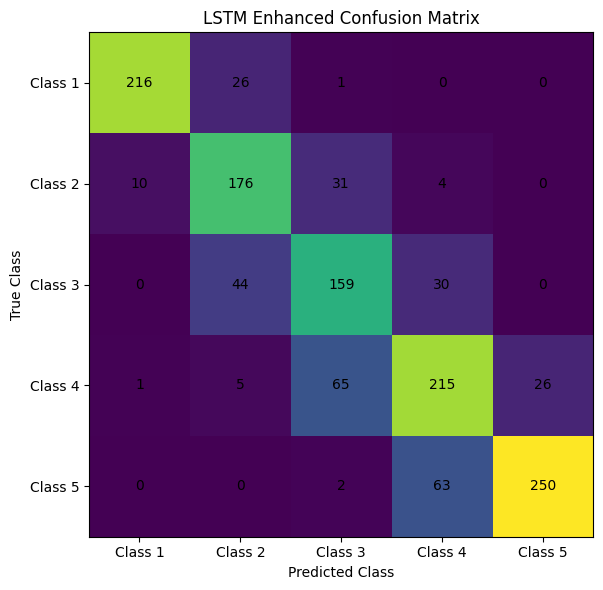

In [104]:
enhanced_lstm_cm = confusion_matrix(
    y_enhanced_test_dl,
    enhanced_lstm_predictions
)

fig, ax = plt.subplots(figsize=(7, 6))

ax.imshow(enhanced_lstm_cm)

ax.set_title(
    "LSTM Enhanced Confusion Matrix"
)

ax.set_xlabel("Predicted Class")
ax.set_ylabel("True Class")

ax.set_xticks(range(5))
ax.set_yticks(range(5))

ax.set_xticklabels(
    ["Class 1", "Class 2", "Class 3", "Class 4", "Class 5"]
)

ax.set_yticklabels(
    ["Class 1", "Class 2", "Class 3", "Class 4", "Class 5"]
)

for i in range(5):
    for j in range(5):
        ax.text(
            j,
            i,
            enhanced_lstm_cm[i, j],
            ha="center",
            va="center"
        )

fig.tight_layout()

fig.savefig(
    FIGURES_DIR /
    "lstm_enhanced_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

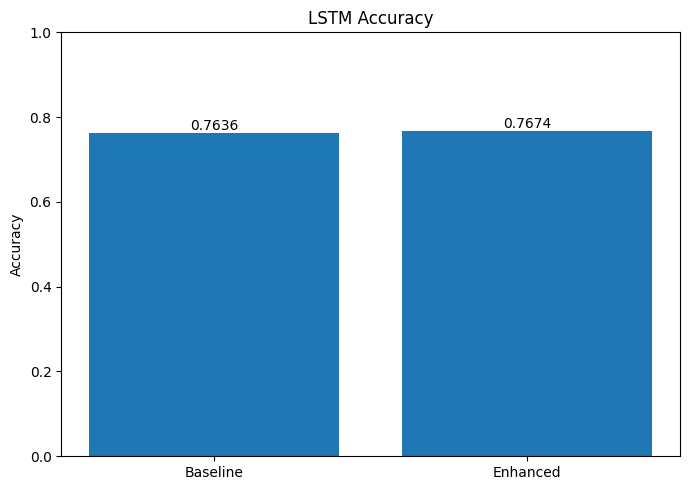

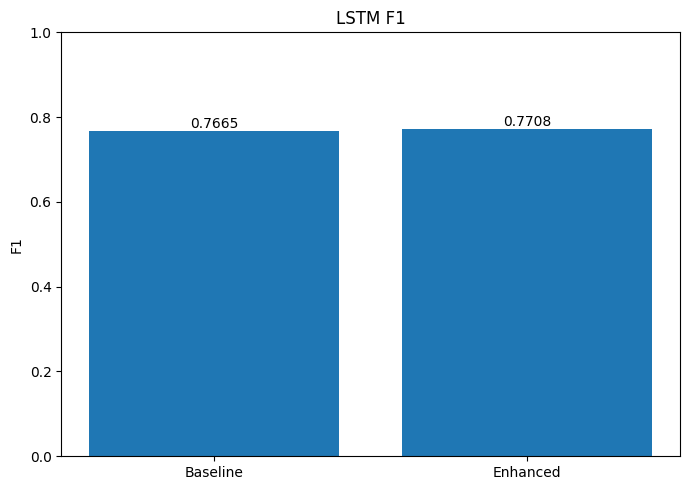

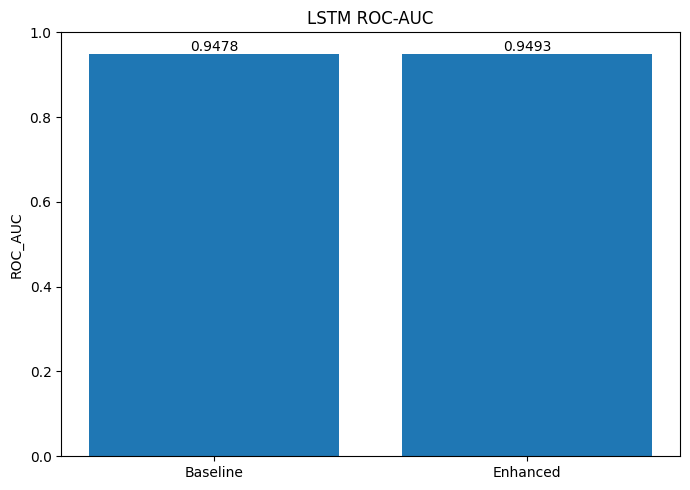

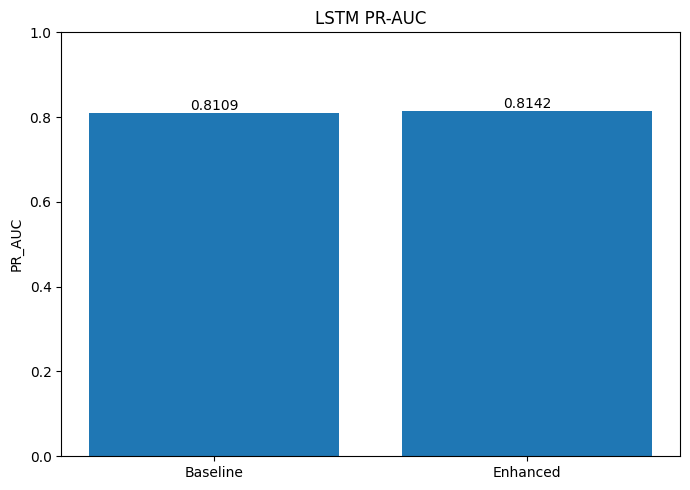

In [105]:
lstm_metrics = [
    ("Accuracy", "LSTM Accuracy"),
    ("F1", "LSTM F1"),
    ("ROC_AUC", "LSTM ROC-AUC"),
    ("PR_AUC", "LSTM PR-AUC")
]

for metric, title in lstm_metrics:

    fig, ax = plt.subplots(figsize=(7, 5))

    values = lstm_comparison[metric]

    ax.bar(
        lstm_comparison["Dataset"],
        values
    )

    ax.set_title(title)
    ax.set_ylabel(metric)
    ax.set_ylim(0, 1)

    for i, value in enumerate(values):
        ax.text(
            i,
            value,
            f"{value:.4f}",
            ha="center",
            va="bottom"
        )

    fig.tight_layout()

    filename = (
        "lstm_baseline_vs_enhanced_"
        + metric.lower()
        + ".png"
    )

    fig.savefig(
        FIGURES_DIR / filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

In [106]:
print("=" * 75)
print("FINAL LSTM LEAKAGE AUDIT")
print("=" * 75)

print("\nSequence length:", SEQUENCE_LENGTH)

print(
    "Baseline features:",
    LSTM_BASELINE_FEATURES
)

print(
    "Enhanced features:",
    LSTM_ENHANCED_FEATURES
)

print("\nTemporal structure:")
print("Input years: t-3, t-2, t-1")
print("Prediction year: t")

print("\nData split:")
print("Training years:", train_years)
print("Validation years:", validation_years)
print("Testing years:", test_years)

print("\nScaler:")
print("Fitted on training data only: YES")

print("\nTemporal leakage:")
print("Future test years used in training: NO")
print("Future validation years used in training: NO")

print("\nTest set:")
print("Used for training: NO")
print("Used for early stopping: NO")

print("\nBaseline/enhanced target population:")
print(
    "Same observations:",
    baseline_common_keys.equals(
        enhanced_common_keys
    )
)

print("\nFINAL LSTM AUDIT: PASSED")

FINAL LSTM LEAKAGE AUDIT

Sequence length: 3
Baseline features: ['GROUP_HOMICIDE', 'GROUP_SEXUAL_VIOLENCE', 'GROUP_KIDNAPPING_ABDUCTION', 'GROUP_ROBBERY_DACOITY', 'GROUP_PUBLIC_VIOLENCE', 'GROUP_PROPERTY_CRIME']
Enhanced features: ['GROUP_HOMICIDE', 'GROUP_SEXUAL_VIOLENCE', 'GROUP_KIDNAPPING_ABDUCTION', 'GROUP_ROBBERY_DACOITY', 'GROUP_PUBLIC_VIOLENCE', 'GROUP_PROPERTY_CRIME', 'PREV_YEAR_TOTAL_CRIME']

Temporal structure:
Input years: t-3, t-2, t-1
Prediction year: t

Data split:
Training years: [np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008)]
Validation years: [np.int64(2009), np.int64(2010)]
Testing years: [np.int64(2011), np.int64(2012)]

Scaler:
Fitted on training data only: YES

Temporal leakage:
Future test years used in training: NO
Future validation years used in training: NO

Test set:
Used for training: NO
Used for early stopping: NO

Baseline/enhanced target population:
Same observations: True

FINAL LSTM AUDIT: PASSED


In [107]:
# FINAL DL COMPARISON — MLP vs LSTM

dl_comparison = pd.DataFrame([
    {
        "Model": "MLP",
        "Dataset": "Baseline",
        "Split": "Random Stratified 80/20",
        **baseline_results
    },
    {
        "Model": "MLP",
        "Dataset": "Enhanced",
        "Split": "Random Stratified 80/20",
        **enhanced_results
    },
    {
        "Model": "LSTM",
        "Dataset": "Baseline",
        "Split": "Chronological",
        **baseline_lstm_results
    },
    {
        "Model": "LSTM",
        "Dataset": "Enhanced",
        "Split": "Chronological",
        **enhanced_lstm_results
    }
])

display(dl_comparison)

dl_comparison.to_csv(
    RESULTS_DIR / "final_dl_model_comparison.csv",
    index=False
)

print("\nSaved:")
print(RESULTS_DIR / "final_dl_model_comparison.csv")


,Model,Dataset,Split,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,MLP,Baseline,Random Stratified 80/20,0.905571,0.908374,0.905571,0.905526,0.990725,0.962934
1,MLP,Enhanced,Random Stratified 80/20,0.900136,0.902274,0.900136,0.899692,0.990587,0.962921
2,LSTM,Baseline,Chronological,0.763595,0.773046,0.763595,0.766522,0.947779,0.810875
3,LSTM,Enhanced,Chronological,0.767372,0.778027,0.767372,0.770822,0.949271,0.814182



Saved:
d:\Major_Project\Crime_Analysis\outputs\tables\final_dl_model_comparison.csv


In [108]:
# BEST DL MODEL

for metric in ["Accuracy", "F1", "ROC_AUC", "PR_AUC"]:
    idx = dl_comparison[metric].idxmax()
    row = dl_comparison.loc[idx]

    print(
        f"{metric}: "
        f"{row['Model']} - {row['Dataset']} "
        f"= {row[metric]:.4f}"
    )

Accuracy: MLP - Baseline = 0.9056
F1: MLP - Baseline = 0.9055
ROC_AUC: MLP - Baseline = 0.9907
PR_AUC: MLP - Baseline = 0.9629


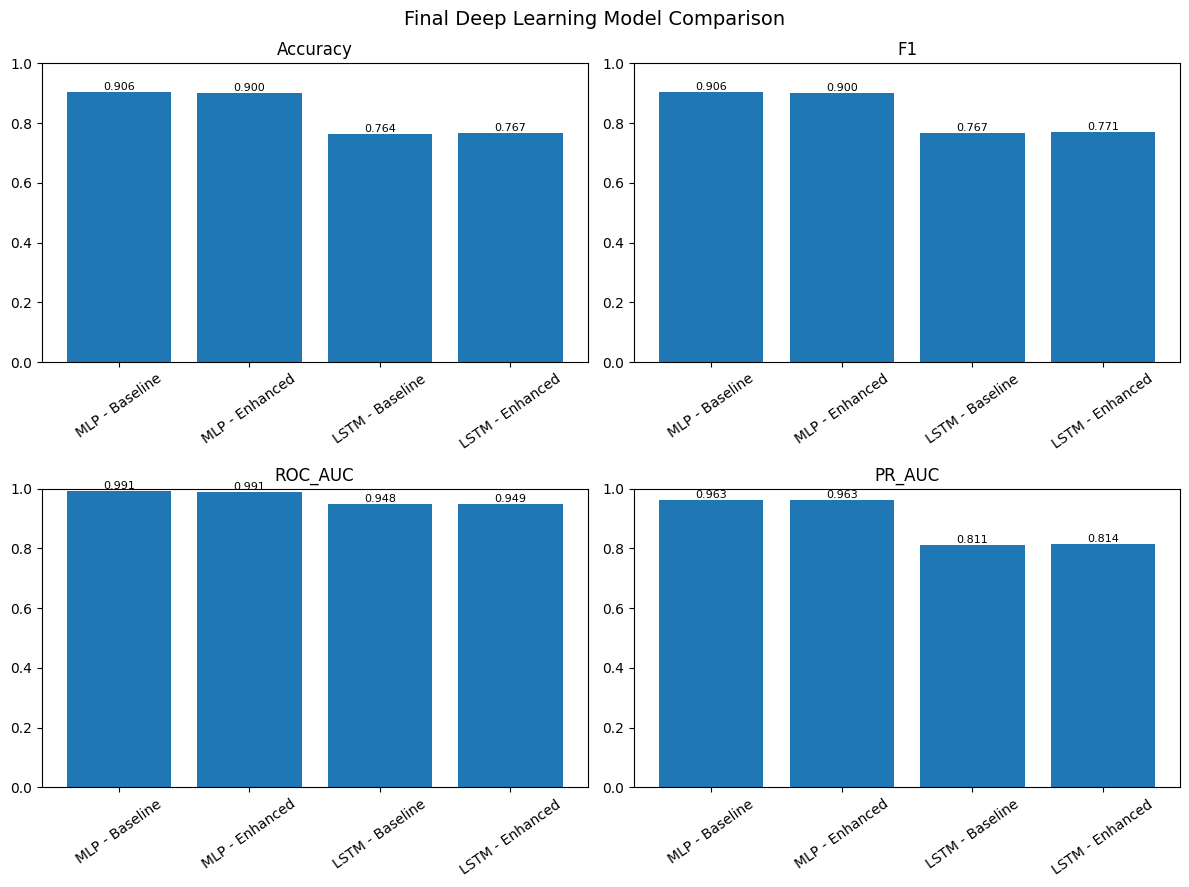

In [109]:
# FINAL DL METRIC COMPARISON

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

metrics = [
    ("Accuracy", axes[0, 0]),
    ("F1", axes[0, 1]),
    ("ROC_AUC", axes[1, 0]),
    ("PR_AUC", axes[1, 1])
]

labels = (
    dl_comparison["Model"]
    + " - "
    + dl_comparison["Dataset"]
)

for metric, ax in metrics:
    values = dl_comparison[metric]

    ax.bar(labels, values)
    ax.set_title(metric)
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=35)

    for i, value in enumerate(values):
        ax.text(
            i,
            value,
            f"{value:.3f}",
            ha="center",
            va="bottom",
            fontsize=8
        )

fig.suptitle(
    "Final Deep Learning Model Comparison",
    fontsize=14
)

fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "final_dl_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

In [110]:
import importlib
import deep_learning_models

importlib.reload(deep_learning_models)

from deep_learning_models import build_gru

print("GRU loaded successfully.")

GRU loaded successfully.


In [111]:
baseline_gru_model = build_gru(
    input_shape=(
        X_baseline_train_scaled.shape[1],
        X_baseline_train_scaled.shape[2]
    ),
    learning_rate=0.001
)

enhanced_gru_model = build_gru(
    input_shape=(
        X_enhanced_train_scaled.shape[1],
        X_enhanced_train_scaled.shape[2]
    ),
    learning_rate=0.001
)

print("Baseline GRU input:",
      X_baseline_train_scaled.shape[1:])

print("Enhanced GRU input:",
      X_enhanced_train_scaled.shape[1:])

Baseline GRU input: (3, 6)
Enhanced GRU input: (3, 7)


In [112]:
gru_early_stopping_baseline = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
    verbose=1
)

baseline_gru_history = baseline_gru_model.fit(
    X_baseline_train_scaled,
    y_baseline_train_dl,
    validation_data=(
        X_baseline_val_scaled,
        y_baseline_val_dl
    ),
    epochs=100,
    batch_size=32,
    callbacks=[gru_early_stopping_baseline],
    shuffle=False,
    verbose=1
)


gru_early_stopping_enhanced = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
    verbose=1
)

enhanced_gru_history = enhanced_gru_model.fit(
    X_enhanced_train_scaled,
    y_enhanced_train_dl,
    validation_data=(
        X_enhanced_val_scaled,
        y_enhanced_val_dl
    ),
    epochs=100,
    batch_size=32,
    callbacks=[gru_early_stopping_enhanced],
    shuffle=False,
    verbose=1
)

Epoch 1/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.3828 - loss: 1.3902 - val_accuracy: 0.4754 - val_loss: 1.1041
Epoch 2/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5073 - loss: 1.0532 - val_accuracy: 0.7092 - val_loss: 0.8570
Epoch 3/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6058 - loss: 0.8746 - val_accuracy: 0.7392 - val_loss: 0.6822
Epoch 4/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6655 - loss: 0.7674 - val_accuracy: 0.7338 - val_loss: 0.6246
Epoch 5/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6934 - loss: 0.7142 - val_accuracy: 0.7315 - val_loss: 0.6070
Epoch 6/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7059 - loss: 0.6885 - val_accuracy: 0.7438 - val_loss: 0.5920
Epoch 7/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7114 - loss: 0.6823 - val_accuracy: 0.7454 - val_loss: 0.5797
Epoch 8/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7185 - loss: 0.6612 - val_accuracy: 0.7485 - v

In [113]:
baseline_gru_probabilities = baseline_gru_model.predict(
    X_baseline_test_scaled,
    verbose=0
)

baseline_gru_predictions = np.argmax(
    baseline_gru_probabilities,
    axis=1
)

enhanced_gru_probabilities = enhanced_gru_model.predict(
    X_enhanced_test_scaled,
    verbose=0
)

enhanced_gru_predictions = np.argmax(
    enhanced_gru_probabilities,
    axis=1
)


baseline_gru_results = evaluate_lstm(
    y_baseline_test_dl,
    baseline_gru_predictions,
    baseline_gru_probabilities
)

enhanced_gru_results = evaluate_lstm(
    y_enhanced_test_dl,
    enhanced_gru_predictions,
    enhanced_gru_probabilities
)

gru_comparison = pd.DataFrame([
    {
        "Model": "GRU",
        "Dataset": "Baseline",
        **baseline_gru_results
    },
    {
        "Model": "GRU",
        "Dataset": "Enhanced",
        **enhanced_gru_results
    }
])

display(gru_comparison)

gru_comparison.to_csv(
    RESULTS_DIR / "gru_baseline_vs_enhanced_results.csv",
    index=False
)

print(
    "Saved:",
    RESULTS_DIR / "gru_baseline_vs_enhanced_results.csv"
)

,Model,Dataset,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,GRU,Baseline,0.757553,0.768694,0.757553,0.760953,0.947896,0.806434
1,GRU,Enhanced,0.759819,0.768027,0.759819,0.762350,0.949281,0.813876


Saved: d:\Major_Project\Crime_Analysis\outputs\tables\gru_baseline_vs_enhanced_results.csv


In [114]:
final_dl_comparison = pd.concat(
    [
        dl_comparison,
        gru_comparison.assign(
            Split="Chronological"
        )
    ],
    ignore_index=True
)

display(final_dl_comparison)

final_dl_comparison.to_csv(
    RESULTS_DIR / "final_dl_model_comparison.csv",
    index=False
)

,Model,Dataset,Split,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,MLP,Baseline,Random Stratified 80/20,0.905571,0.908374,0.905571,0.905526,0.990725,0.962934
1,MLP,Enhanced,Random Stratified 80/20,0.900136,0.902274,0.900136,0.899692,0.990587,0.962921
2,LSTM,Baseline,Chronological,0.763595,0.773046,0.763595,0.766522,0.947779,0.810875
3,LSTM,Enhanced,Chronological,0.767372,0.778027,0.767372,0.770822,0.949271,0.814182
4,GRU,Baseline,Chronological,0.757553,0.768694,0.757553,0.760953,0.947896,0.806434
5,GRU,Enhanced,Chronological,0.759819,0.768027,0.759819,0.762350,0.949281,0.813876


In [115]:
for metric in [
    "Accuracy",
    "F1",
    "ROC_AUC",
    "PR_AUC"
]:
    idx = final_dl_comparison[metric].idxmax()
    row = final_dl_comparison.loc[idx]

    print(
        f"{metric}: "
        f"{row['Model']} - {row['Dataset']} "
        f"= {row[metric]:.4f}"
    )

Accuracy: MLP - Baseline = 0.9056
F1: MLP - Baseline = 0.9055
ROC_AUC: MLP - Baseline = 0.9907
PR_AUC: MLP - Baseline = 0.9629


In [116]:
# FINAL ML + DL COMPARISON

# Keep ONLY traditional ML models here
traditional_ml_final = all_models_final[
    ~all_models_final["Model"].isin(["MLP"])
].copy()

traditional_ml_final["Framework"] = "Traditional ML"
traditional_ml_final["Split"] = "Random Stratified 80/20"

# Deep learning models: MLP + LSTM + GRU
deep_learning_final = final_dl_comparison.copy()
deep_learning_final["Framework"] = "Deep Learning"

# Combine correctly
final_all_models = pd.concat(
    [
        traditional_ml_final,
        deep_learning_final
    ],
    ignore_index=True
)

# Keep required columns
final_all_models = final_all_models[
    [
        "Framework",
        "Model",
        "Dataset",
        "Split",
        "Accuracy",
        "F1",
        "ROC_AUC",
        "PR_AUC"
    ]
]

# Sort by Accuracy
final_all_models = final_all_models.sort_values(
    "Accuracy",
    ascending=False
).reset_index(drop=True)

# Save
final_all_models.to_csv(
    RESULTS_DIR / "final_ml_dl_model_comparison.csv",
    index=False
)

display(final_all_models)

print(
    "Saved:",
    RESULTS_DIR / "final_ml_dl_model_comparison.csv"
)

,Framework,Model,Dataset,Split,Accuracy,F1,ROC_AUC,PR_AUC
0,Deep Learning,MLP,Baseline,Random Stratified 80/20,0.905571,0.905526,0.990725,0.962934
1,Deep Learning,MLP,Enhanced,Random Stratified 80/20,0.900136,0.899692,0.990587,0.962921
2,Traditional ML,One-vs-Rest Gaussian NB,Baseline,Random Stratified 80/20,0.805027,0.804945,0.904131,0.713147
3,Traditional ML,One-vs-Rest Gaussian NB,Enhanced,Random Stratified 80/20,0.789402,0.790195,0.891499,0.676858
4,Traditional ML,Naive Bayes,Baseline,Random Stratified 80/20,0.780571,0.784318,0.958431,0.824002
5,Traditional ML,Extra Tree,Baseline,Random Stratified 80/20,0.773777,0.774087,0.858204,0.654216
6,Traditional ML,Extra Tree,Enhanced,Random Stratified 80/20,0.769022,0.768002,0.855257,0.649021
7,Deep Learning,LSTM,Enhanced,Chronological,0.767372,0.770822,0.949271,0.814182
8,Deep Learning,LSTM,Baseline,Chronological,0.763595,0.766522,0.947779,0.810875
9,Traditional ML,Naive Bayes,Enhanced,Random Stratified 80/20,0.760870,0.764251,0.951899,0.805271


Saved: d:\Major_Project\Crime_Analysis\outputs\tables\final_ml_dl_model_comparison.csv


In [117]:
# BEST MODEL BY METRIC

for metric in [
    "Accuracy",
    "F1",
    "ROC_AUC",
    "PR_AUC"
]:
    idx = final_all_models[metric].idxmax()
    row = final_all_models.loc[idx]

    print(
        f"{metric}: "
        f"{row['Model']} - {row['Dataset']} "
        f"({row['Framework']}) = "
        f"{row[metric]:.4f}"
    )

Accuracy: MLP - Baseline (Deep Learning) = 0.9056
F1: MLP - Baseline (Deep Learning) = 0.9055
ROC_AUC: MLP - Baseline (Deep Learning) = 0.9907
PR_AUC: MLP - Baseline (Deep Learning) = 0.9629


In [118]:
# FINAL MODEL RANKING

ranking_metrics = [
    "Accuracy",
    "F1",
    "ROC_AUC",
    "PR_AUC"
]

final_ranking = final_all_models.copy()

final_ranking["Mean_Score"] = (
    final_ranking[ranking_metrics].mean(axis=1)
)

final_ranking = final_ranking.sort_values(
    "Mean_Score",
    ascending=False
).reset_index(drop=True)

final_ranking.insert(
    0,
    "Overall_Rank",
    range(1, len(final_ranking) + 1)
)

display(final_ranking)

final_ranking.to_csv(
    RESULTS_DIR / "final_model_ranking.csv",
    index=False
)

print(
    "Best overall by mean of Accuracy/F1/ROC-AUC/PR-AUC:"
)

print(
    final_ranking.iloc[0][
        [
            "Model",
            "Dataset",
            "Framework",
            "Mean_Score"
        ]
    ]
)

,Overall_Rank,Framework,Model,Dataset,Split,Accuracy,F1,ROC_AUC,PR_AUC,Mean_Score
0,1,Deep Learning,MLP,Baseline,Random Stratified 80/20,0.905571,0.905526,0.990725,0.962934,0.941189
1,2,Deep Learning,MLP,Enhanced,Random Stratified 80/20,0.900136,0.899692,0.990587,0.962921,0.938334
2,3,Traditional ML,Naive Bayes,Baseline,Random Stratified 80/20,0.780571,0.784318,0.958431,0.824002,0.836831
3,4,Deep Learning,LSTM,Enhanced,Chronological,0.767372,0.770822,0.949271,0.814182,0.825412
4,5,Deep Learning,LSTM,Baseline,Chronological,0.763595,0.766522,0.947779,0.810875,0.822193
5,6,Deep Learning,GRU,Enhanced,Chronological,0.759819,0.762350,0.949281,0.813876,0.821331
6,7,Traditional ML,Naive Bayes,Enhanced,Random Stratified 80/20,0.760870,0.764251,0.951899,0.805271,0.820573
7,8,Deep Learning,GRU,Baseline,Chronological,0.757553,0.760953,0.947896,0.806434,0.818209
8,9,Traditional ML,One-vs-Rest Gaussian NB,Baseline,Random Stratified 80/20,0.805027,0.804945,0.904131,0.713147,0.806813
9,10,Traditional ML,One-vs-Rest Gaussian NB,Enhanced,Random Stratified 80/20,0.789402,0.790195,0.891499,0.676858,0.786989


Best overall by mean of Accuracy/F1/ROC-AUC/PR-AUC:
Model                   MLP
Dataset            Baseline
Framework     Deep Learning
Mean_Score         0.941189
Name: 0, dtype: object


In [119]:
# FINAL EXPERIMENT CONCLUSION

best_accuracy = final_all_models.loc[
    final_all_models["Accuracy"].idxmax()
]

best_f1 = final_all_models.loc[
    final_all_models["F1"].idxmax()
]

best_roc = final_all_models.loc[
    final_all_models["ROC_AUC"].idxmax()
]

best_pr = final_all_models.loc[
    final_all_models["PR_AUC"].idxmax()
]

print("FINAL CONCLUSION")
print("=" * 70)

print(
    f"Best Accuracy: {best_accuracy['Model']} "
    f"({best_accuracy['Dataset']}) = "
    f"{best_accuracy['Accuracy']:.4f}"
)

print(
    f"Best F1: {best_f1['Model']} "
    f"({best_f1['Dataset']}) = "
    f"{best_f1['F1']:.4f}"
)

print(
    f"Best ROC-AUC: {best_roc['Model']} "
    f"({best_roc['Dataset']}) = "
    f"{best_roc['ROC_AUC']:.4f}"
)

print(
    f"Best PR-AUC: {best_pr['Model']} "
    f"({best_pr['Dataset']}) = "
    f"{best_pr['PR_AUC']:.4f}"
)

FINAL CONCLUSION
Best Accuracy: MLP (Baseline) = 0.9056
Best F1: MLP (Baseline) = 0.9055
Best ROC-AUC: MLP (Baseline) = 0.9907
Best PR-AUC: MLP (Baseline) = 0.9629


In [120]:
# FINAL OUTPUT INVENTORY

print("TABLE OUTPUTS")
print("=" * 60)

for path in sorted(RESULTS_DIR.glob("*.csv")):
    print(path.name)

print("\nFIGURE OUTPUTS")
print("=" * 60)

for path in sorted(FIGURES_DIR.glob("*.png")):
    print(path.name)

TABLE OUTPUTS
76_file_inventory.csv
all_models_final_comparison.csv
availability_report.csv
baseline_vs_enhanced_classification_reports.csv
basepaper_column_keyword_search.csv
basepaper_final_model_comparison.csv
basepaper_model_results.csv
basepaper_violent_crime_mapping.csv
candidate_dominant_crime_distribution.csv
candidate_five_level_distribution.csv
canonical_feature_mapping.csv
categorical_column_audit.csv
column_classification_report.csv
compact_final_model_results.csv
crime_column_group_mapping.csv
crime_column_reduction_summary.csv
crime_group_mapping.csv
crime_group_summary.csv
crime_grouping_audit.csv
crime_grouping_mapping_candidates.csv
crime_parent_child_validation.csv
dataset_sample_evidence.csv
dataset_semantic_profile.csv
eda_correlation_matrix.csv
eda_crime_family_availability.csv
eda_crime_family_feature_counts.csv
eda_dataset_profile.csv
eda_features_by_mean_observed.csv
eda_high_zero_features.csv
eda_missing_value_summary.csv
eda_numeric_descriptive_statistics.csv


In [121]:
# ============================================================
# FIX FINAL ML + DL MODEL COMPARISON
# MLP = DEEP LEARNING ONLY
# ============================================================

import pandas as pd

RESULTS_DIR = PROJECT_ROOT / "outputs" / "tables"

# Load the existing final comparison
final_all_models = pd.read_csv(
    RESULTS_DIR / "final_ml_dl_model_comparison.csv"
)

# Remove incorrectly duplicated MLP rows from Traditional ML
final_all_models = final_all_models[
    ~(
        (final_all_models["Framework"] == "Traditional ML") &
        (final_all_models["Model"] == "MLP")
    )
].copy()

# Make sure every MLP is classified as Deep Learning
final_all_models.loc[
    final_all_models["Model"] == "MLP",
    "Framework"
] = "Deep Learning"

# Correct framework for sequence/deep-learning models
final_all_models.loc[
    final_all_models["Model"].isin(["LSTM", "GRU"]),
    "Framework"
] = "Deep Learning"

# Correct framework for traditional models
final_all_models.loc[
    final_all_models["Model"].isin(
        ["Naive Bayes", "Extra Tree", "One-vs-Rest Gaussian NB"]
    ),
    "Framework"
] = "Traditional ML"

# Remove accidental duplicate rows
final_all_models = final_all_models.drop_duplicates(
    subset=["Framework", "Model", "Dataset", "Split"]
).copy()

# Put Deep Learning first, then Traditional ML
framework_order = {
    "Deep Learning": 0,
    "Traditional ML": 1
}

final_all_models["_framework_order"] = (
    final_all_models["Framework"].map(framework_order)
)

final_all_models = (
    final_all_models
    .sort_values(
        ["_framework_order", "Model", "Dataset"],
        ascending=[True, True, True]
    )
    .drop(columns="_framework_order")
    .reset_index(drop=True)
)

# Save corrected final comparison
final_all_models.to_csv(
    RESULTS_DIR / "final_ml_dl_model_comparison.csv",
    index=False
)

# ------------------------------------------------------------
# Recalculate final model ranking
# ------------------------------------------------------------

ranking_metrics = ["Accuracy", "F1", "ROC_AUC", "PR_AUC"]

final_ranking = final_all_models.copy()

final_ranking["Mean_Score"] = final_ranking[ranking_metrics].mean(axis=1)

final_ranking = final_ranking.sort_values(
    "Mean_Score",
    ascending=False
).reset_index(drop=True)

final_ranking["Rank"] = range(1, len(final_ranking) + 1)

final_ranking.to_csv(
    RESULTS_DIR / "final_model_ranking.csv",
    index=False
)

# Thesis-ready results
final_all_models.to_csv(
    RESULTS_DIR / "thesis_ready_final_results.csv",
    index=False
)

# Display corrected table
display(final_all_models)

,Framework,Model,Dataset,Split,Accuracy,F1,ROC_AUC,PR_AUC
0,Deep Learning,GRU,Baseline,Chronological,0.757553,0.760953,0.947896,0.806434
1,Deep Learning,GRU,Enhanced,Chronological,0.759819,0.762350,0.949281,0.813876
2,Deep Learning,LSTM,Baseline,Chronological,0.763595,0.766522,0.947779,0.810875
3,Deep Learning,LSTM,Enhanced,Chronological,0.767372,0.770822,0.949271,0.814182
4,Deep Learning,MLP,Baseline,Random Stratified 80/20,0.905571,0.905526,0.990725,0.962934
5,Deep Learning,MLP,Enhanced,Random Stratified 80/20,0.900136,0.899692,0.990587,0.962921
6,Traditional ML,Extra Tree,Baseline,Random Stratified 80/20,0.773777,0.774087,0.858204,0.654216
7,Traditional ML,Extra Tree,Enhanced,Random Stratified 80/20,0.769022,0.768002,0.855257,0.649021
8,Traditional ML,Naive Bayes,Baseline,Random Stratified 80/20,0.780571,0.784318,0.958431,0.824002
9,Traditional ML,Naive Bayes,Enhanced,Random Stratified 80/20,0.760870,0.764251,0.951899,0.805271


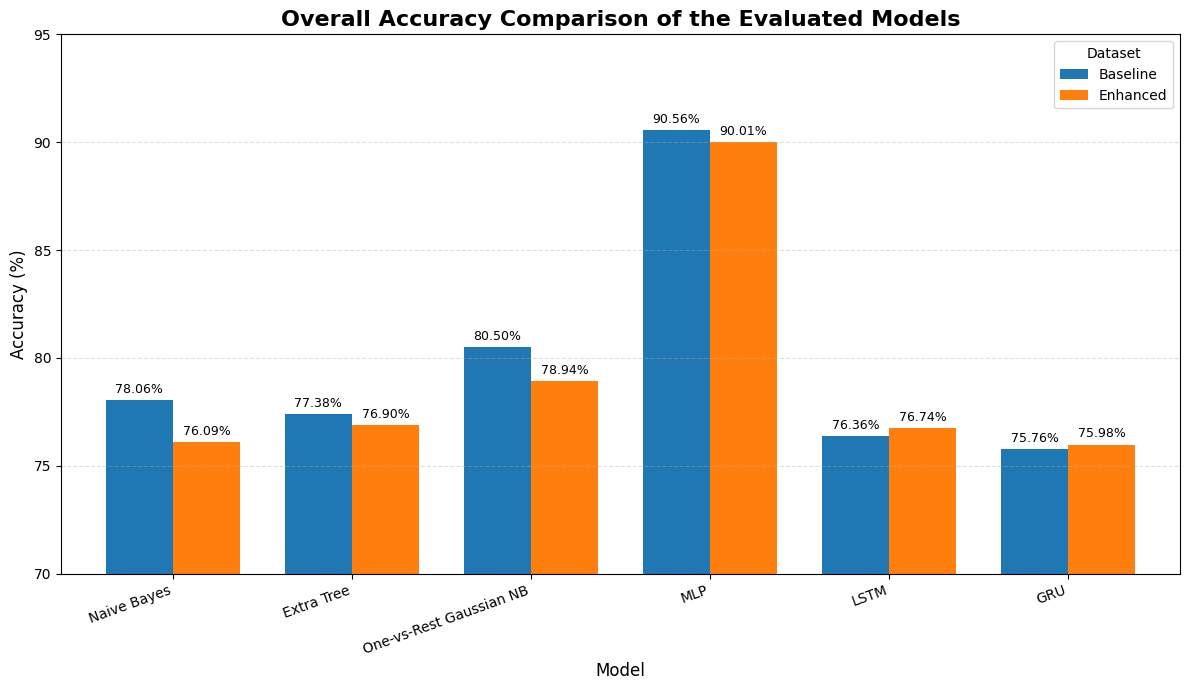

Figure 2 saved:
d:\Major_Project\Crime_Analysis\outputs\figures\figure_2_overall_accuracy_comparison.png


In [122]:
# ============================================================
# FIGURE 2 — OVERALL ACCURACY COMPARISON
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Paths
RESULTS_DIR = PROJECT_ROOT / "outputs" / "tables"
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"

# Load final corrected ML + DL results
results = pd.read_csv(
    RESULTS_DIR / "final_ml_dl_model_comparison.csv"
)

# Required model order
model_order = [
    "Naive Bayes",
    "Extra Tree",
    "One-vs-Rest Gaussian NB",
    "MLP",
    "LSTM",
    "GRU"
]

# Keep only required models
plot_data = results[
    results["Model"].isin(model_order)
].copy()

# Convert accuracy to percentage
plot_data["Accuracy_Percent"] = plot_data["Accuracy"] * 100

# Create pivot table
accuracy_table = plot_data.pivot_table(
    index="Model",
    columns="Dataset",
    values="Accuracy_Percent",
    aggfunc="first"
).reindex(model_order)

# Plot
fig, ax = plt.subplots(figsize=(12, 7))

accuracy_table[["Baseline", "Enhanced"]].plot(
    kind="bar",
    ax=ax,
    width=0.75
)

# Labels and title
ax.set_title(
    "Overall Accuracy Comparison of the Evaluated Models",
    fontsize=16,
    fontweight="bold"
)

ax.set_xlabel("Model", fontsize=12)
ax.set_ylabel("Accuracy (%)", fontsize=12)

# X-axis
ax.set_xticklabels(
    model_order,
    rotation=20,
    ha="right"
)

# Accuracy range
ax.set_ylim(70, 95)

# Grid
ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

# Legend
ax.legend(
    title="Dataset",
    loc="upper right"
)

# Add accuracy values above bars
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f%%",
        padding=3,
        fontsize=9
    )

plt.tight_layout()

# Save Figure 2
figure2_path = FIGURES_DIR / "figure_2_overall_accuracy_comparison.png"

plt.savefig(
    figure2_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure 2 saved:")
print(figure2_path)